# Práctica 1 | Predicción Multiclase de Riesgo Cardiovascular en Población Adulta

## PLANTEAMIENTO DEL PROBLEMA

Las enfermedades cardiovasculares son una de las mayores amenazas para la salud pública global y una de las principales causas de morbimortalidad a nivel mundial.
Para combatir este problema, la detección temprana y la estratificación precisa del nivel de riesgo individual son pilares esenciales que permiten aplicar intervenciones preventivas adaptadas a cada paciente y optimizar la gestión de los recursos en los sistemas de salud.
Conscientes de esta necesidad, el equipo médico e investigador del Hospital Morales Meseguer ha puesto en marcha un proyecto estratégico orientado al desarrollo de herramientas predictivas de vanguardia. 
La iniciativa nace con el objetivo de ofrecer una solución integral basada en datos clínicos que transforme la evaluación del riesgo cardiovascular en la práctica médica diaria, mejorando directamente el diagnóstico y el seguimiento del paciente.
Para ello, el equipo médico pone a disposición de este proyecto una cohorte clínica con 2.254 registros de pacientes y 28 variables sociodemográficas, clínicas, analíticas y de estilo de vida para clasificar a los pacientes en tres niveles de riesgo cardiovascular (Clase 0: Bajo Riesgo, Clase 1: Riesgo Moderado y Clase 2: Alto Riesgo).

## 1. Configuración del entorno y reproducibilidad

Antes de nada, se fijan la **semilla** que se reutilizará en todas las técnicas y las librerías.

**Nota:** Este cuaderno se encuentra dentro del proyecto en `notebooks/`, los datos en `data/` y el código reutilizable en `src/`. Todas las rutas se construyen a partir de la raíz del proyecto que llamremos `RAIZ`.

In [1]:
import random
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
import math
from scipy import stats

# Importante para que se muestren los gráficos en el cuaderno
%matplotlib inline

# Raíz del proyecto
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

# Datos del proyecto
RUTA_DATOS = RAIZ / 'data' / 'raw' / 'enfermedad_cardiovascular.csv'
assert RUTA_DATOS.exists(), f'No se encuentra el dataset en {RUTA_DATOS}'

# Semilla
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
print('Raíz del proyecto:', RAIZ.name)

Raíz del proyecto: MasterIA-ML01


## 2. Carga de datos

Del enunciado esperamos las siguientes variables:

| Tipo | Variable | Unidad / valores |
|---|---|---|
| **Objetivo** | `riesgo_cardiovascular` | 0 = bajo, 1 = moderado, 2 = alto |
| Numérica | `edad` | años cumplidos |
| Numérica | `presion_sistolica`, `presion_diastolica` | mmHg |
| Numérica | `colesterol_total`, `colesterol_hdl`, `colesterol_ldl`, `trigliceridos` | mg/dL |
| Numérica | `glucosa_ayunas` | mg/dL |
| Numérica | `indice_masa_corporal` | kg/m² |
| Numérica | `frecuencia_cardiaca_reposo` | latidos/min |
| Numérica | `horas_sueno_diarias` | horas/día |
| Numérica | `consumo_alcohol_semanal` | UBE/semana |
| Numérica | `anos_fumador` | años |
| Numérica | `proteina_c_reactiva` | mg/L |
| Numérica | `acido_urico` | mg/dL |
| Numérica | `clearance_creatinina` | mL/min |
| Numérica | `frecuencia_ejercicio_semanal` | días/semana |
| Numérica | `perimetro_cintura` | cm |
| Numérica | `hemoglobina_glicosilada` | % (HbA1c) |
| Booleana | `fumador_actual`, `hipertension_previa`, `diabetes_mellitus`, `tratamiento_estatinas`, `uso_antihipertensivos` | 1 = Sí, 0 = No |
| Nominal | `tipo_alimentacion` | Mediterránea, Occidental, Vegetariana, Baja en carbohidratos |
| Nominal | `nivel_actividad` | Sedentario, Ligeramente activo, Moderadamente activo, Muy activo |
| Nominal | `antecedentes_familiares_tipo` | Ninguno, Materno, Paterno, Ambos |

In [2]:
df = pd.read_csv(RUTA_DATOS)   # data/raw/enfermedad_cardiovascular.csv

print('Cantidad de filas y columnas:', df.shape)
df.head(10)

Cantidad de filas y columnas: (2254, 28)


,edad,presion_sistolica,presion_diastolica,colesterol_total,colesterol_hdl,colesterol_ldl,trigliceridos,glucosa_ayunas,indice_masa_corporal,frecuencia_cardiaca_reposo,...,hemoglobina_glicosilada,fumador_actual,hipertension_previa,diabetes_mellitus,tratamiento_estatinas,uso_antihipertensivos,tipo_alimentacion,nivel_actividad,antecedentes_familiares_tipo,riesgo_cardiovascular
0,57.4,192.0,78.9,371.24,62.6,149.1,245.6,NaN,30.4,95.1,...,5.41,1,1,1,0,1,Mediterránea,Moderadamente activo,Ninguno,2
1,51.7,131.2,80.0,270.20,35.4,NaN,173.8,137.5,29.7,85.3,...,6.11,0,1,0,1,1,Baja en carbohidratos,Ligeramente activo,Ambos,1
2,56.7,127.1,92.5,202.30,47.7,134.1,60.9,157.4,29.4,87.5,...,6.52,1,1,0,0,1,Baja en carbohidratos,Sedentario,Ninguno,2
3,54.9,112.8,97.9,179.20,53.9,137.9,174.4,92.0,28.6,47.4,...,4.06,0,1,0,0,1,Occidental,Ligeramente activo,Paterno,0
4,47.2,115.1,97.0,242.20,56.5,159.2,195.7,63.5,18.5,69.0,...,4.63,0,0,0,0,0,Occidental,Muy activo,Ninguno,0
5,55.5,136.0,76.6,214.50,51.1,134.3,230.7,105.6,28.8,85.5,...,6.38,0,1,1,0,0,Baja en carbohidratos,Sedentario,Paterno,1
6,48.5,115.1,96.4,194.00,48.2,147.5,199.2,92.6,15.4,103.6,...,6.22,0,0,0,0,0,Vegetariana,Sedentario,Ambos,1
7,60.9,132.1,92.4,181.40,41.7,156.0,163.6,98.7,31.2,103.7,...,6.25,1,0,1,1,0,Vegetariana,Sedentario,Ninguno,2
8,52.7,98.3,70.5,213.70,47.0,165.9,246.9,90.4,35.1,87.7,...,6.43,0,1,1,1,1,Occidental,Sedentario,Paterno,1
9,68.1,141.7,88.3,154.70,50.8,133.6,145.2,102.3,33.1,96.2,...,5.92,1,1,0,0,1,Baja en carbohidratos,Ligeramente activo,Paterno,1


In [3]:
# Configuramos pandas para que muestre todas las columnas sin truncar
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

df.head(10)

,edad,presion_sistolica,presion_diastolica,colesterol_total,colesterol_hdl,colesterol_ldl,trigliceridos,glucosa_ayunas,indice_masa_corporal,frecuencia_cardiaca_reposo,horas_sueno_diarias,consumo_alcohol_semanal,anos_fumador,proteina_c_reactiva,acido_urico,clearance_creatinina,frecuencia_ejercicio_semanal,perimetro_cintura,hemoglobina_glicosilada,fumador_actual,hipertension_previa,diabetes_mellitus,tratamiento_estatinas,uso_antihipertensivos,tipo_alimentacion,nivel_actividad,antecedentes_familiares_tipo,riesgo_cardiovascular
0,57.4,192.0,78.9,371.24,62.6,149.1,245.6,NaN,30.4,95.1,6.5,7.6,9.4,3.80,3.70,69.5,3.3,110.4,5.41,1,1,1,0,1,Mediterránea,Moderadamente activo,Ninguno,2
1,51.7,131.2,80.0,270.20,35.4,NaN,173.8,137.5,29.7,85.3,5.0,8.7,0.0,4.07,4.67,87.5,5.6,88.4,6.11,0,1,0,1,1,Baja en carbohidratos,Ligeramente activo,Ambos,1
2,56.7,127.1,92.5,202.30,47.7,134.1,60.9,157.4,29.4,87.5,8.7,9.7,20.8,3.39,7.15,100.6,1.2,123.8,6.52,1,1,0,0,1,Baja en carbohidratos,Sedentario,Ninguno,2
3,54.9,112.8,97.9,179.20,53.9,137.9,174.4,92.0,28.6,47.4,5.7,5.6,10.0,0.75,4.81,92.0,1.5,93.3,4.06,0,1,0,0,1,Occidental,Ligeramente activo,Paterno,0
4,47.2,115.1,97.0,242.20,56.5,159.2,195.7,63.5,18.5,69.0,6.7,-4.9,5.5,NaN,10.13,93.7,5.7,91.0,4.63,0,0,0,0,0,Occidental,Muy activo,Ninguno,0
5,55.5,136.0,76.6,214.50,51.1,134.3,230.7,105.6,28.8,85.5,NaN,6.4,17.3,2.00,5.61,64.8,1.6,79.7,6.38,0,1,1,0,0,Baja en carbohidratos,Sedentario,Paterno,1
6,48.5,115.1,96.4,194.00,48.2,147.5,199.2,92.6,15.4,103.6,8.0,0.3,0.0,4.11,7.25,78.1,5.9,95.7,6.22,0,0,0,0,0,Vegetariana,Sedentario,Ambos,1
7,60.9,132.1,92.4,181.40,41.7,156.0,163.6,98.7,31.2,103.7,NaN,5.9,6.1,1.85,6.88,94.1,2.6,124.3,6.25,1,0,1,1,0,Vegetariana,Sedentario,Ninguno,2
8,52.7,98.3,70.5,213.70,47.0,165.9,246.9,90.4,35.1,87.7,5.8,8.7,15.1,3.40,5.80,73.8,2.9,93.9,6.43,0,1,1,1,1,Occidental,Sedentario,Paterno,1
9,68.1,141.7,88.3,154.70,50.8,133.6,145.2,102.3,33.1,96.2,6.1,1.0,24.4,1.23,5.06,71.4,3.9,102.8,5.92,1,1,0,0,1,Baja en carbohidratos,Ligeramente activo,Paterno,1


In [4]:
print('Cantidad de Filas y columnas:', df.shape)
print('Nombre columnas:', df.columns)

Cantidad de Filas y columnas: (2254, 28)
Nombre columnas: Index(['edad', 'presion_sistolica', 'presion_diastolica', 'colesterol_total', 'colesterol_hdl', 'colesterol_ldl', 'trigliceridos', 'glucosa_ayunas', 'indice_masa_corporal',
       'frecuencia_cardiaca_reposo', 'horas_sueno_diarias', 'consumo_alcohol_semanal', 'anos_fumador', 'proteina_c_reactiva', 'acido_urico', 'clearance_creatinina', 'frecuencia_ejercicio_semanal',
       'perimetro_cintura', 'hemoglobina_glicosilada', 'fumador_actual', 'hipertension_previa', 'diabetes_mellitus', 'tratamiento_estatinas', 'uso_antihipertensivos', 'tipo_alimentacion',
       'nivel_actividad', 'antecedentes_familiares_tipo', 'riesgo_cardiovascular'],
      dtype='object')


El fichero tiene **2.254 registros y 28 columnas**: 27 predictores y la variable objetivo. Se puede apreciar:
* Hay valores ausentes (`NaN`). 
* Tambien es de resaltar que la edad tiene decimales aunque en las instrucciones dice *años cumplidos*.
* Vemos que `colesterol_hdl` y `trigliceridos` tienen valores negativos cuando deberían ser todos positivos.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2254 entries, 0 to 2253
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   edad                          2254 non-null   float64
 1   presion_sistolica             2254 non-null   float64
 2   presion_diastolica            2254 non-null   float64
 3   colesterol_total              2254 non-null   float64
 4   colesterol_hdl                2254 non-null   float64
 5   colesterol_ldl                2119 non-null   float64
 6   trigliceridos                 2254 non-null   float64
 7   glucosa_ayunas                2142 non-null   float64
 8   indice_masa_corporal          2254 non-null   float64
 9   frecuencia_cardiaca_reposo    2254 non-null   float64
 10  horas_sueno_diarias           2074 non-null   float64
 11  consumo_alcohol_semanal       2254 non-null   float64
 12  anos_fumador                  2254 non-null   float64
 13  pro

El dataset consta de 28 atributos en total: 1 variable objetivo (target) y 27 variables de entrada (predictores).

### Variable Objetivo (Target)
**riesgo_cardiovascular**: Variable entera (int64) que clasifica a cada paciente según tres niveles de riesgo:
  -	0: Bajo riesgo.
  - 1: Riesgo moderado.
  - 2: Alto riesgo.


### Variables de Entrada (27 Predictores)
#### Variables Numéricas `float64` (19)
* Desde `0 edad` hasta `18 hemoglobina_glicosilada`.

#### Variables Booleanas / Binarias `int64` (5) (Valores 1: Sí, 0: No)
*	fumador_actual, hipertension_previa, diabetes_mellitus *(diabetes  tipo 2)*, tratamiento_estatinas, uso_antihipertensivos

#### Variables Nominales / Categóricas `object` (3)
*	tipo_alimentacion: Mediterránea, Occidental, Vegetariana, Baja en carbohidratos.
*	nivel_actividad: Sedentario, Ligeramente activo, Moderadamente activo, Muy activo.
*	antecedentes_familiares_tipo: Ninguno, Materno, Paterno, Ambos.

Para no repetir listas de columnas en todo el cuaderno, definimos aquí los grupos de variables.

In [6]:
TARGET = 'riesgo_cardiovascular'

ETIQUETAS_RIESGO = {0: '0 - bajo', 1: '1 - moderado', 2: '2 - alto'}

COLS_NUMERICAS = [
    'edad', 'presion_sistolica', 'presion_diastolica', 'colesterol_total',
    'colesterol_hdl', 'colesterol_ldl', 'trigliceridos', 'glucosa_ayunas',
    'indice_masa_corporal', 'frecuencia_cardiaca_reposo', 'horas_sueno_diarias',
    'consumo_alcohol_semanal', 'anos_fumador', 'proteina_c_reactiva',
    'acido_urico', 'clearance_creatinina', 'frecuencia_ejercicio_semanal',
    'perimetro_cintura', 'hemoglobina_glicosilada',
]
COLS_BOOLEANAS = [
    'fumador_actual', 'hipertension_previa', 'diabetes_mellitus',
    'tratamiento_estatinas', 'uso_antihipertensivos',
]
COLS_NOMINALES = ['tipo_alimentacion', 'nivel_actividad', 'antecedentes_familiares_tipo']

# Comprobación: los grupos y el target cubren exactamente las columnas del CSV
print(f'{len(COLS_NUMERICAS)} numéricas, {len(COLS_BOOLEANAS)} booleanas, '
      f'{len(COLS_NOMINALES)} nominales y 1 objetivo')

df.info()

19 numéricas, 5 booleanas, 3 nominales y 1 objetivo
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2254 entries, 0 to 2253
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   edad                          2254 non-null   float64
 1   presion_sistolica             2254 non-null   float64
 2   presion_diastolica            2254 non-null   float64
 3   colesterol_total              2254 non-null   float64
 4   colesterol_hdl                2254 non-null   float64
 5   colesterol_ldl                2119 non-null   float64
 6   trigliceridos                 2254 non-null   float64
 7   glucosa_ayunas                2142 non-null   float64
 8   indice_masa_corporal          2254 non-null   float64
 9   frecuencia_cardiaca_reposo    2254 non-null   float64
 10  horas_sueno_diarias           2074 non-null   float64
 11  consumo_alcohol_semanal       2254 non-null   float64
 12  anos_fumad

Los tipos son coherentes con la información del enunciado: hay 19 numéricas (`float64`), las booleanas y el target son `int64` y las nominales son texto (`object`). Si una columna numérica hubiera salido como texto (`object`), sería señal de que contiene algo raro, como etiquetas o códigos de error. El recuento de no nulos ya delata **cuatro columnas con ausentes**: `colesterol_ldl`, `glucosa_ayunas`, `horas_sueno_diarias` y `proteina_c_reactiva`.

In [7]:
df.isnull().sum()

edad                              0
presion_sistolica                 0
presion_diastolica                0
colesterol_total                  0
colesterol_hdl                    0
colesterol_ldl                  135
trigliceridos                     0
glucosa_ayunas                  112
indice_masa_corporal              0
frecuencia_cardiaca_reposo        0
horas_sueno_diarias             180
consumo_alcohol_semanal           0
anos_fumador                      0
proteina_c_reactiva             157
acido_urico                       0
clearance_creatinina              0
frecuencia_ejercicio_semanal      0
perimetro_cintura                 0
hemoglobina_glicosilada           0
fumador_actual                    0
hipertension_previa               0
diabetes_mellitus                 0
tratamiento_estatinas             0
uso_antihipertensivos             0
tipo_alimentacion                 0
nivel_actividad                   0
antecedentes_familiares_tipo      0
riesgo_cardiovascular       

In [8]:
df.duplicated().sum()

np.int64(0)

## 3. Análisis exploratorio de datos (EDA)

Vamos a estudiar los siguientes tipos de valores:

1. **Valores imposibles**: errores de captura (por ejemplo, colesterol negativo).
2. **Inconsistencias entre variables**: valores posibles por separado que, juntos, son incompatibles (por ejemplo, años de fumador > edad).
3. **Valores clínicamente extremos**: pueden ser pacientes reales y graves. (No son errores por definición, pero habría que hablarlos con el experto).

### 3.1 Estudio de las variables numéricas

In [9]:
# Analizamos algunos estadísticos asociados a los datos numéricos.
# Transponemos el resultado con .T (para facilitar la lectura visual) y vemos ausentes.
descriptivos = df[COLS_NUMERICAS].describe().T
descriptivos['ausentes'] = df[COLS_NUMERICAS].isna().sum()
print(descriptivos)
#descriptivos.round(2)

                               count        mean        std    min     25%     50%      75%     max  ausentes
edad                          2254.0   56.688287  14.448018   9.80   47.20   56.90   66.475  103.50         0
presion_sistolica             2254.0  132.315186  26.931005  52.20  115.30  129.65  143.900  231.36         0
presion_diastolica            2254.0   82.167524  13.084058  30.80   73.60   82.10   91.100  122.50         0
colesterol_total              2254.0  228.133829  62.725948  61.10  188.20  221.20  252.500  448.59         0
colesterol_hdl                2254.0   47.225200  15.991614  -8.80   36.70   47.30   58.200  106.30         0
colesterol_ldl                2119.0  135.638603  36.732756   6.10  111.40  135.50  161.400  266.70       135
trigliceridos                 2254.0  176.657391  72.735893 -35.70  133.05  170.00  208.100  452.70         0
glucosa_ayunas                2142.0  104.107330  24.939696  32.00   86.30  103.75  120.475  194.00       112
indice_mas

En esta tabla podemos observar:

- **Mínimos imposibles:** `colesterol_hdl` (−8,80), `trigliceridos` (−35,7) y `consumo_alcohol_semanal` (−5,0) tienen valores **negativos**, que no pueden existir.
- **Mínimos fuera de la población o implausibles:** `edad` mínima de 9,8 años en un estudio de adultos; `indice_masa_corporal` mínimo de 3,6 kg/m² (incompatible con la vida: una persona de 1,70 m pesaría unos 10 kg); `frecuencia_cardiaca_reposo` mínima de 25,8 lpm (lo habitual en reposo es entre 60 y 100 lpm, y hay deportistas de élite con valores de alrededor de 40 lpm, pero un ritmo de 25,8 lpm se considera bradicardia extrema y requiere atención médica urgente).
- **Máximos fuera de dominio:** `frecuencia_ejercicio_semanal` llega a 10 días por semana, cuando la semana tiene 7 días.
- **Máximos sospechosos:** los máximos de `presion_sistolica` (231,36), `colesterol_total` (448,59), `trigliceridos` (452,7) y `acido_urico` (12,29) están muy alejados del resto de la distribución: superan el percentil 75 en unas 3 veces el rango intercuartílico. Además, esos valores se repiten decenas de veces. Por separado son valores clínicamente posibles (crisis hipertensiva, hipercolesterolemia, hipertrigliceridemia grave, gota), así que la tabla no basta para decidir y se analizarán posteriormente.
- `edad` máxima de 103,5 años y `horas_sueno_diarias` entre 1,6 y 12,1 h: son valores extremos, pero posibles. No se tratan como error.

Visualizamos la distribución de las variables numericas, para comprobar la forma de la distribución, detectar valores atípicos, errores o asimetrías.

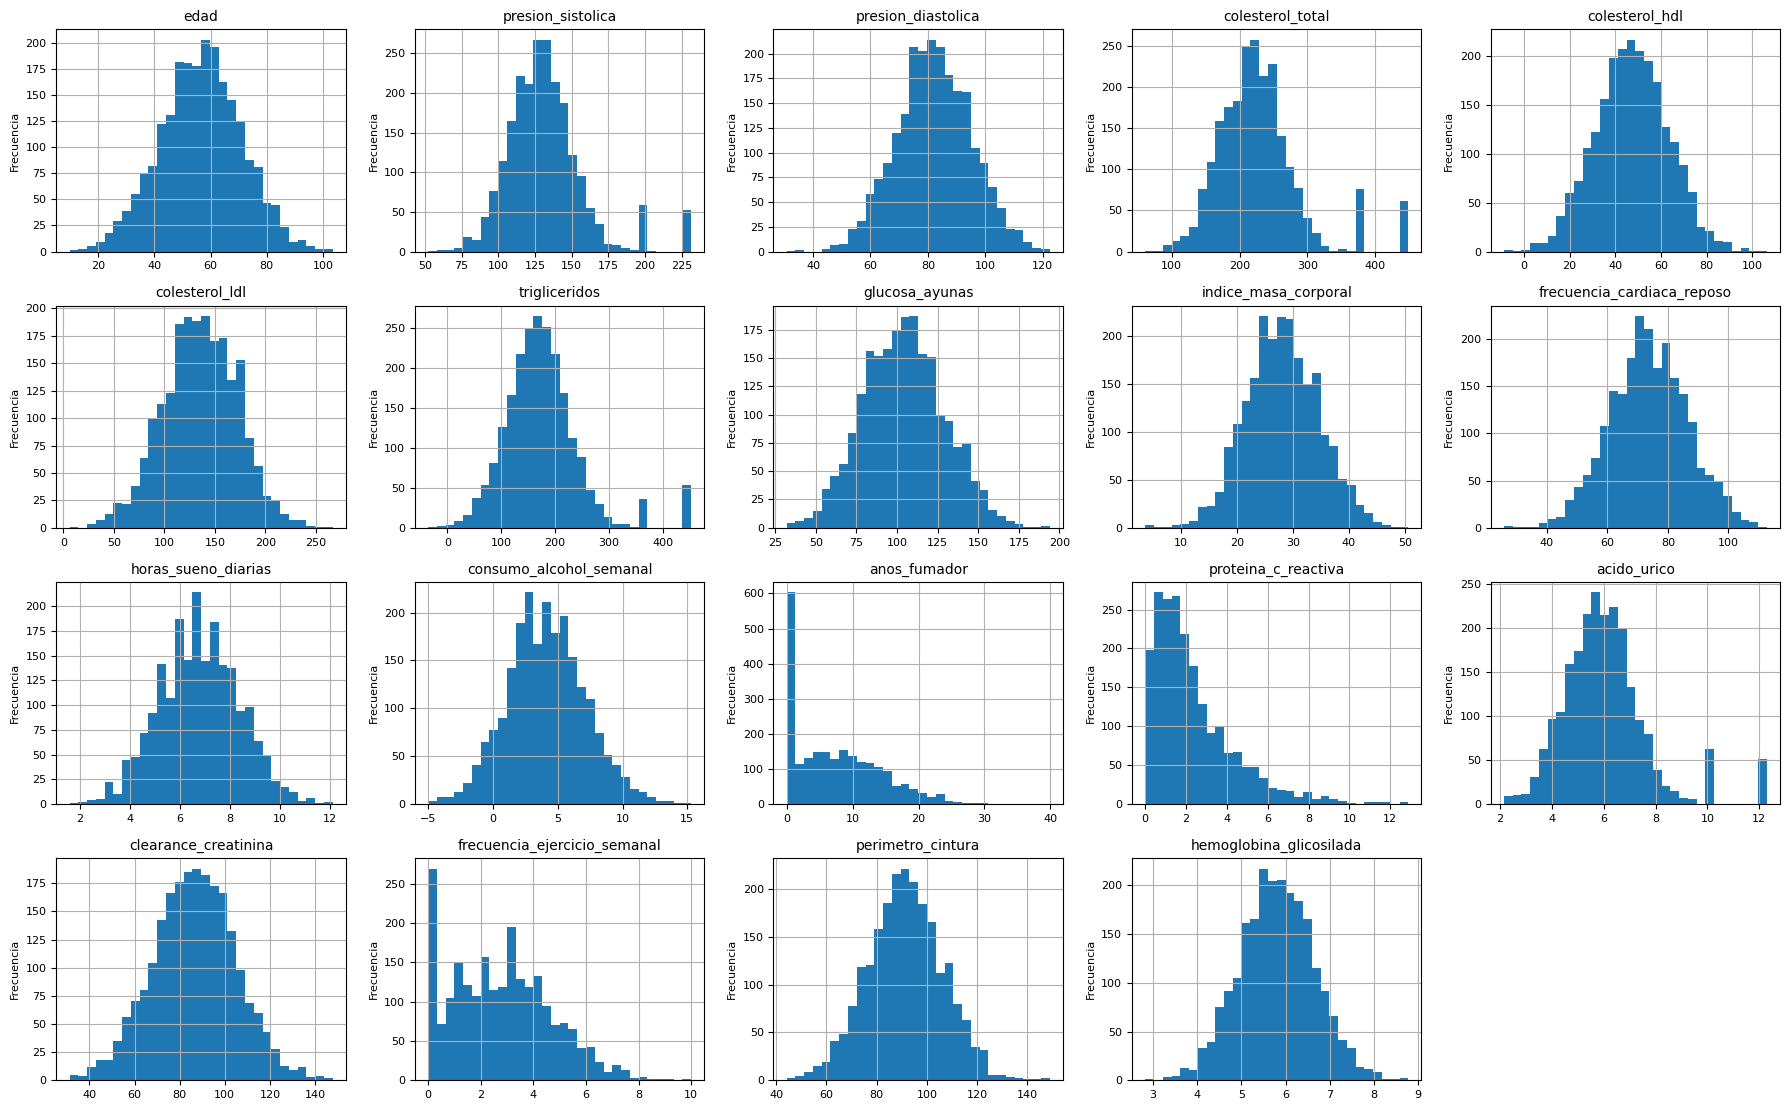

In [10]:
# Configuración de la cuadrícula
n_columnas = 5
n_filas = math.ceil(len(COLS_NUMERICAS) / n_columnas)

fig, axes = plt.subplots(
    nrows=n_filas,
    ncols=n_columnas,
    figsize=(18, n_filas * 2.8)
)

# Aplanar la matriz de ejes para recorrerla fácilmente
axes = axes.flatten()

# Generar los histogramas
for i, col in enumerate(COLS_NUMERICAS):
    df[col].hist(bins=30, ax=axes[i])

    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Frecuencia", fontsize=8)
    axes[i].tick_params(labelsize=8)

# Ocultar los gráficos vacíos
for ax in axes[len(COLS_NUMERICAS):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

A partir de la visualización de los histogramas, podemos indicar:

- La mayoría muestran una forma acampanada y simétrica: edad, presion_sistolica, presion_diastolica, colesterol_total, colesterol_hdl, colesterol_ldl, trigliceridos, glucosa_ayunas, indice_masa_corporal, frecuencia_cardiaca_reposo, horas_sueno_diarias, consumo_alcohol_semanal, acido_urico, clearance_creatinina, perimetro_cintura y hemoglobina_glicosilada.
- Cuatro de ellas (`presion_sistolica`, `colesterol_total`, `trigliceridos` y `acido_urico`) presentan además **picos aislados en la cola derecha**, separados de la masa principal de la distribución. Se analizan en el apartado 3.6.5.
- Se observa **asimetría hacia la derecha** en `anos_fumador`, `frecuencia_ejercicio_semanal` y `proteina_c_reactiva`, donde la gran mayoría de los registros se concentran en valores bajos (o cero) y existe una cola larga hacia la derecha. Es marcada en `proteina_c_reactiva` (asimetría de 1,59) y moderada en `anos_fumador` (0,72) y `frecuencia_ejercicio_semanal` (0,39).

También podemos observar que hay diferencias en las magnitudes y rangos de las variables, lo que invita a aplicar un proceso de normalización o estandarización más adelante.

Además, hay variables con valores extremos o repetidos en sus extremos que deben ser evaluados para determinar si son errores.

Calculamos para cada variable numérica, sus valores más frecuentes.

In [11]:
for col in COLS_NUMERICAS:
    print(col, df[col].nunique(), df[col].value_counts().head(5).to_dict())

edad 607 {69.4: 12, 60.9: 12, 56.7: 11, 54.9: 11, 59.2: 11}
presion_sistolica 755 {196.95: 59, 231.36: 53, 133.7: 10, 129.8: 9, 131.0: 9}
presion_diastolica 571 {84.9: 12, 80.0: 12, 78.6: 12, 94.4: 12, 84.5: 11}
colesterol_total 1223 {371.24: 74, 448.59: 61, 242.2: 8, 247.6: 7, 195.0: 7}
colesterol_hdl 657 {46.3: 14, 48.8: 13, 44.8: 11, 51.6: 11, 47.9: 11}
colesterol_ldl 1105 {125.0: 7, 136.6: 7, 142.1: 6, 134.6: 6, 179.4: 6}
trigliceridos 1351 {452.7: 54, 357.56: 36, 216.9: 6, 189.2: 6, 177.6: 6}
glucosa_ayunas 872 {83.2: 9, 88.2: 9, 118.1: 8, 102.6: 8, 75.4: 8}
indice_masa_corporal 319 {25.0: 22, 24.9: 20, 26.1: 20, 28.8: 19, 27.9: 19}
frecuencia_cardiaca_reposo 565 {74.8: 14, 72.6: 14, 69.8: 13, 75.8: 12, 72.3: 12}
horas_sueno_diarias 92 {6.8: 64, 6.7: 58, 6.2: 53, 6.0: 52, 7.6: 51}
consumo_alcohol_semanal 167 {2.6: 47, 2.4: 43, 2.9: 37, 3.7: 36, 4.9: 36}
anos_fumador 260 {0.0: 503, 12.2: 17, 6.5: 17, 10.1: 16, 7.7: 16}
proteina_c_reactiva 619 {1.79: 13, 1.35: 13, 1.17: 12, 0.74: 11

De este cálculo llaman la atención varias variables ya vistas en la visualización de las distribuciones, por tener valores que se repiten mucho:

- `presion_sistolica` tiene 755 valores distintos en 2254 registros (cada valor debería aparecer, de media, unas 3 veces). El primero (196.95) y el segundo valor (231.36, que además es el máximo) más repetidos aparecen 59 y 53 veces. Los siguientes se repiten, como mucho, 10 veces. Además, esos dos valores tienen 2 decimales mientras el resto solo tiene uno.
- Se observa un comportamiento análogo en `colesterol_total` (371.24 y 448.59 aparecen 74 y 61 veces; el siguiente, 8) y en `trigliceridos` (452.7 y 357.56 aparecen 54 y 36 veces; el siguiente, 6). En `colesterol_total` los dos valores tienen 2 decimales y el resto de la columna uno; en `trigliceridos` solo 357.56 tiene 2 decimales.
- También tenemos el caso de `acido_urico`, donde los dos primeros (10.13 y 12.29) se repiten 61 y 51 veces (el siguiente, 16), aunque aquí el número de decimales no los distingue, porque la mayoría de los valores de la columna ya tiene 2.
- Por último, tenemos los casos de `anos_fumador` y `frecuencia_ejercicio_semanal`, donde el valor más repetido (0.0 en ambos, 503 y 204 veces) es mucho mayor que el resto, aunque en estos casos hay muchos menos valores distintos y tiene sentido que ese valor aparezca más que los demás (no fumar, no hacer ejercicio).

### 3.2 Estudio de las variables booleanas y nominales

Para las variables booleanas comprobamos que solo toman 0 y 1. Para el caso de las nominales que solo contienen las categorías del enunciado, sin espacios sobrantes, mayúsculas distintas ni errores ortográficos. 

In [12]:
print('VARIABLES BOOLEANAS')
for col in COLS_BOOLEANAS:
    valores = df[col].unique().tolist()
    print(f'  {col:24s} valores = {valores}, % de 1s = {df[col].mean() * 100:.1f} %')

print('\nVARIABLES NOMINALES')
for col in COLS_NOMINALES:
    obtenidas = set(df[col].dropna().unique())
    print(f'  {col}: categorías obtenidas = {obtenidas}')
    print('   ', df[col].value_counts()) #, f'{col / df[col].value_counts() * 100:.1f %}')

print('\nVARIABLE OBJETIVO, valores:', sorted(df[TARGET].unique().tolist()))

VARIABLES BOOLEANAS
  fumador_actual           valores = [1, 0], % de 1s = 26.4 %
  hipertension_previa      valores = [1, 0], % de 1s = 36.7 %
  diabetes_mellitus        valores = [1, 0], % de 1s = 22.8 %
  tratamiento_estatinas    valores = [0, 1], % de 1s = 27.2 %
  uso_antihipertensivos    valores = [1, 0], % de 1s = 34.9 %

VARIABLES NOMINALES
  tipo_alimentacion: categorías obtenidas = {'Baja en carbohidratos', 'Occidental', 'Mediterránea', 'Vegetariana'}
    tipo_alimentacion
Occidental               881
Mediterránea             706
Baja en carbohidratos    349
Vegetariana              318
Name: count, dtype: int64
  nivel_actividad: categorías obtenidas = {'Sedentario', 'Muy activo', 'Moderadamente activo', 'Ligeramente activo'}
    nivel_actividad
Ligeramente activo      695
Sedentario              687
Moderadamente activo    563
Muy activo              309
Name: count, dtype: int64
  antecedentes_familiares_tipo: categorías obtenidas = {'Ambos', 'Materno', 'Ninguno', 'Paterno

Los dominios coinciden con lo indicado en el enunciado: booleanas en {0, 1}, nominales con sus cuatro categorías exactas y sin ausentes, y variable objetivo en {0, 1, 2}. Destacar que algunas categorías no están equilibradas.

### 3.3 Registros duplicados

In [13]:
print('Filas duplicadas:', df.duplicated().sum())

Filas duplicadas: 0


No hay duplicados

### 3.4 Valores ausentes (*missing*)

Antes de tomar ninguna decisión sobre qué hacer con los valores ausentes, hay que saber cuántos son, cómo se reparten y si la ausencia aporta información.

In [14]:
COLS_CON_NULOS = df.columns[df.isna().any()].tolist()

tabla_nulos = pd.DataFrame({
    'ausentes': df[COLS_CON_NULOS].isna().sum(),
    'porcentaje (%)': (df[COLS_CON_NULOS].isna().mean() * 100).round(2),
}).sort_values('ausentes', ascending=False)
display(tabla_nulos)

,ausentes,porcentaje (%)
horas_sueno_diarias,180,7.99
proteina_c_reactiva,157,6.97
colesterol_ldl,135,5.99
glucosa_ayunas,112,4.97


Podemos observar los siguientes valores missing:

1. Para la variable colesterol_ldl, faltan 135 registros.
2. Para la variable glucosa_ayunas tenemos 112 nulos.
3. La variable horas_sueno_diarias tiene 180 nulos.
4. La variable proteina_c_reactiva tiene 157 nulos.

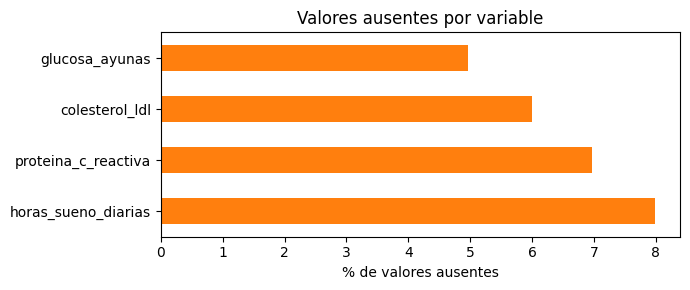

In [15]:
# Gráfico de barras con iformación de missing
fig, ax = plt.subplots(figsize=(7, 3))
tabla_nulos['porcentaje (%)'].plot.barh(ax=ax, color='tab:orange')
ax.set_xlabel('% de valores ausentes')
ax.set_title('Valores ausentes por variable')
plt.tight_layout()
plt.show()

Entre el 5 % y el 8 % de valores ausentes por variable. Parece un nivel bajo, lo que permite imputar.

La forma de tratar los ausentes depende de por qué faltan. Si faltan al azar, imputar no introduce sesgo. Si la ausencia depende de la clase o de otras variables, el propio hecho de faltar es información y convendría conservarlo (por ejemplo, con una variable indicadora). Lo comprobamos de tres formas: (1) porcentaje de ausentes por nivel de riesgo, con un contraste χ² de independencia; (2) si las ausencias de distintas variables coinciden en los mismos pacientes; (3) cuántos pacientes se perderían si se eliminaran las filas incompletas.

Para las variables que contienen tantos nulos, vamos a ver cómo se relacionan con la variable objetivo.

In [16]:
# El objetivo no debe tener ausentes: si los tuviera, hay que verlo.
assert df[TARGET].notna().all(), 'El objetivo tiene ausentes: revisar antes de continuar'

# Solo los predictores con ausentes (el objetivo queda fuera)
COLS_CON_NULOS = [c for c in df.columns if df[c].isna().any() and c != TARGET]

# (1) ¿La ausencia depende del nivel de riesgo?
filas = []
for col in COLS_CON_NULOS:
    falta = df[col].isna()
    pct_por_clase = falta.groupby(df[TARGET]).mean() * 100
    _, p_valor, _, _ = stats.chi2_contingency(pd.crosstab(falta, df[TARGET]))
    filas.append({
        'variable': col,
        '% ausentes riesgo 0': pct_por_clase[0],
        '% ausentes riesgo 1': pct_por_clase[1],
        '% ausentes riesgo 2': pct_por_clase[2],
        'p-valor (chi2)': p_valor,
    })
display(pd.DataFrame(filas).set_index('variable').round(3))

# (2) ¿Las ausencias coinciden en los mismos pacientes?
print('Correlación entre los indicadores de ausencia:')
display(df[COLS_CON_NULOS].isna().astype(int).corr().round(2))

# (3) ¿Cuántos pacientes tienen algún ausente?
nulos_por_fila = df[COLS_CON_NULOS].isna().sum(axis=1)
print('Pacientes según su número de ausentes:', nulos_por_fila.value_counts().sort_index().to_dict())
print(f'Pacientes con al menos un ausente: {(nulos_por_fila > 0).sum()} '
      f'({(nulos_por_fila > 0).mean() * 100:.1f} %)')
esperados_completos = np.prod(1 - df[COLS_CON_NULOS].isna().mean()) * len(df)
print(f'Pacientes completos: {(nulos_por_fila == 0).sum()} observados '
      f'frente a {esperados_completos:.0f} esperados si las ausencias fueran independientes')

,% ausentes riesgo 0,% ausentes riesgo 1,% ausentes riesgo 2,p-valor (chi2)
variable,,,,
colesterol_ldl,6.389,6.065,4.878,0.518
glucosa_ayunas,4.437,4.586,6.874,0.114
horas_sueno_diarias,8.252,7.692,7.761,0.896
proteina_c_reactiva,8.163,5.769,5.765,0.082


Correlación entre los indicadores de ausencia:


,colesterol_ldl,glucosa_ayunas,horas_sueno_diarias,proteina_c_reactiva
colesterol_ldl,1.00,-0.02,-0.03,0.03
glucosa_ayunas,-0.02,1.00,0.02,-0.01
horas_sueno_diarias,-0.03,0.02,1.00,-0.00
proteina_c_reactiva,0.03,-0.01,-0.00,1.00


Pacientes según su número de ausentes: {0: 1721, 1: 484, 2: 47, 3: 2}
Pacientes con al menos un ausente: 533 (23.6 %)
Pacientes completos: 1721 observados frente a 1724 esperados si las ausencias fueran independientes


- El porcentaje de ausentes es parecido en las tres clases de riesgo y ningún contraste χ² es significativo al 5 % (p entre 0,082 y 0,896). Las variables más cercanas a la significación son `proteina_c_reactiva` (8,2 % en riesgo bajo frente a 5,8 % en las otras dos; p = 0,082) y `glucosa_ayunas` (6,9 % en riesgo alto frente a 4,4–4,6 % en las otras dos; p = 0,114). Con cuatro contrastes, diferencias de este tamaño son compatibles con el azar.
- La correlación entre indicadores de ausencia es prácticamente nula (|r| ≤ 0,03) y hay 1.721 pacientes completos, casi exactamente los 1.724 que se esperarían si cada variable perdiera datos de forma independiente. Las ausencias no se agrupan.
- Aunque cada variable pierde solo entre el 5 % y el 8 %, las ausencias caen en pacientes distintos: 533 pacientes (23,6 %) tienen al menos un ausente. Eliminar esas filas supondría perder casi una cuarta parte del dataset.

Todo es compatible con un mecanismo MCAR: los contrastes no aportan evidencia de que la ausencia dependa del riesgo ni de otras ausencias (no se puede demostrar, solo no encontrar indicios en contra). 

Conclusión: se imputará en lugar de eliminar filas, y no hay indicios de que haga falta una variable indicadora de ausencia. El método de imputación (mediana, k-NN...) se decidirá posteriormente, solo con los datos de entrenamiento.

### 3.5 Validación automática con reglas

Para auditar el dataset de forma sistemática usamos `src/validador_datos_cardiovasculares_v1.py`, que implementa  tres niveles del estudio de validación. **No modificamos el DataFrame**: devuelve una tabla con cada incidencia (fila, variable, valor, gravedad, regla) y un resumen por regla.

Las gravedades son `ERROR` (imposible o inconsistente) y `REVISION` (posible pero sospechoso). Varias reglas del validador todavía **no están decididas** (por ejemplo, que la edad con decimales sea un error). Aquí se ejecuta tal cual para ver qué detecta.

In [17]:
# Validador (antes de las decisiones del EDA)
from src.validador_datos_cardiovasculares_v1 import validar_datos_cardiovasculares

incidencias, resumen_incidencias = validar_datos_cardiovasculares(df)

filas_error = incidencias.loc[incidencias['gravedad'] == 'ERROR', 'posicion'].nunique()
print(f'Incidencias totales: {len(incidencias)}')
print(f'Filas con al menos un ERROR: {filas_error} de {len(df)}')
resumen_incidencias


# Ruta de archivos de validacion
RUTA_VALIDACION = RAIZ / 'reports' / 'generated'
RUTA_VALIDACION.mkdir(parents=True, exist_ok=True)


# Guarda la tabla de incidencias y el resumen de una ejecución del validador
incidencias.to_csv(
    RUTA_VALIDACION / 'incidencias_validacion.csv', 
    index=False,
    encoding="utf-8-sig",
)
resumen_incidencias.to_csv(
    RUTA_VALIDACION / 'resumen_validacion.csv', 
    index=False,
    encoding="utf-8-sig",
)
print(f'Guardado en {RUTA_VALIDACION.relative_to(RAIZ)}: '
          f'incidencias_validacion.csv ({len(incidencias)} filas), resumen_validacion.csv')

Incidencias totales: 5347
Filas con al menos un ERROR: 2224 de 2254
Guardado en reports/generated: incidencias_validacion.csv (5347 filas), resumen_validacion.csv


Según el validador, **2.224 de los 2.254 pacientes (98,7 %) tienen algún error**. Es un porcentaje demasiado alto. Hay que revisar los resultados:

- **`EDAD_NO_ENTERA` (2.046) y `EJERCICIO_NO_ENTERO` (1.836).** Casi todos los valores de esas columnas tienen decimales. Cuando mas del 90 % de valores incumple una regla de formato, lo más probable es que la regla de formao no se ajuste a cómo se registró la variable. Lo contrario, que mas del 90 % sean errores, tiene poco sentido.
- **`SUEÑO_FUERA_RANGO` (180): es un falso positivo del validador.** Ningún valor de sueño está fuera de 0–24 h. Lo que ocurre es que esas incidencias son exactamente los 180 **ausentes** de la variable que hemos detectado anteriormente. 
- **`VALOR_NEGATIVO` (185):** 4 en HDL, 4 en triglicéridos y **177 en alcohol**.
- **Relaciones cruzadas:** 44 presiones con sistólica ≤ diastólica, 140 LDL mayores que el colesterol total y 559 LDL mayores que el colesterol no HDL.
- **`VALOR_CLINICO_EXTREMO` (188):** marcados para revisión, no son errores. Se tendrían que revisar caso a caso.

Actualizamos el validador con `src/validador_datos_cardiovasculares_v3.py`. Respecto a la versión anterior:

- **Detecta más tipos de problema:** valores inválidos por definición (`INVALIDO`), inconsistencias entre variables (`INCONSISTENCIA`), valores extremos (`EXTREMO`), alertas clínicas (`ALERTA_CLINICA`) y los valores repetidos de 3.6.5 (`ARTEFACTO`).
- **Cada incidencia lleva una columna `decision`** con el tratamiento previsto en el apartado 4: `corregir` (la limpieza la elimina), `conservar` (se mantiene a propósito y se registra) o `revision` (aviso informativo, no se modifica).
- **Los valores ausentes y los decimales de edad y ejercicio no cuentan como incidencias** por defecto (parámetros `incluir_ausentes` y `exigir_enteros`), porque son decisiones ya tomadas.
- **Los límites** se definen en `src/reglas_datos.py`, el mismo fichero que usará la limpieza del apartado 5.

Una incidencia no es un paciente: una misma celda puede incumplir dos reglas (por ejemplo, los 177 alcoholes negativos aparecen como `INVALIDO` y como `EXTREMO`), así que el total de incidencias supera al número de celdas afectadas. Por eso se muestra también el número de registros.

In [18]:
# Validador v3: auditoría de los datos originales (antes de las decisiones del EDA)
from src.validador_datos_cardiovasculares_v3 import validar_datos_cardiovasculares

# Ruta de archivos de validacion
RUTA_VALIDACION = RAIZ / 'reports' / 'generated'
RUTA_VALIDACION.mkdir(parents=True, exist_ok=True)

def auditar_datos(df, etiqueta, guardar=True, **kwargs):
    """Ejecuta el validador, muestra el resumen y guarda los CSV.

    etiqueta : sufijo de los ficheros (p. ej. 'v3_original', 'v3_limpio').
    kwargs   : se pasan al validador (exigir_enteros, incluir_ausentes).
    """
    incidencias, resumen = validar_datos_cardiovasculares(df, **kwargs)
    
    registros_afectados = incidencias['indice'].dropna().nunique()

    registros_corregir = (
        incidencias.loc[
            incidencias['decision'] == 'corregir',
            'indice'
        ]
        .nunique()
    )

    print(f"=== {etiqueta}: {len(df)} registros ===")
    print(f"Incidencias detectadas: {len(incidencias)}")
    print(f"Registros afectados: {registros_afectados}")
    print(f"Registros que requieren corrección: {registros_corregir}")

    if incidencias.empty:
        print("\nNo se han detectado incidencias.")
    else:
        print("\nPor decisión prevista:")
        display(
            incidencias.groupby('decision')
                       .size()
                       .rename('incidencias')
                       .to_frame()
        )

    print("\nResumen por variable y regla:")
    display(resumen)
    if guardar:
        for nombre, tabla in [
            ('incidencias', incidencias),
            ('resumen', resumen)
        ]:
            tabla.to_csv(
                RUTA_VALIDACION / f'{nombre}_validacion_{etiqueta}.csv',
                index=False,
                encoding='utf-8-sig'
            )

        print(
            f"\nGuardado en {RUTA_VALIDACION.relative_to(RAIZ)}: "
            f"incidencias_validacion_{etiqueta}.csv "
            f"({len(incidencias)} filas) y "
            f"resumen_validacion_{etiqueta}.csv"
        )

    return incidencias, resumen


incidencias, resumen = auditar_datos(df, 'v3_original')

display(incidencias.head(10))

=== v3_original: 2254 registros ===
Incidencias detectadas: 1888
Registros afectados: 1124
Registros que requieren corrección: 638

Por decisión prevista:


,incidencias
decision,
conservar,699
corregir,734
revision,455



Resumen por variable y regla:


,variable,tipo,regla,decision,casos
0,colesterol_ldl,INCONSISTENCIA,LDL > colesterol no-HDL,conservar,559
1,consumo_alcohol_semanal,EXTREMO,Inferior al límite de plausibilidad,revision,177
2,consumo_alcohol_semanal,INVALIDO,Valor negativo,corregir,177
3,colesterol_ldl,INCONSISTENCIA,LDL > colesterol total,conservar,140
4,colesterol_total,ARTEFACTO,Valor repetido anómalo,corregir,135
5,presion_sistolica,ALERTA_CLINICA,Sistólica > 180 mmHg,revision,121
6,acido_urico,ARTEFACTO,Valor repetido anómalo,corregir,112
7,presion_sistolica,ARTEFACTO,Valor repetido anómalo,corregir,112
8,trigliceridos,ARTEFACTO,Valor repetido anómalo,corregir,90
9,presion_sistolica,INCONSISTENCIA,Sistólica <= diastólica,corregir,44



Guardado en reports/generated: incidencias_validacion_v3_original.csv (1888 filas) y resumen_validacion_v3_original.csv


,indice,variable,valor,tipo,regla,decision,detalle
0,85,colesterol_hdl,-7.5,INVALIDO,Valor negativo,corregir,La variable no admite valores negativos.
1,900,colesterol_hdl,-8.8,INVALIDO,Valor negativo,corregir,La variable no admite valores negativos.
2,1231,colesterol_hdl,-0.3,INVALIDO,Valor negativo,corregir,La variable no admite valores negativos.
3,1679,colesterol_hdl,-3.7,INVALIDO,Valor negativo,corregir,La variable no admite valores negativos.
4,173,trigliceridos,-12.0,INVALIDO,Valor negativo,corregir,La variable no admite valores negativos.
5,1849,trigliceridos,-35.7,INVALIDO,Valor negativo,corregir,La variable no admite valores negativos.
6,2191,trigliceridos,-3.1,INVALIDO,Valor negativo,corregir,La variable no admite valores negativos.
7,2224,trigliceridos,-8.7,INVALIDO,Valor negativo,corregir,La variable no admite valores negativos.
8,4,consumo_alcohol_semanal,-4.9,INVALIDO,Valor negativo,corregir,La variable no admite valores negativos.
9,13,consumo_alcohol_semanal,-0.2,INVALIDO,Valor negativo,corregir,La variable no admite valores negativos.


### 3.6 Análisis detallado de anomalías

#### 3.6.1 Valores negativos
Las variables 'colesterol_hdl', 'trigliceridos' y 'consumo_alcohol_semanal' tienen valores negativos. Hay que ver si son errores de captura o nulos camuflados.

In [19]:
print('Análisis de variables negativas:')
for col in ['colesterol_hdl', 'trigliceridos', 'consumo_alcohol_semanal']:
    negativos = df.loc[df[col] < 0, col]
    print(f'{col}: {len(negativos)} negativos ({len(negativos) / len(df) * 100:.1f} %)'
          f' | mín = {negativos.min()} ')

Análisis de variables negativas:
colesterol_hdl: 4 negativos (0.2 %) | mín = -8.8 
trigliceridos: 4 negativos (0.2 %) | mín = -35.7 
consumo_alcohol_semanal: 177 negativos (7.9 %) | mín = -5.0 


De lo anteior podems indicar que:
- colesterol_hdl y triglicéridos: Son pocos casos (4 y 4) y aislados (0,2 % en ambos). Se comportan como errores puntuales de captura.
- La variable consumo_alcohol_semanal tiene muchos casos (177) siendo un 7,9 %. No parecen errores al azar.

Estudiamos los datos de consumo semanal de alcohol.

In [20]:
# Consumo semanal de alcohol
alcohol = pd.to_numeric(
    df['consumo_alcohol_semanal'],
    errors='coerce'
)

# Definición de intervalos
cortes = [-np.inf, 0, 2, 4, 6, np.inf]
etiquetas = ['negativo', '0 a <2', '2 a <4', '4 a <6', '6 o más']

# Clasificación por intervalos
tramo = pd.cut(
    alcohol,
    bins=cortes,
    labels=etiquetas,
    right=False
)

# Crear subconjunto con consumo y clase de riesgo conocidos
base = pd.DataFrame({
    'tramo': tramo,
    TARGET: df[TARGET]
}).dropna()

# Número de pacientes por intervalo
pacientes = (
    base['tramo']
    .value_counts()
    .reindex(etiquetas, fill_value=0)
)

# Número de pacientes de cada clase de riesgo
conteos_riesgo = pd.crosstab(
    base['tramo'],
    base[TARGET]
).reindex(
    index=etiquetas,
    columns=[0, 1, 2],
    fill_value=0
)

# Porcentajes dentro de cada intervalo
porcentajes = (
    conteos_riesgo
    .div(conteos_riesgo.sum(axis=1).replace(0, np.nan), axis=0)
    * 100
)

# Tabla final
tabla_alcohol = pd.DataFrame({
    'Pacientes': pacientes,
    '% riesgo bajo': porcentajes[0],
    '% riesgo moderado': porcentajes[1],
    '% riesgo alto': porcentajes[2]
})

tabla_alcohol.index.name = 'Consumo semanal (UBE)'

tabla_alcohol

,Pacientes,% riesgo bajo,% riesgo moderado,% riesgo alto
Consumo semanal (UBE),,,,
negativo,177,82.485876,15.819209,1.694915
0 a <2,330,71.818182,22.424242,5.757576
2 a <4,600,54.666667,32.000000,13.333333
4 a <6,553,46.473779,33.453888,20.072333
6 o más,594,26.767677,33.164983,40.067340


Con los datos negativos de consumo_alcohol_semanal podemos:
- Convertirlos en `NaN` e imputar con la media o la mediana asignaría un consumo moderado a 177 pacientes que presentan mayoritariamente un bajo riesgo.
- Recortarlos a 0 (es decir, asignarlos al grupo que no consume alcohol) conserva el sentido clínico.

Hay que decidir si convertir valores negativos de consumo_alcohol_semanal en `NaN` o recortarlos a 0.

#### 3.6.2 Valores positivos pero fisiológicamente imposibles o muy improbables

Para diferenciar entre valores imposibles o muy improbables habría que contar con la opinión de un experto del campo. De entre todos los valores extremos, con nuestro conocimiento, solo pondríamos los siguientes límites de corte entre extremo raro e imposible:
- indice_masa_corporal o IMC: presenta valores que no corresponden a ningún adulto vivo. Aunque no existe un mínimo absoluto universal establecido por la OMS, los valores menores de 10 son extremadamente bajos y podrían considerarse errores.
- frecuencia_cardiaca_reposo: Valores de menos de 30 lpm en reposo se pueden considerar Bradicardia extrema y requieren atención urgente. Aunque podrían ser reales, son tan poco probables en un estudio como el del proyecto que podríamos considerarlos valores imposibles.
- perimetro_cintura:  Valores de menos de 40 cm son extremadamente pequeños para un adulto.

In [21]:
# Umbrales
UMBRALES_FISIOLOGICOS = {
    'indice_masa_corporal': 10,
    'frecuencia_cardiaca_reposo': 30,
    'perimetro_cintura': 40,
}

filas = []
for col, umbral in UMBRALES_FISIOLOGICOS.items():
    bajo = df[col] < umbral
    filas.append({
        'variable': col,
        'umbral de revisión': umbral,
        'num por debajo': int(bajo.sum()),
        'num negativos': int((df[col] < 0).sum()),
        'valores más bajos': df[col].nsmallest(5).round(1).tolist(),
    })
pd.DataFrame(filas)

,variable,umbral de revisión,num por debajo,num negativos,valores más bajos
0,indice_masa_corporal,10,8,0,"[3.6, 4.9, 5.1, 6.4, 8.2]"
1,frecuencia_cardiaca_reposo,30,2,0,"[25.8, 26.6, 30.7, 32.6, 34.5]"
2,perimetro_cintura,40,0,0,"[44.2, 46.1, 48.0, 48.7, 48.8]"


Utilizaremos IMC < 10 y FC < 30 como límites operativos de plausibilidad extrema. Entre nuestros datos de perimetro_cintura no hay valores < 40.

### 3.6.3 Edad y frecuencia_ejercicio_semanal con decimales

La edad parece estar registrada como variable continua, no en años cumplidos como dice el enunciado. Marcar 2046 registros como erróneos no tiene sentido. Hay que decidir es si se acepta como continua o se trunca a años cumplidos.

Algo parecido sucede con frecuencia_ejercicio_semanal, donde 1836 valores (81 %) indican el número de días como variable continua. Podría interpretarse como días por semana en promedio, y en ese caso los decimales tienen sentido.

### 3.6.4 Frecuencia_ejercicio_semanal con valores 0 y mayores que 7

Análisis de Frecuencia_ejercicio_semanal:
Valores > 7: 41  ->  [7.1, 7.1, 7.1, 7.1, 7.1, 7.1, 7.1, 7.1, 7.2, 7.2, 7.2, 7.2, 7.2, 7.3, 7.3, 7.4, 7.4, 7.4, 7.4, 7.4, 7.5, 7.5, 7.5, 7.5, 7.5, 7.6, 7.6, 7.6, 7.8, 7.9, 7.9, 8.1, 8.1, 8.3, 8.3, 8.4, 8.5, 8.8, 9.0, 9.7, 10.0]
Valores = 0: 204


/var/folders/7g/_3fy35f92mj5dhkp3dwskljc0000gn/T/ipykernel_98849/484872593.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


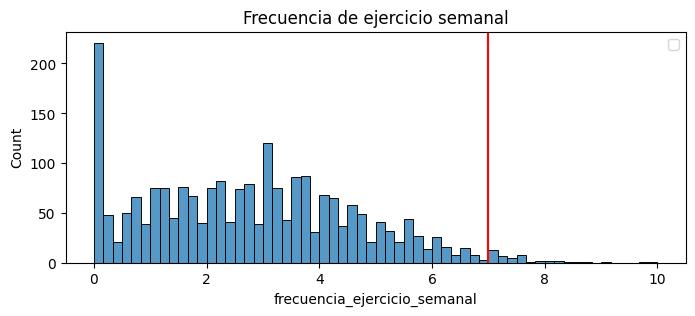

In [22]:
print('Análisis de Frecuencia_ejercicio_semanal:')
ejercicio = df['frecuencia_ejercicio_semanal']
print(f'Valores > 7: {(ejercicio > 7).sum()}  ->  {sorted(ejercicio[ejercicio > 7].tolist())}')
print(f'Valores = 0: {(ejercicio == 0).sum()}')

fig, ax = plt.subplots(figsize=(8, 3))
sns.histplot(ejercicio, bins=60, ax=ax)
ax.axvline(7, color='red')
ax.set_title('Frecuencia de ejercicio semanal')
ax.legend()
plt.show()

- 41 valores superan los 7 días de la semana. De ellos, la mayoría están entre 7,1 y 7,9.
- Hay un pico de 204 ceros al principio del histograma. Aquí el cero parece un valor válido y con sentido (no hace ejercicio).

#### 3.6.5 Valores repetidos en el extremo superior

Las variables `presion_sistolica`, `colesterol_total`, `trigliceridos` y `acido_urico` presentan, cada una, **dos valores que se repiten decenas de veces** (entre 36 y 74), mientras que ningún otro valor de esas columnas pasa de 16 repeticiones. Para decidir si son valores reales o introducidos por algún procedimiento comprobamos cuatro cosas: (1) cómo se ven en el histograma y dónde caen respecto al resto de la distribución; (2) si su nivel de riesgo difiere del general; (3) si los pacientes afectados se parecen al resto en las demás variables; (4) si tienen un formato distinto (número de decimales).

Los valores repetidos son los que aparecen más de 20 veces en cada una de estas cuatro variables.

{'presion_sistolica': [196.95, 231.36], 'colesterol_total': [371.24, 448.59], 'trigliceridos': [357.56, 452.7], 'acido_urico': [10.13, 12.29]}


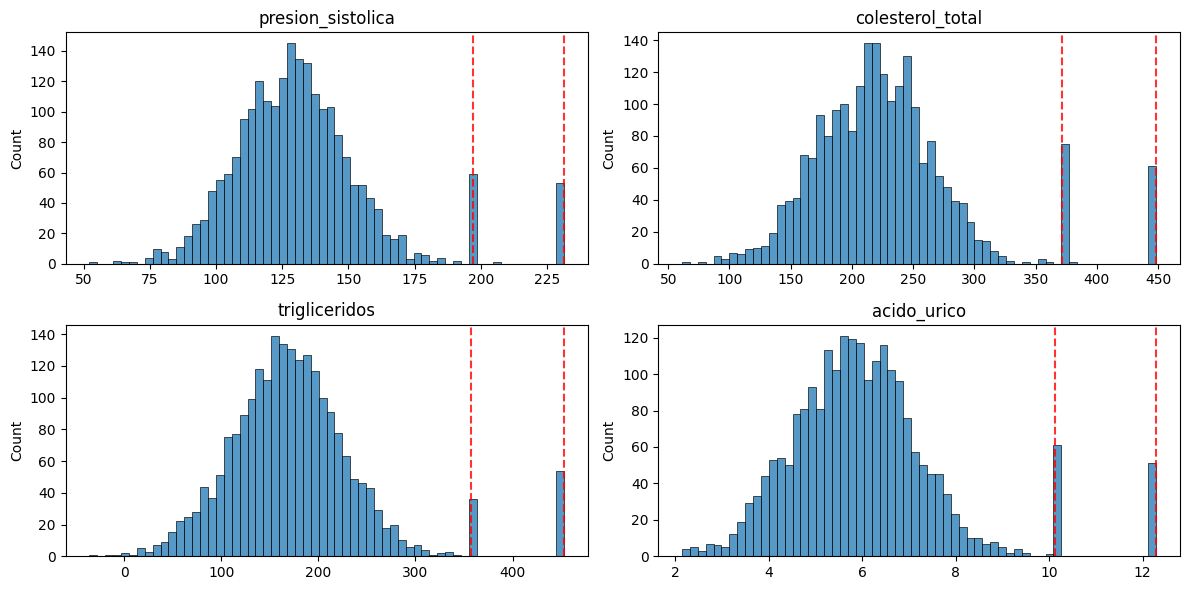

In [23]:
COLS_REPETIDOS = ['presion_sistolica', 'colesterol_total', 'trigliceridos', 'acido_urico']

# Mismo criterio que el análisis visual: valores que aparecen más de 20 veces
VALORES_REPETIDOS = {
    col: sorted(df[col].value_counts().loc[lambda x: x > 20].index)
    for col in COLS_REPETIDOS
}
print(VALORES_REPETIDOS)

fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for ax, (col, valores) in zip(axes.flatten(), VALORES_REPETIDOS.items()):
    sns.histplot(df[col], bins=60, ax=ax)
    for valor in valores:
        ax.axvline(valor, color='red', ls='--', alpha=0.8)
    ax.set_title(col)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

Las cuatro variables tienen una forma simétrica con dos picos aislados en la cola derecha (líneas rojas), separados de la masa principal de la distribución. Una población real no produce picos así: el resto de valores de cada columna se repite como mucho 16 veces, y las colas deberían descender de forma gradual, sin saltos.

In [24]:
def mas_de_un_decimal(valores):
    valores = np.asarray(valores, dtype=float)
    return ~np.isclose(valores * 10, np.round(valores * 10))

filas = []
for col, valores in VALORES_REPETIDOS.items():
    es_repetido = df[col].isin(valores)
    resto = df.loc[~es_repetido, col]
    # ¿El nivel de riesgo de estos pacientes difiere del de los demás?
    _, p_valor, _, _ = stats.chi2_contingency(pd.crosstab(es_repetido, df[TARGET]))
    for valor in valores:
        filas.append({
            'variable': col,
            'valor': valor,
            'veces': int((df[col] == valor).sum()),
            'máx. del resto': resto.max(),
            'z respecto al resto': (valor - resto.mean()) / resto.std(),
            'decimales (1 o 2)': 2 if mas_de_un_decimal([valor])[0] else 1,
            '% del resto con 2 decimales': mas_de_un_decimal(resto).mean() * 100,
            '% riesgo alto': (df.loc[df[col] == valor, TARGET] == 2).mean() * 100,
            'p-valor riesgo (chi2)': p_valor,
        })
display(pd.DataFrame(filas).round(2))

afectadas = pd.concat([df[c].isin(v) for c, v in VALORES_REPETIDOS.items()], axis=1)
print(f'Filas con al menos un valor repetido: {afectadas.any(axis=1).sum()} '
      f'({afectadas.any(axis=1).mean() * 100:.1f} %)')
print('Filas según cuántas variables afectadas tienen:',
      afectadas.sum(axis=1).value_counts().sort_index().to_dict())
print(f'% de riesgo alto en todo el dataset: {(df[TARGET] == 2).mean() * 100:.1f} %')

# Asimetría con y sin esos valores
asimetria = pd.DataFrame({
    'asimetría con ellos': {c: df[c].skew() for c in VALORES_REPETIDOS},
    'asimetría sin ellos': {c: df.loc[~df[c].isin(v), c].skew() for c, v in VALORES_REPETIDOS.items()},
})
display(asimetria.round(2))

# ¿Se parecen al resto de pacientes en las demás variables?
afectada = afectadas.any(axis=1)
otras = [c for c in COLS_NUMERICAS if c not in VALORES_REPETIDOS]

def dif_estandarizada(col):
    a, b = df.loc[afectada, col].dropna(), df.loc[~afectada, col].dropna()
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)

dif = pd.Series({c: dif_estandarizada(c) for c in otras})
print(f'Mayor diferencia estandarizada en las otras {len(otras)} variables numéricas: '
      f'{dif.abs().max():.2f} ({dif.abs().idxmax()})')

,variable,valor,veces,máx. del resto,z respecto al resto,decimales (1 o 2),% del resto con 2 decimales,% riesgo alto,p-valor riesgo (chi2)
0,presion_sistolica,196.95,59,204.60,3.50,2,0.0,18.64,0.82
1,presion_sistolica,231.36,53,204.60,5.25,2,0.0,26.42,0.82
2,colesterol_total,371.24,74,378.90,3.51,2,0.0,18.92,0.71
3,colesterol_total,448.59,61,378.90,5.26,2,0.0,19.67,0.71
4,trigliceridos,357.56,36,344.00,3.50,2,0.0,11.11,0.30
5,trigliceridos,452.70,54,344.00,5.25,1,0.0,18.52,0.30
6,acido_urico,10.13,61,9.94,3.51,2,90.1,13.11,0.62
7,acido_urico,12.29,51,9.94,5.26,2,90.1,25.49,0.62


Filas con al menos un valor repetido: 420 (18.6 %)
Filas según cuántas variables afectadas tienen: {0: 1834, 1: 391, 2: 29}
% de riesgo alto en todo el dataset: 20.0 %


,asimetría con ellos,asimetría sin ellos
presion_sistolica,1.29,-0.00
colesterol_total,1.29,-0.05
trigliceridos,1.32,-0.05
acido_urico,1.28,-0.00


Mayor diferencia estandarizada en las otras 15 variables numéricas: 0.09 (indice_masa_corporal)


Resultados de la tabla:

- Misma posición relativa en las cuatro variables. Los dos valores repetidos están a 3,5 y 5,25 desviaciones típicas de la media del resto de la variable (3,50–3,51 y 5,25–5,26). Que cuatro magnitudes clínicas distintas, con unidades y rangos muy diferentes, coincidan en la misma posición relativa no puede ser casualidad: es la huella de un procedimiento automático.
- No es un recorte en el máximo (*top-coding*). En `presion_sistolica` y `colesterol_total` hay valores reales por encima del primer valor repetido (204,6 frente a 196,95 y 378,9 frente a 371,24), y un recorte dejaría un único pico, no dos.
- No se relacionan con el riesgo. Los pacientes afectados tienen un reparto de clases parecido al del resto (p entre 0,30 y 0,82). Si fueran pacientes reales con valores extremos cabría esperar más riesgo alto, y no se observa. Con 36–74 pacientes por valor la potencia del contraste es limitada, por lo que este es un argumento de apoyo y no el principal.
- Se parecen al resto en las demás variables. La mayor diferencia estandarizada en las otras 15 variables numéricas es 0,09 (IMC), por debajo del 0,1 que suele considerarse despreciable. Los pacientes afectados son un subconjunto sin rasgos propios.
- Afectan a 420 pacientes (18,6 %), casi siempre en una sola variable (391) y en dos variables en 29 casos.
- Distorsionan la forma de las distribuciones. Con ellos, las cuatro variables parecen asimétricas (asimetría ≈ 1,3); sin ellos son simétricas (≈ 0).
- El número de decimales solo delata a algunas. En `presion_sistolica` y `colesterol_total`, los dos valores tienen 2 decimales y ningún otro valor de la columna. En `trigliceridos` solo 357,56 tiene 2 decimales (452,7 tiene uno) y en `acido_urico` el 90 % de los valores ya tiene 2, por lo que no distingue nada.

**Conclusión:** son valores artificiales que sustituyen al dato real, que desconocemos. Aportan ruido y una falsa asimetría, y no corresponden a pacientes con valores extremos reales. Lo coherente es tratarlos como datos ausentes y no conservarlos como si fueran mediciones.

#### 3.6.6 Coherencia entre variables

Hay valores posibles por separado que juntos son incompatibles. Se revisan las relaciones que propone el estudio de validación.

**Presión arterial: la sistólica debe ser mayor que la diastólica.**

In [25]:
pas, pad = df['presion_sistolica'], df['presion_diastolica']
incoherente = pas <= pad
print(f'Pacientes con sistólica <= diastólica: {incoherente.sum()} ({incoherente.mean() * 100:.1f} %)')
df.loc[incoherente, ['presion_sistolica', 'presion_diastolica']].describe().round(1).T

Pacientes con sistólica <= diastólica: 44 (2.0 %)


,count,mean,std,min,25%,50%,75%,max
presion_sistolica,44.0,87.9,14.0,52.2,78.4,89.4,97.5,116.5
presion_diastolica,44.0,98.3,12.5,74.9,88.7,97.4,107.7,122.5


44 pacientes (2 %) tienen la sistólica igual o menor que la diastólica (43 con la diastólica mayor y 1 con ambas iguales), lo que es fisiológicamente imposible.

**Lípidos: el LDL forma parte del colesterol total.** 

Por la fórmula de Friedewald, el colesterol total es aproximadamente igual a HDL + LDL + triglicéridos/5, así que el LDL no puede superar al total. Para valorar el número de incoherencias las comparamos con las que aparecerían simplemente por azar si las dos variables no tuvieran ninguna relación (para ello, barajamos una de ellas).

In [26]:
rng = np.random.default_rng(SEMILLA)

def incoherencias_esperadas(mayor, menor, n_permutaciones=500):
    # Número medio de casos con menor > mayor si ambas columnas fueran independientes
    validas = mayor.notna() & menor.notna()
    a, b = mayor[validas].to_numpy(), menor[validas].to_numpy()
    return np.mean([(rng.permutation(b) > a).sum() for _ in range(n_permutaciones)])

pares = {
    'LDL > colesterol total': ('colesterol_total', 'colesterol_ldl'),
    'Diastólica > sistólica': ('presion_sistolica', 'presion_diastolica'),
}
filas = []
for regla, (col_mayor, col_menor) in pares.items():
    filas.append({
        'regla': regla,
        'observadas': int((df[col_menor] > df[col_mayor]).sum()),
        'esperadas por azar': incoherencias_esperadas(df[col_mayor], df[col_menor]),
        'correlación de Spearman': df[col_mayor].corr(df[col_menor], method='spearman'),
    })
display(pd.DataFrame(filas).set_index('regla').round(2))

# ¿Qué valores se perderían con cada regla?
ldl_incoherente = df['colesterol_ldl'] > df['colesterol_total']
print(f"LDL medio en los incoherentes: {df.loc[ldl_incoherente, 'colesterol_ldl'].mean():.1f} "
      f"(global: {df['colesterol_ldl'].mean():.1f})")
print(f"Colesterol total medio en los incoherentes: {df.loc[ldl_incoherente, 'colesterol_total'].mean():.1f} "
      f"(global: {df['colesterol_total'].mean():.1f})")

friedewald = df['colesterol_hdl'] + df['colesterol_ldl'] + df['trigliceridos'] / 5
print(f"Correlación entre colesterol total y HDL + LDL + TG/5: "
      f"{df['colesterol_total'].corr(friedewald, method='spearman'):.2f}")

,observadas,esperadas por azar,correlación de Spearman
regla,,,
LDL > colesterol total,140,155.71,0.03
Diastólica > sistólica,43,54.76,0.01


LDL medio en los incoherentes: 180.2 (global: 135.6)
Colesterol total medio en los incoherentes: 154.2 (global: 228.1)
Correlación entre colesterol total y HDL + LDL + TG/5: 0.03


In [27]:
# ¿Es el LDL registrado compatible con la fórmula de Friedewald? (válida con TG < 400 mg/dL)
COLS_LIPIDOS = ['colesterol_total', 'colesterol_hdl', 'colesterol_ldl', 'trigliceridos']

def comparar_friedewald(lipidos):
    """Compara el LDL registrado con el estimado: CT - HDL - TG/5 (mg/dL)."""
    estimado = lipidos['colesterol_total'] - lipidos['colesterol_hdl'] - lipidos['trigliceridos'] / 5
    dif = (lipidos['colesterol_ldl'] - estimado).abs()
    return {
        'pacientes': len(lipidos),
        'r LDL registrado vs Friedewald': lipidos['colesterol_ldl'].corr(estimado),
        'diferencia mediana (mg/dL)': dif.median(),
        '% diferencias <= 10 mg/dL': (dif <= 10).mean() * 100,
        'r LDL-total': lipidos['colesterol_ldl'].corr(lipidos['colesterol_total']),
        'r LDL-HDL': lipidos['colesterol_ldl'].corr(lipidos['colesterol_hdl']),
    }

# Sin depurar: solo triglicéridos entre 0 y 400
bruta = df[COLS_LIPIDOS].dropna()
bruta = bruta[bruta['trigliceridos'].between(0, 400, inclusive='neither')]

# Depurada: sin las anomalías de 3.6 (menores, negativos y valores repetidos).
# No se excluyen los LDL > total: es justo la relación que se estudia.
depurada = df.loc[df['edad'] >= 18, COLS_LIPIDOS].dropna()
depurada = depurada[(depurada[['colesterol_total', 'colesterol_hdl', 'colesterol_ldl']] > 0).all(axis=1)
                    & depurada['trigliceridos'].between(0, 400, inclusive='neither')]
for col in ['colesterol_total', 'trigliceridos']:
    depurada = depurada[~depurada[col].isin(VALORES_REPETIDOS[col])]

pd.DataFrame({'sin depurar': comparar_friedewald(bruta),
              'depurada (referencia)': comparar_friedewald(depurada)}).round(2)

,sin depurar,depurada (referencia)
pacientes,2066.00,1906.00
r LDL registrado vs Friedewald,0.04,0.04
diferencia mediana (mg/dL),44.74,41.48
% diferencias <= 10 mg/dL,12.58,13.48
r LDL-total,0.03,0.04
r LDL-HDL,-0.04,-0.03


La muestra depurada (1.906 pacientes) excluye las anomalías identificadas previamente en 3.6 (menores, valores negativos y valores repetidos), pero no excluye las incoherencias LDL > colesterol total. Así, la comprobación no está condicionada a encontrar concordancia entre las variables lipídicas: estos registros forman parte de las incoherencias que se pretende analizar, por lo que excluirlos introduciría un sesgo de seleccióna. Se muestra también la muestra sin depurar como contraste.

En la muestra depurada, el LDL registrado presenta una correlación prácticamente nula con el LDL estimado mediante la fórmula de Friedewald (r = 0,04), y únicamente el 13,5 % de los registros muestra diferencias absolutas inferiores o iguales a 10 mg/dL. Las correlaciones LDL–colesterol total (r = 0,04) y LDL–HDL (r = −0,03) también son prácticamente nulas. Sin depurar, las conclusiones son similares (r = 0,04; 12,6 %).

El LDL registrado no parece haberse calculado sistemáticamente mediante Friedewald y el conjunto de datos no reproduce las relaciones fisiológicas esperadas entre las variables lipídicas. Es compatible con una generación artificial con escasa dependencia entre ellas, aunque unas correlaciones próximas a cero no demuestran independencia estadística.

Por tanto, cuando el LDL supera al colesterol total, no existe evidencia suficiente para atribuir el error exclusivamente al LDL. Se decide conservar inicialmente ambos valores, documentar la incoherencia y evaluar mediante un análisis de sensibilidad el impacto de las posibles correcciones.

- Algunas variables que, en pacientes reales, suelen estar claramente relacionadas, no muestran esa relación en este conjunto de datos. Por ejemplo, la presión arterial sistólica y la diastólica aparecen prácticamente independientes entre sí. Algo similar ocurre con el colesterol LDL y el colesterol total, que tampoco presentan la relación esperable desde un punto de vista clínico (correlación de Spearman de 0,03).
- Las inconsistencias detectadas parecen deberse a la forma en que se generaron los datos y no a errores puntuales de registro. Se observan 140 casos de LDL > total y 43 de diastólica > sistólica (y 1 con ambas iguales), situaciones que no deberían producirse en condiciones normales. La cantidad de estos casos es la esperable cuando las variables se generan de manera independiente y sin respetar las relaciones que existen entre ellas en pacientes reales. Parece que las variables se generaron de forma independiente.
- Corregir estas inconsistencias eliminando esos valores o tratándolos como datos ausentes también tiene consecuencias. Los registros afectados suelen corresponder a valores extremos, especialmente en el caso del colesterol LDL. Los 140 LDL incoherentes son LDL altos (media 180 frente a 136) emparejados con colesteroles totales bajos (154 frente a 228). Si se eliminan y posteriormente se sustituyen por valores más representativos de la media, se reduce la variabilidad de la variable y podría alterarse la distribución original de los datos.

Esta es una limitación importante del dataset que debe reflejarse en la memoria. Cualquier decisión de limpieza o corrección de estos datos debe valorar el impacto que puede tener sobre los resultados posteriores del análisis..

**Tabaco: años de fumador frente a edad y frente a fumador actual.**

In [28]:
fumador, anos, edad = df['fumador_actual'], df['anos_fumador'], df['edad']
print('Años de fumador > edad: ', (anos > edad).sum())
print('Empezó a fumar antes de los 10 años (edad - años < 10):', (edad - anos < 10).sum())
print('Fumador actual con 0 años de exposición: ', ((fumador == 1) & (anos == 0)).sum())
print('No fumador con años de exposición (exfumador):', ((fumador == 0) & (anos > 0)).sum())
pd.crosstab(df['fumador_actual'], df['anos_fumador'] == 0,
            rownames=['fumador_actual'], colnames=['anos_fumador = 0'])

Años de fumador > edad:  1
Empezó a fumar antes de los 10 años (edad - años < 10): 18
Fumador actual con 0 años de exposición:  123
No fumador con años de exposición (exfumador): 1279


anos_fumador = 0,False,True
fumador_actual,,
0,1279,380
1,472,123


- 1 paciente con más años fumando que años de vida (imposible) y 18 que habrían empezado a fumar antes de los 10 años. Entre estos últimos están los menores de 18 años.
- 123 fumadores actuales con 0 años de exposición: podría ser alguien que acaba de empezar (menos de un año). Es para revisar.
- 1279 no fumadores con años de exposición: en parte podrían ser exfumadores, pero la proporción con 0 años es casi igual entre fumadores (21 %) y no fumadores (23 %), lo que parece indicar que ambas variables apenas están relacionadas.

### 3.7 Valores atípicos

Un valor atípico (*outlier*) es un valor estadísticamente alejado del resto, no necesariamente un error. Usamos el criterio de Tukey: valores situados a más de 1,5 veces el rango intercuartílico (IQR) por debajo de Q1 o por encima de Q3. 
Solo se aplica a las variables numéricas continuas: en las booleanas y en el objetivo no tiene sentido (con un 23 % de unos en `diabetes_mellitus`, Q1 y Q3 valen 0 y el IQR es 0, así que los 513 pacientes con diabetes saldrían como atípicos solo por el método).

Lo calculamos dos veces: con los datos originales y apartando las principales anomalías ya identificadas en 3.6 (negativos, valores repetidos), para saber cuántos atípicos quedan una vez descontados los errores. Como referencia, en una distribución normal este criterio marca en torno al 0,7 % de los valores (unos 16 de 2.254) sin que haya ningún error.

In [29]:
def contar_atipicos_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)).sum())

# Copia de trabajo SOLO para este recuento: se apartan las anomalías ya identificadas
datos_sin_anomalias = df[COLS_NUMERICAS].copy()
for col, valores in VALORES_REPETIDOS.items():
    datos_sin_anomalias[col] = datos_sin_anomalias[col].mask(datos_sin_anomalias[col].isin(valores))
for col in ['colesterol_hdl', 'trigliceridos']:
    datos_sin_anomalias[col] = datos_sin_anomalias[col].mask(datos_sin_anomalias[col] < 0)
datos_sin_anomalias['consumo_alcohol_semanal'] = datos_sin_anomalias['consumo_alcohol_semanal'].clip(lower=0)

tabla_atipicos = pd.DataFrame({
    'atípicos (datos originales)': {c: contar_atipicos_iqr(df[c]) for c in COLS_NUMERICAS},
    'atípicos (sin anomalías conocidas)': {c: contar_atipicos_iqr(datos_sin_anomalias[c]) for c in COLS_NUMERICAS},
    'asimetría (sin anomalías conocidas)': datos_sin_anomalias.skew(),
})
tabla_atipicos['% sobre el total'] = tabla_atipicos['atípicos (sin anomalías conocidas)'] / len(df) * 100
display(tabla_atipicos.sort_values('atípicos (datos originales)', ascending=False).round(2))

# Referencia: un 0,7 % de atípicos es lo esperable en una normal con 2.254 datos
print(f'Esperables en una normal: {0.007 * len(df):.0f} de {len(df)}')

,atípicos (datos originales),atípicos (sin anomalías conocidas),asimetría (sin anomalías conocidas),% sobre el total
colesterol_total,147,16,-0.05,0.71
acido_urico,120,14,-0.00,0.62
presion_sistolica,120,17,-0.00,0.75
trigliceridos,107,18,0.00,0.80
proteina_c_reactiva,89,89,1.59,3.95
consumo_alcohol_semanal,25,15,0.47,0.67
horas_sueno_diarias,17,17,0.02,0.75
presion_diastolica,16,16,-0.03,0.71
clearance_creatinina,16,16,0.01,0.71
perimetro_cintura,15,15,0.03,0.67


Esperables en una normal: 16 de 2254


In [30]:
# 1) Por qué el criterio IQR no se aplica a las variables binarias
col = 'diabetes_mellitus'
print(f'{col}: {df[col].mean() * 100:.1f} % de unos | Q1 = {df[col].quantile(0.25):.0f}, '
      f'Q3 = {df[col].quantile(0.75):.0f} | «atípicos» según IQR: {contar_atipicos_iqr(df[col])}')

# 2) proteina_c_reactiva: ¿son errores o es una cola larga?
pcr = df['proteina_c_reactiva'].dropna()
pcr_log = np.log1p(pcr)
print(f'\nproteina_c_reactiva, asimetría: {pcr.skew():.2f} -> {pcr_log.skew():.2f} con log1p')
print(f'proteina_c_reactiva, atípicos (IQR): {contar_atipicos_iqr(pcr)} -> {contar_atipicos_iqr(pcr_log)} con log1p')

# 3) Los tres valores más bajos de presion_sistolica
print('\nTres presiones sistólicas más bajas:')
display(df.nsmallest(3, 'presion_sistolica')[['presion_sistolica', 'presion_diastolica']])

diabetes_mellitus: 22.8 % de unos | Q1 = 0, Q3 = 0 | «atípicos» según IQR: 513

proteina_c_reactiva, asimetría: 1.59 -> 0.24 con log1p
proteina_c_reactiva, atípicos (IQR): 89 -> 3 con log1p

Tres presiones sistólicas más bajas:


,presion_sistolica,presion_diastolica
1187,52.2,90.6
1681,62.8,92.3
2175,63.5,90.5


- Casi todos los atípicos eran los valores repetidos. En `colesterol_total`, `acido_urico`, `presion_sistolica` y `trigliceridos`, los atípicos pasan de 147, 120, 120 y 107 a 16, 14, 17 y 18 al apartar las anomalías.
- El resto es lo esperable en la cola de una distribución. Descontadas las anomalías, todas las variables salvo `proteina_c_reactiva` quedan entre 6 y 18 atípicos (menos del 1 %), cifra comparable a los 16 que produciría una normal. Son pacientes con valores extremos pero plausibles: no se eliminan ni se recortan.
- `proteina_c_reactiva` es la excepción (89 atípicos, 3,95 %, asimetría 1,59). No son errores: es un marcador de inflamación con cola larga a la derecha, y el criterio IQR supone simetría. Al aplicar el logaritmo (`log1p`) la asimetría baja a 0,24 y los atípicos a 3. Su máximo (12,88 mg/L) es clínicamente posible, y los 4 ceros pueden corresponder a valores por debajo del límite de detección de la técnica. Por tanto no se corrigen los valores: si el modelo lo necesita, se aplicará una transformación logarítmica o un escalado robusto dentro del pipeline.
- `anos_fumador` (0,72), `consumo_alcohol_semanal` (0,47) y `frecuencia_ejercicio_semanal` (0,39) muestran asimetría moderada por la acumulación de valores en cero o cerca de cero. En principio, no requieren tratamiento.
- Los valores clínicamente extremos que se mantienen (por ejemplo, el ácido úrico máximo, que tras apartar los valores repetidos es 9,94 mg/dL, una hiperuricemia marcada pero posible) podrían ser pacientes reales y graves, y convendría validarlos con el equipo clínico.
- Ojo con los mínimos de `presion_sistolica`. Los tres valores más bajos (52,2; 62,8; 63,5 mmHg) no son hipotensión extrema: pertenecen a los 44 casos vistos con sistólica ≤ diastólica, con diastólicas de unos 90 mmHg.

### 3.8 Distribución de las variables numéricas por nivel de riesgo

Hasta ahora hemos auditado la calidad de los datos. Ahora nos preguntamos qué variables ayudan a distinguir los tres niveles de riesgo. 
Empezamos comparando la distribución de cada variable numérica en cada clase con diagramas de caja: 
- si las cajas se desplazan de una clase a otra, la variable discrimina.
- si se solapan por completo, aporta poco por sí sola. Se usan los datos originales.
- los valores anómalos ya identificados alargan los bigotes y apenas alteran las medianas (menos de un 2 %).

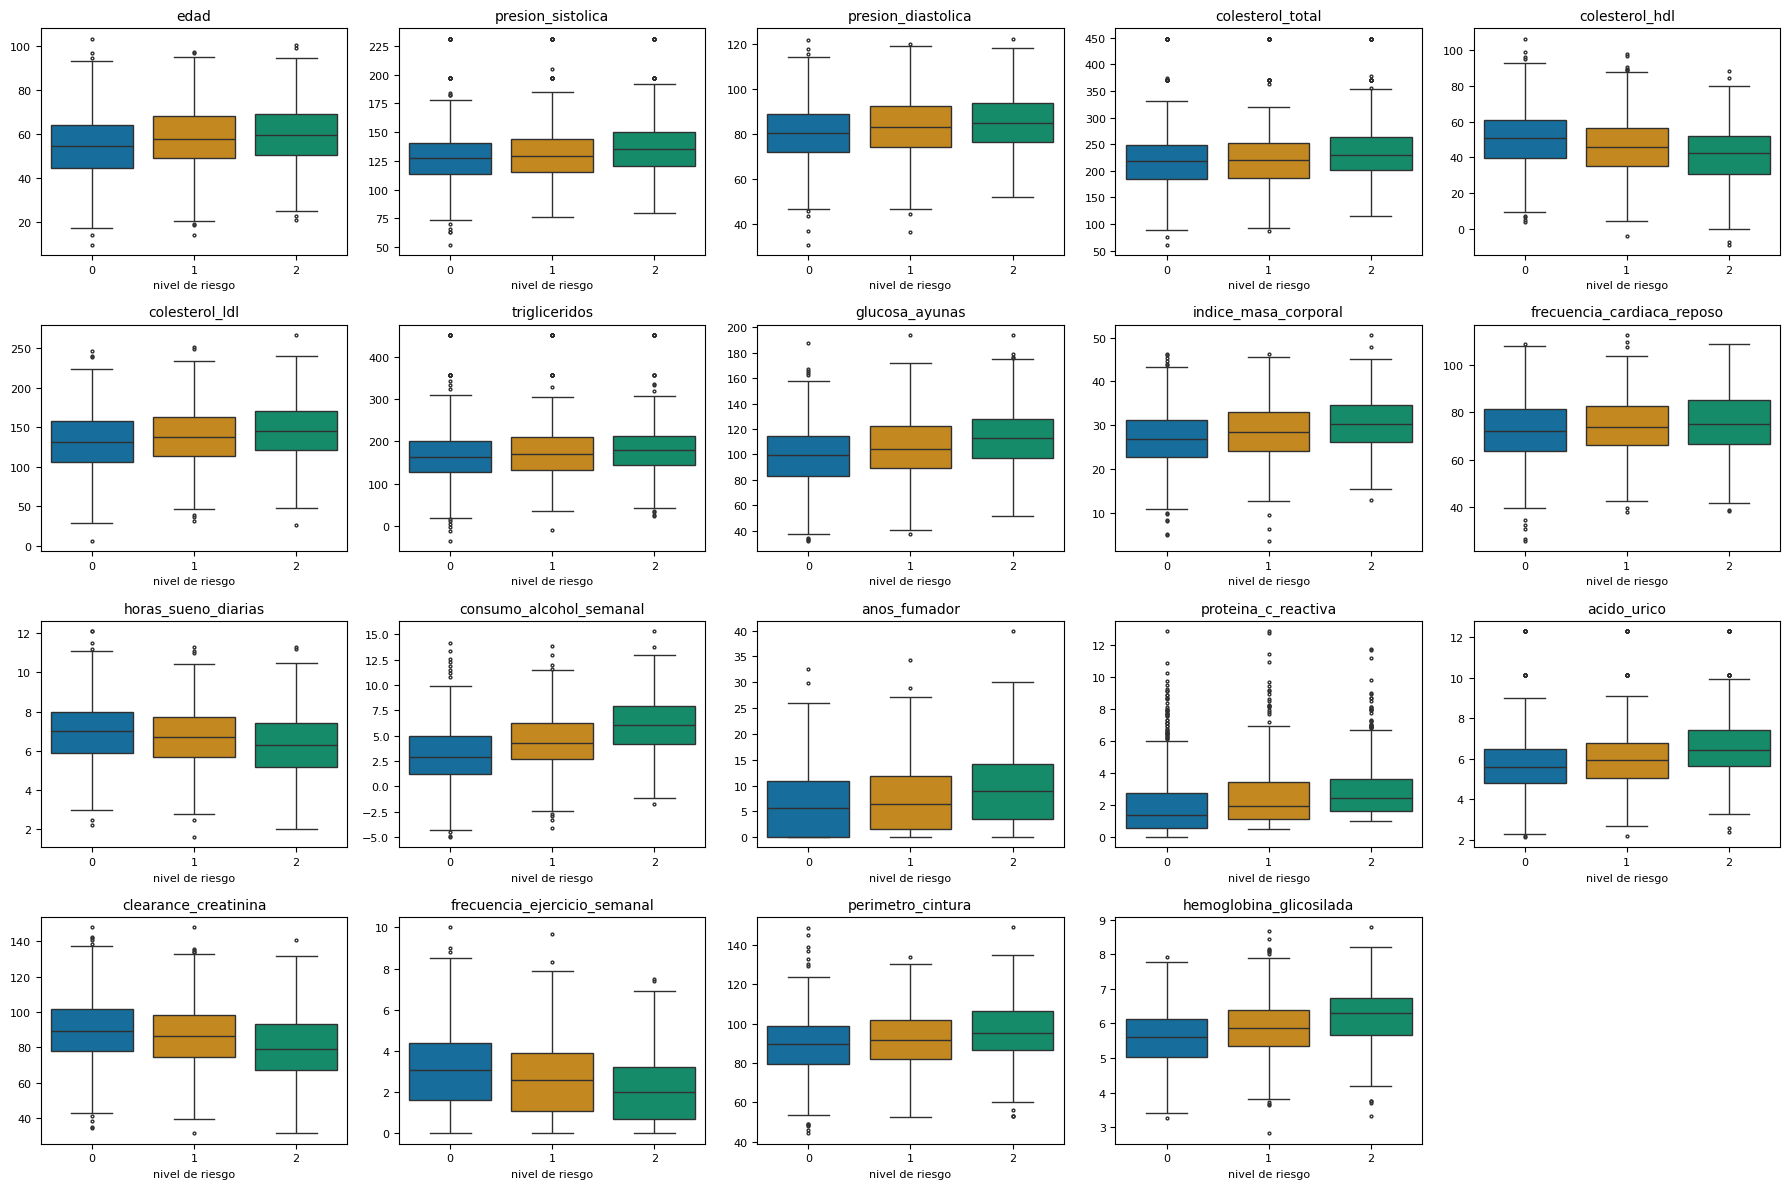

,0 - bajo,1 - moderado,2 - alto,diferencia alto - bajo
edad,54.90,57.80,59.60,4.70
presion_sistolica,127.70,129.10,135.60,7.90
presion_diastolica,80.30,82.95,85.00,4.70
colesterol_total,218.00,221.10,229.00,11.00
colesterol_hdl,50.60,45.65,42.20,-8.40
colesterol_ldl,131.80,137.00,144.80,13.00
trigliceridos,163.80,171.50,180.20,16.40
glucosa_ayunas,99.60,104.60,112.60,13.00
indice_masa_corporal,26.80,28.50,30.20,3.40
frecuencia_cardiaca_reposo,72.30,73.70,75.30,3.00


In [31]:
n_columnas = 5
n_filas = math.ceil(len(COLS_NUMERICAS) / n_columnas)
fig, axes = plt.subplots(n_filas, n_columnas, figsize=(18, n_filas * 3))
axes = axes.flatten()

for i, col in enumerate(COLS_NUMERICAS):
    sns.boxplot(data=df, x=TARGET, y=col, hue=TARGET, palette='colorblind',
                legend=False, fliersize=2, ax=axes[i])
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel('nivel de riesgo', fontsize=8)
    axes[i].set_ylabel('')
    axes[i].tick_params(labelsize=8)

for ax in axes[len(COLS_NUMERICAS):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

# Medianas por nivel de riesgo
medianas = df.groupby(TARGET)[COLS_NUMERICAS].median().T
medianas.columns = [ETIQUETAS_RIESGO[c] for c in medianas.columns]
medianas['diferencia alto - bajo'] = medianas['2 - alto'] - medianas['0 - bajo']
medianas.round(2)

- Todas las variables se ordenan de forma monótona con el riesgo. La mediana sube (o baja) de la clase 0 a la 1 y de la 1 a la 2, sin excepciones. Esto respalda tratar el objetivo como una escala ordenada.
- Los sentidos son los esperables desde un punto de vista clinico. Suben con el riesgo el alcohol (2,9 > 4,3 > 6,1 UBE), la HbA1c (5,60 > 5,87 > 6,30 %), la proteína C reactiva, el ácido úrico, la glucosa, el IMC, la edad y las presiones. Bajan el HDL (50,6 > 42,2 mg/dL), el ejercicio (3,1 > 2,0 días), el filtrado renal y las horas de sueño.
- Ninguna variable separa las clases por si sola. En todas ellas las cajas se solapan ampliamente: la diferencia entre clases es un desplazamiento pequeño comparado con la dispersión dentro de cada clase. La señal está repartida entre muchas variables débiles, así que habrá que combinarlas en un modelo multivariante.
- La clase 1 (moderado) queda siempre entre las otras dos y se solapa con ambas: previsiblemente será la más difícil de clasificar.

### 3.9 Relación de los predictores con el riesgo cardiovascular

#### Variables numéricas

Cuantificamos lo que se ve en los diagramas de caja con dos medidas que no exigen normalidad y son poco sensibles a los valores extremos, porque trabajan con rangos:
- Correlación de Spearman (ρ) entre cada variable y el nivel de riesgo. Es adecuada porque el objetivo es ordinal (0 < 1 < 2). Su signo indica el sentido de la relación.
- Contraste de Kruskal-Wallis, que comprueba si la distribución de la variable es la misma en las tres clases, junto con su tamaño del efecto ε² (proporción de la variabilidad explicada por la clase; orientativamente, < 0,01 despreciable, 0,01–0,06 pequeño, 0,06–0,14 moderado, > 0,14 grande).

Con 2.254 pacientes casi cualquier diferencia resulta estadísticamente significativa, así que lo que importa es el tamaño del efecto, no el p-valor.

,n,rho de Spearman,H de Kruskal-Wallis,p-valor,epsilon2
variable,,,,,
consumo_alcohol_semanal,2254,0.388,346.5,5.872099e-76,0.154
hemoglobina_glicosilada,2254,0.283,189.0,9.116444e-42,0.084
proteina_c_reactiva,2097,0.282,167.7,3.903802e-37,0.080
acido_urico,2254,0.213,111.2,6.988414e-25,0.049
frecuencia_ejercicio_semanal,2254,-0.207,100.5,1.522599e-22,0.045
glucosa_ayunas,2142,0.210,95.3,1.976050e-21,0.045
colesterol_hdl,2254,-0.200,90.3,2.525685e-20,0.040
indice_masa_corporal,2254,0.196,89.3,4.003136e-20,0.040
clearance_creatinina,2254,-0.184,84.1,5.424542e-19,0.037


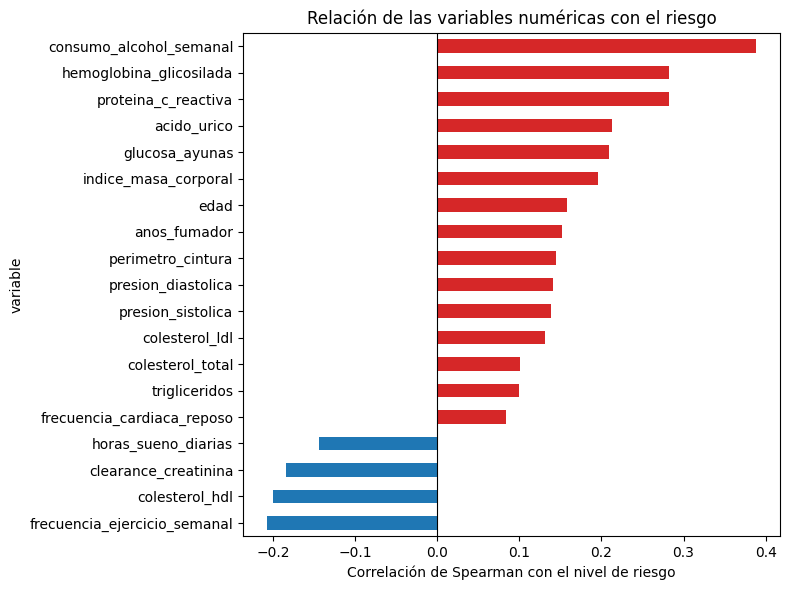

In [32]:
filas = []
for col in COLS_NUMERICAS:
    grupos = [df.loc[df[TARGET] == clase, col].dropna() for clase in (0, 1, 2)]
    h, p_valor = stats.kruskal(*grupos)
    n = sum(len(g) for g in grupos)
    rho = df[col].corr(df[TARGET], method='spearman')
    filas.append({
        'variable': col,
        'n': n,
        'rho de Spearman': rho,
        'H de Kruskal-Wallis': h,
        'p-valor': p_valor,
        'epsilon2': h / (n - 1)
    })

relacion_numericas = (pd.DataFrame(filas).set_index('variable')
                      .sort_values('epsilon2', ascending=False))
display(relacion_numericas.round({'rho de Spearman': 3, 'H de Kruskal-Wallis': 1, 'epsilon2': 3}))

fig, ax = plt.subplots(figsize=(8, 6))
orden = relacion_numericas['rho de Spearman'].sort_values()
colores = ['tab:blue' if v < 0 else 'tab:red' for v in orden]
orden.plot.barh(ax=ax, color=colores)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Correlación de Spearman con el nivel de riesgo')
ax.set_title('Relación de las variables numéricas con el riesgo')
plt.tight_layout()
plt.show()

- Las 19 variables numéricas presentan asociaciones estadísticamente significativas con el riesgo cardiovascular (p < 0,001), aunque de intensidad débil o moderada. La mayor correlación de Spearman en valor absoluto es 0,39.
- `consumo_alcohol_semanal` presenta la mayor asociación individual (ρ = 0,388; ε² = 0,154), seguido de `hemoglobina_glicosilada` y `proteina_c_reactiva` (ρ ≈ 0,28; ε² ≈ 0,08). A continuación, un conjunto amplio de variables presenta tamaños del efecto pequeños, como ácido úrico, glucosa en ayunas, ejercicio semanal, IMC, colesterol HDL y filtrado renal.
- Las variables `colesterol_total` y `trigliceridos` muestran asociaciones individuales débiles (ρ ≈ 0,10; ε² ≈ 0,01), mientras que las presiones arteriales presentan correlaciones ligeramente superiores (ρ ≈ 0,14; ε² ≈ 0,02). El colesterol HDL destaca dentro del perfil lipídico por su asociación negativa (ρ = −0,20; ε² = 0,04). La variable `frecuencia_cardiaca_reposo` presenta la asociación más débil (ρ = 0,084; ε² = 0,007).
- Consecuencia para la limpieza: `consumo_alcohol_semanal` es la variable con mayor asociación individual con el riesgo cardiovascular y presenta 177 valores negativos inválidos. Su tratamiento constituye una decisión de limpieza potencialmente importante, cuyo impacto sobre los modelos deberá evaluarse mediante un análisis de sensibilidad.
- Selección de variables: no se descarta ninguna variable en esta fase. Una asociación individual débil puede aportar información útil en combinación con otros predictores. Cualquier selección de características basada en los datos deberá realizarse dentro del proceso de validación cruzada, evitando fugas de información.

#### Variables booleanas y nominales

Para las variables categóricas usamos la tabla de contingencia con el nivel de riesgo. El contraste χ² de independencia indica si hay relación y la V de Cramér mide su intensidad en una escala de 0 (ninguna) a 1 (perfecta), comparable entre variables con distinto número de categorías.

,V de Cramér,p-valor
variable,,
uso_antihipertensivos,0.237,0.0
hipertension_previa,0.214,0.0
nivel_actividad,0.205,0.0
antecedentes_familiares_tipo,0.192,0.0
tratamiento_estatinas,0.187,0.0
diabetes_mellitus,0.186,0.0
tipo_alimentacion,0.180,0.0
fumador_actual,0.178,0.0



tipo_alimentacion (% por fila)
                       0 - bajo  1 - moderado  2 - alto
tipo_alimentacion                                      
Baja en carbohidratos      50.4          29.5      20.1
Mediterránea               64.3          23.8      11.9
Occidental                 36.8          33.9      29.3
Vegetariana                54.4          33.3      12.3

nivel_actividad (% por fila)
                      0 - bajo  1 - moderado  2 - alto
nivel_actividad                                       
Sedentario                33.6          35.1      31.3
Ligeramente activo        46.6          33.8      19.6
Moderadamente activo      62.0          24.9      13.1
Muy activo                72.2          19.4       8.4

antecedentes_familiares_tipo (% por fila)
                              0 - bajo  1 - moderado  2 - alto
antecedentes_familiares_tipo                                  
Ambos                             24.5          35.6      39.9
Materno                           45.8  

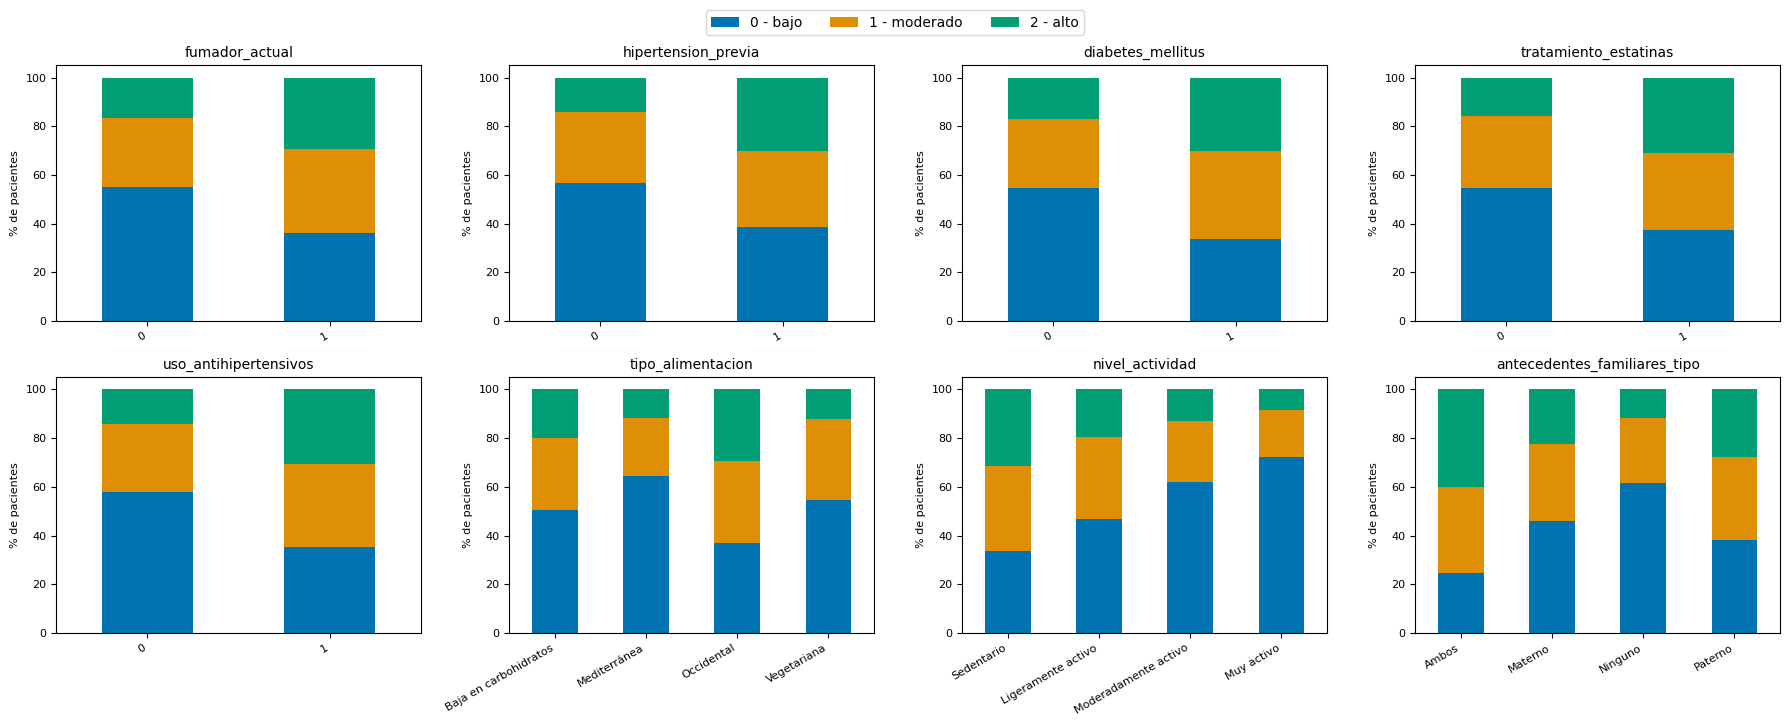

In [33]:
def v_de_cramer(tabla):
    chi2, p_valor, _, esperadas = stats.chi2_contingency(tabla)
    n = tabla.to_numpy().sum()

    if esperadas.min() < 1 or (esperadas < 5).mean() > 0.20:
        print("Advertencia: frecuencias esperadas insuficientes")

    return np.sqrt(chi2 / (n * (min(tabla.shape) - 1))), p_valor

filas = []
for col in COLS_BOOLEANAS + COLS_NOMINALES:
    v, p_valor = v_de_cramer(pd.crosstab(df[col], df[TARGET]))
    filas.append({'variable': col, 'V de Cramér': v, 'p-valor': p_valor})
display(pd.DataFrame(filas).set_index('variable').sort_values('V de Cramér', ascending=False).round(3))

# Reparto del riesgo dentro de cada categoría (% por fila)
ORDEN_ACTIVIDAD = ['Sedentario', 'Ligeramente activo', 'Moderadamente activo', 'Muy activo']
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
axes = axes.flatten()
for i, col in enumerate(COLS_BOOLEANAS + COLS_NOMINALES):
    reparto = pd.crosstab(df[col], df[TARGET], normalize='index') * 100
    if col == 'nivel_actividad':
        reparto = reparto.loc[ORDEN_ACTIVIDAD]
    reparto.columns = [ETIQUETAS_RIESGO[c] for c in reparto.columns]
    reparto.plot.bar(stacked=True, ax=axes[i], rot=30, legend=False,
                     color=sns.color_palette('colorblind')[:3])
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('% de pacientes', fontsize=8)
    axes[i].tick_params(labelsize=8)
    for etiqueta in axes[i].get_xticklabels():
        etiqueta.set_ha('right')
    if col in COLS_NOMINALES:
        print(f'\n{col} (% por fila)')
        print(reparto.round(1).to_string())
simbolos, nombres = axes[0].get_legend_handles_labels()
fig.legend(simbolos, nombres, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.04))
plt.tight_layout()
plt.show()

- Las ocho variables categóricas presentan asociaciones estadísticamente significativas con el riesgo cardiovascular (p < 0,001), con tamaños del efecto de intensidad baja a moderada (V de Cramér entre 0,178 y 0,237).
- Variables booleanas: `uso_antihipertensivos` presenta la mayor asociación individual (V = 0,237), seguido de `hipertension_previa` (V = 0,214). La proporción de pacientes con riesgo alto es aproximadamente el doble entre quienes presentan estas condiciones (30,6 % frente a 14,3 % y 30,4 % frente a 14,0 %, respectivamente). La asociación positiva entre tratamiento antihipertensivo y riesgo puede explicarse por confusión por indicación: el tratamiento identifica a pacientes con factores de riesgo preexistentes, sin implicar que el medicamento incremente el riesgo.
- Nivel de actividad: presenta un gradiente ordinal claro. La proporción de riesgo alto disminuye progresivamente desde el 31,3 % en pacientes sedentarios hasta el 19,6 %, 13,1 % y 8,4 % en los niveles de actividad superiores. Aunque inicialmente se clasifique como nominal, sus categorías tienen un orden natural, por lo que resulta razonable evaluar tanto una codificación ordinal como one-hot durante el modelado.
- `antecedentes_familiares_tipo`: la proporción de pacientes con riesgo alto aumenta del 11,9 % sin antecedentes al 39,9 % con antecedentes por ambas ramas. Los antecedentes paternos presentan una proporción de riesgo alto superior a los maternos (27,7 % frente a 22,4 %), aunque no se ha contrastado específicamente la significación de esta diferencia.
- `tipo_alimentacion`: la dieta occidental presenta la mayor proporción de pacientes con riesgo alto (29,3 %), mientras que la mediterránea y la vegetariana presentan las menores (≈ 12 %). Al tratarse de categorías sin orden natural, se considera apropiada la codificación one-hot.
- Tratamiento de las variables categóricas: las tres variables inicialmente clasificadas como nominales no presentan valores ausentes ni categorías de frecuencia especialmente baja (la menos frecuente, «Ambos», cuenta con 188 pacientes). Por tanto, no se considera necesario agrupar categorías. No obstante, `nivel_actividad` tiene un orden natural y podrá tratarse como ordinal durante el modelado.

### 3.10. Relación entre predictores

Si dos predictores están muy correlacionados aportan información redundante: los modelos lineales se vuelven inestables (multicolinealidad) y podría bastar con uno de ellos. Lo comprobamos con la matriz de correlaciones de Spearman entre las variables numéricas.

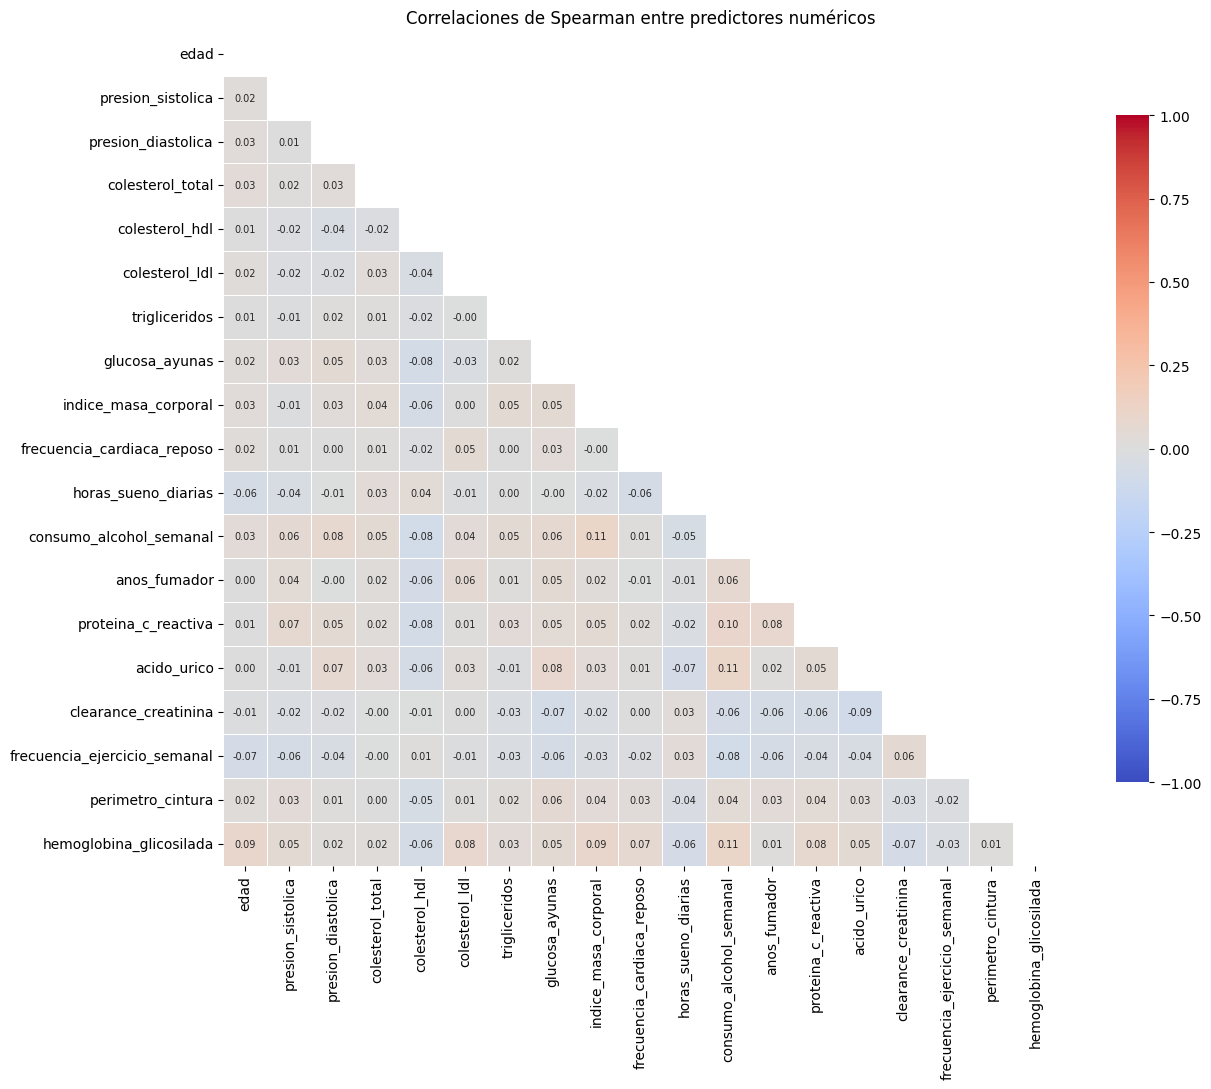

In [34]:
correlaciones = df[COLS_NUMERICAS].corr(method='spearman')
mascara = np.triu(np.ones_like(correlaciones, dtype=bool))

plt.figure(figsize=(14, 11))
sns.heatmap(correlaciones, mask=mascara, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5,
            annot_kws={'size': 7}, cbar_kws={'shrink': 0.8})
plt.title('Correlaciones de Spearman entre predictores numéricos')
plt.tight_layout()
plt.show()

In [35]:
PARES_CLINICOS = [('presion_sistolica', 'presion_diastolica'), ('indice_masa_corporal', 'perimetro_cintura'),
                  ('glucosa_ayunas', 'hemoglobina_glicosilada'), ('colesterol_total', 'colesterol_ldl')]
print('\nPares con correlación clínicamente esperada:')
for a, b in PARES_CLINICOS:
    print(f'  {a} - {b}: rho = {correlaciones.loc[a, b]:.3f}')


Pares con correlación clínicamente esperada:
  presion_sistolica - presion_diastolica: rho = 0.007
  indice_masa_corporal - perimetro_cintura: rho = 0.038
  glucosa_ayunas - hemoglobina_glicosilada: rho = 0.051
  colesterol_total - colesterol_ldl: rho = 0.026


- Redundancia entre predictores: las correlaciones de Spearman entre las variables numéricas son prácticamente nulas (|ρ| ≤ 0,11). No se detectan asociaciones bivariadas suficientemente intensas como para justificar la eliminación de variables por redundancia. No obstante, este análisis no descarta completamente la multicolinealidad, que podrá evaluarse mediante VIF si se utilizan modelos lineales.
- Relaciones entre predictores y riesgo: las pequeñas correlaciones observadas entre algunos predictores podrían deberse parcialmente a su asociación común con el nivel de riesgo cardiovascular. Esta hipótesis puede explorarse calculando las correlaciones dentro de cada clase de riesgo.
- Coherencia clínica del dataset: no aparecen las asociaciones positivas que cabría esperar entre variables fisiológicamente relacionadas: presión sistólica y diastólica (ρ = 0,007), IMC y perímetro de cintura (ρ = 0,038), glucosa y HbA1c (ρ = 0,051), y colesterol total y LDL (ρ = 0,026). La ausencia simultánea de estas relaciones constituye un indicio importante de que el dataset podría haber sido generado sintéticamente, sin preservar adecuadamente las dependencias clínicas entre predictores. Los resultados son compatibles con una generación relativamente independiente de las variables, posiblemente condicionada por la clase de riesgo, aunque no permiten confirmar el mecanismo de generación.

**Consecuencias para el preprocesamiento y el modelado:**

1. **Validación de coherencia:** la ausencia de asociaciones fisiológicas esperadas limita la utilidad de las reglas de coherencia entre variables para identificar posibles errores de captura. Se mantienen las comprobaciones de dominios válidos, valores extremos e inconsistencias clínicas o matemáticas justificadas.

2. **Imputación de ausentes:** dado que los predictores numéricos presentan correlaciones muy débiles entre sí, se plantea la hipótesis de que métodos multivariantes como k-NN o la imputación iterativa podrían ofrecer ventajas limitadas frente a la imputación por mediana. Esta hipótesis se comprobará mediante la comparación de técnicas dentro del proceso de validación, evitando fugas de información.

3. **Validez externa:** la ausencia de dependencias fisiológicas habituales entre predictores constituye una limitación relevante del dataset. Los modelos podrían aprender patrones estadísticos que no reflejen adecuadamente las relaciones presentes en poblaciones clínicas reales, por lo que su rendimiento interno no garantiza su capacidad de generalización a pacientes reales.

### 3.11 Variable objetivo y desbalanceo

,pacientes,porcentaje (%)
0 - bajo,1127,50.00
1 - moderado,676,29.99
2 - alto,451,20.01


Ratio de desbalanceo (mayoritaria / minoritaria): 2.50


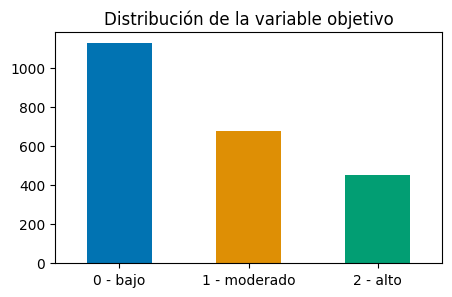

In [36]:
conteo = df[TARGET].value_counts().sort_index()
porcentaje = df[TARGET].value_counts(normalize=True).sort_index() * 100
tabla_clases = pd.DataFrame({'pacientes': conteo, 'porcentaje (%)': porcentaje.round(2)})
tabla_clases.index = ['0 - bajo', '1 - moderado', '2 - alto']
display(tabla_clases)
print(f'Ratio de desbalanceo (mayoritaria / minoritaria): {conteo.max() / conteo.min():.2f}')

fig, ax = plt.subplots(figsize=(5, 3))
tabla_clases['pacientes'].plot.bar(ax=ax, rot=0, color=sns.color_palette('colorblind')[:3])
ax.set_title('Distribución de la variable objetivo')
plt.show()

- Distribución de clases: el riesgo cardiovascular presenta una distribución del 50 % (bajo), 30 % (moderado) y 20 % (alto), con un ratio de desbalanceo de 2,5:1, considerado moderado.
- Importancia clínica: la clase minoritaria corresponde al riesgo alto, cuya detección resulta especialmente relevante. Los falsos negativos de esta clase implican infravalorar el riesgo cardiovascular del paciente, siendo potencialmente más grave clasificarlo como riesgo bajo que como moderado.
- Limitaciones de la exactitud: un clasificador trivial que predijera siempre riesgo bajo alcanzaría un 50 % de exactitud sin capacidad discriminativa. Por tanto, la exactitud no se utilizará como métrica principal, aunque podrá mantenerse como indicador secundario.
- Evaluación de modelos: se priorizarán métricas que consideren el rendimiento por clase y el desbalanceo, especialmente la sensibilidad de la clase de riesgo alto, F1-macro, balanced accuracy y la matriz de confusión. También se considerará el kappa de Cohen ponderado para incorporar el carácter ordinal del objetivo. El clasificador trivial servirá como línea base de comparación.

**Decisiones para el preprocesamiento, la validación y la evaluación:**

- **Particiones estratificadas:** mantener aproximadamente la distribución 50/30/20 de las clases en entrenamiento, test y cada pliegue de validación cruzada.

- **Tratamiento del desbalanceo:** comparar inicialmente modelos sin ponderación y con `class_weight='balanced'`, priorizando esta última como primera alternativa al desbalanceo moderado (2,5:1). Si resulta necesario, evaluar técnicas de remuestreo como SMOTE, aplicadas exclusivamente sobre los datos de entrenamiento mediante `imblearn.pipeline.Pipeline`, dentro de la validación cruzada.

- **Optimización de hiperparámetros:** utilizar explícitamente `scoring='f1_macro'` en `GridSearchCV` o `RandomizedSearchCV`, evitando que la selección de hiperparámetros dependa de la exactitud por defecto. Considerar optimización multimetric mediante `scoring` con varias métricas y `refit='f1_macro'`.

- **Evaluación multiclase:** priorizar F1-macro, balanced accuracy y sensibilidad de la clase de riesgo alto, complementadas con la matriz de confusión y métricas por clase. Mantener la exactitud como métrica secundaria y comparar los resultados con un clasificador trivial.

- **Evaluación ordinal:** incorporar el kappa de Cohen ponderado cuadrático para penalizar más los errores entre clases extremas (0 ↔ 2) que entre clases contiguas (0 ↔ 1 o 1 ↔ 2), sin asumir que esas ponderaciones reflejan necesariamente los costes clínicos reales.

### 3.12 Escalas de las variables

In [37]:
escalas = df[COLS_NUMERICAS].agg(['min', 'max', 'std']).T
escalas['rango'] = escalas['max'] - escalas['min']
escalas.sort_values('rango', ascending=False).round(2)

,min,max,std,rango
trigliceridos,-35.70,452.70,72.74,488.40
colesterol_total,61.10,448.59,62.73,387.49
colesterol_ldl,6.10,266.70,36.73,260.60
presion_sistolica,52.20,231.36,26.93,179.16
glucosa_ayunas,32.00,194.00,24.94,162.00
clearance_creatinina,31.20,147.80,18.37,116.60
colesterol_hdl,-8.80,106.30,15.99,115.10
perimetro_cintura,44.20,148.90,14.87,104.70
edad,9.80,103.50,14.45,93.70
presion_diastolica,30.80,122.50,13.08,91.70


**Diferencias de escala entre predictores numéricos:**

Los rangos observados presentan diferencias importantes, desde aproximadamente 6 unidades para la hemoglobina glicosilada (HbA1c) hasta 488 para los triglicéridos. También existen diferencias considerables en las desviaciones típicas.

Estas diferencias pueden afectar especialmente a los modelos basados en distancias, como k-NN, y a los modelos lineales regularizados, como la regresión logística.

**Decisión para el preprocesamiento:** incorporar escalado cuando el algoritmo lo requiera, comparando `StandardScaler` y `RobustScaler` si resulta pertinente. El escalador se ajustará exclusivamente con los datos de entrenamiento de cada partición, dentro del pipeline, para evitar fugas de información.

Los modelos basados en árboles se evaluarán, en principio, sin escalado. Los valores clínicamente inválidos deberán tratarse antes de aplicar las transformaciones.

## 4. Decisiones de limpieza de datos

Este apartado recoge, sin ejecutar código, las decisiones que se derivan del EDA (apartado 3). El apartado 5 las automatiza en una función. Se distinguen dos tipos de operación:

- **Reglas deterministas de dominio** (eliminar menores, recortar, convertir en NaN valores imposibles): no aprenden ningún parámetro de los datos, así que pueden aplicarse a todo el conjunto antes de dividir sin riesgo de fuga de información. Se aplican a un paciente nuevo exactamente igual.
- **Transformaciones aprendidas** (imputación, escalado, remuestreo): dependen de los datos y se ajustan **solo con el entrenamiento de cada pliegue**, dentro de un *pipeline* (apartado de modelado). No se aplican aquí.
- **Transformaciones deterministas de modelado** (`log1p` de la PCR): no aprenden parámetros, así que no hay riesgo de fuga, pero no son limpieza. Se incluyen en el *pipeline* por reproducibilidad y para comparar con y sin transformación (los árboles no la necesitan).

### 4.1 Decisiones

| # | Problema | Decisión | Afectados | Justificación |
|---|---|---|---|---|
| 1 | Edad con decimales (91 %) | Aceptarla como variable continua | — | Es una convención del registro, no un error de cada paciente; los decimales aportan precisión. |
| 2 | Menores de 18 años | Eliminar las filas | 4 filas (0,2 %) | Están fuera de la población definida en el enunciado y dos son absurdos (9,8 años con 12,6 años fumando). Quedan 2250 pacientes. |
| 3 | Ejercicio semanal > 7 | Aceptar decimales (promedio semanal) y **recortar a 7** | 41 valores | 7 es el máximo permitido por la definición de la variable (días por semana). No se puede conocer el valor real: 31 de los 41 están entre 7,1 y 7,9, pero hay 10 entre 8,1 y 10, por lo que el recorte es una decisión operativa y no recupera el dato. |
| 4 | Alcohol semanal negativo | **Recortar a 0** como decisión operativa; se compara con NaN en el análisis de sensibilidad (`regla_alcohol`) | 177 valores | Son inválidos por definición (de −5 a −0,1; media −1,3), pero no se conoce el valor real: convertir −5 en 0 es una asunción. Se prefiere al NaN porque son la cola baja de la variable, no ausentes al azar, y una imputación con la mediana (4,0) los llevaría al centro. Que 146 de los 177 sean de clase 0 apoya descartar esa imputación, pero no justifica el recorte. **Limitaciones:** el recorte crea un pico de 184 ceros (8,2 %) frente a 7 originales, y el alcohol es la variable más asociada al riesgo (ρ = 0,39), por lo que la decisión se evalúa con la sensibilidad. |
| 5 | Valores imposibles o implausibles | Convertir en **NaN** el valor (no el paciente) | Ver tabla 4.2 | Incompatibles con un adulto vivo o con la propia definición de la variable. |
| 6 | Valores anómalos repetidos en cuatro variables (`presion_sistolica`, `colesterol_total`, `trigliceridos`, `acido_urico`) | Convertir en **NaN solo los valores repetidos**, conservando a los pacientes | 448 celdas en 419 pacientes (18,6 %) tras retirar a los menores (449 y 420 en el conjunto completo) | Ver el análisis de 3.6.5, resumido en 4.2 bis. Las evidencias de 4.2 bis apuntan a generación o sustitución artificial, aunque el mecanismo no se puede demostrar. No parecen mediciones fiables: aportan ruido y una falsa asimetría, y no corresponden a pacientes con valores extremos reales, por lo que se tratan como ausentes y no como mediciones. |
| 7 | Sistólica ≤ diastólica | **Ambas presiones a NaN** | 44 filas | Es incompatible con la fisiología y no se puede saber cuál de las dos es errónea. Incluye las tres sistólicas más bajas (52,2; 62,8; 63,5). |
| 8 | LDL > colesterol total | **Conservar** los valores, registrarlos como incidencia y evaluar su impacto con un análisis de sensibilidad (conservar / LDL a NaN / ambos a NaN) | 140 filas (6,2 %) | Es incoherente por definición (el LDL es una fracción del total), pero no hay base para atribuir el error a una de las dos variables. El LDL registrado no es compatible con la fórmula de Friedewald a partir de total, HDL y triglicéridos (muestra depurada de 3.6.6: excluye las anomalías identificadas, es decir, menores, negativos y valores repetidos, pero **no** las incoherencias LDL > total, de modo que la comprobación no depende de encontrar concordancia entre las variables; n = 1.906 con triglicéridos entre 0 y 400: r = 0,04 con el valor calculado; solo el 13,5 % de las diferencias es ≤ 10 mg/dL), y las correlaciones LDL–total (0,04) y LDL–HDL (−0,03) son ≈ 0. Es compatible con una generación artificial con escasa dependencia entre las variables lipídicas (las correlaciones no demuestran independencia), y no hay evidencia para atribuir el error al LDL y no al total. Anular una de ellas introduciría ausencias artificiales (sobre los 2.250 pacientes tras aplicar el resto de reglas, las filas con algún NaN subirían del 39,2 % al 43,5 %) sin certeza de corregir nada. El validador la mantiene como `INCONSISTENCIA` (revisión). |
| 9 | Años de fumador > edad | **Años de fumador a NaN** | 1 fila, que ya se elimina en la decisión 2 (0 tras aplicar el orden de 4.4) | Es imposible. Se mantiene como regla de validación por si llegan datos nuevos. |

### 4.2 Límites de plausibilidad (decisión 5)

Se convierte en NaN el valor que queda por debajo del límite indicado. En HDL y triglicéridos el límite es ≤ 0 porque ningún paciente tiene un valor exactamente nulo (los 4 casos de cada variable son negativos).

| Variable | Valor no plausible | Justificación | Afectados |
|---|---|---|---|
| `colesterol_hdl` | ≤ 0 | Una concentración no puede ser nula ni negativa | 4 |
| `trigliceridos` | ≤ 0 | Ídem | 4 |
| `indice_masa_corporal` | < 10 kg/m² | Cerca del límite de supervivencia en desnutrición extrema; los 8 valores son de 3,6 a 9,7 | 8 |
| `frecuencia_cardiaca_reposo` | < 30 lpm | Bradicardia extrema, excepcional en una medición rutinaria de frecuencia cardíaca en reposo; se considera no plausible para este estudio | 2 |
| `perimetro_cintura` | < 40 cm | Extremadamente pequeño para un adulto; mínimo observado 44,2 cm, por lo que no hay ningún caso y la regla solo actúa como validación de datos nuevos | 0 |


> **Nota sobre los umbrales.** IMC < 10 y FC < 30 son límites de plausibilidad extrema, elegidos para identificar valores extremadamente implausibles en la población adulta estudiada, sin asumir que constituyen límites fisiológicos absolutos. No se establece un umbral inferior de anulación para HbA1c. Aunque se observan valores muy bajos (2,82 %–3,6 %), su interpretación requiere una valoración clínica específica. Por tanto, se conservan y se registran como posibles alertas cuando corresponda.

### 4.2 bis Evidencia sobre los valores repetidos (decisión 6)

Resultados de la tabla de 3.6.5. En conjunto son evidencias sólidas de generación o sustitución artificial; ninguna demuestra por sí sola el mecanismo.

- **Misma posición relativa en las cuatro variables.** Los dos valores repetidos de cada variable están a 3,50–3,51 y 5,25–5,26 desviaciones típicas de la media del resto (la media y la desviación típica se calcularon excluyendo previamente los valores repetidos). Que cuatro magnitudes clínicas con unidades y rangos distintos coincidan en esa posición apunta a un procedimiento automático.
- **No es compatible con un recorte simple a un único máximo (*top-coding*).** En `presion_sistolica` y `colesterol_total` se observan valores superiores al primer valor repetido (204,6 frente a 196,95 y 378,9 frente a 371,24), y un recorte dejaría un único pico, no dos.
- **No se detecta asociación estadísticamente significativa con el riesgo** (χ² por variable, p entre 0,30 y 0,82). Cada variable tiene entre 90 y 135 pacientes afectados (36–74 por valor), por lo que la potencia estadística es limitada y el resultado se considera evidencia complementaria.
- **Se parecen al resto en las demás variables.** La mayor diferencia estandarizada de medias en las otras 15 variables numéricas es 0,09 (IMC), por debajo de 0,1
- **Efecto de estos valores sobre la distribución.** Con ellos la asimetría es ≈ 1,3 y sin ellos ≈ 0.
- **Los decimales solo delatan a algunas variables.** En `presion_sistolica` y `colesterol_total`, los dos valores tienen 2 decimales y ningún otro valor de la columna. En `trigliceridos` solo 357,56 los tiene y en `acido_urico` el 90 % de los valores ya tiene 2, por lo que no distinguen nada.

### 4.3 Qué no se hace y limitaciones

**No se modifican:**
- **Valores atípicos por rango intercuartílico (IQR).** En 3.7, una vez retirados los valores anómalos, las variables continuas conservan entre 6 y 18 atípicos, y la PCR 89. Son valores plausibles (la PCR tiene una asimetría natural), por lo que se conservan. La PCR se transforma con `log1p` (asimetría 0,24, resultado de aplicar `log1p`) en el *pipeline*: es determinista, pero es una decisión de modelado y no de limpieza.
- **Variables binarias** (diabetes, hipertensión, etc.): el criterio IQR no tiene sentido en ellas (en diabetes, Q1 = Q3 = 0).
- **Valores ausentes originales** (23,6 % de las filas): no se tratan aquí. La imputación se hace dentro del *pipeline* con los datos de entrenamiento de cada pliegue. El EDA (3.4) no detecta evidencias suficientes para rechazar un mecanismo MCAR en los valores ausentes originales, aunque no permite confirmarlo.

**Limitaciones asumidas:**
- Los valores repetidos son altos (+3,5 y +5,25 desviaciones). Si sustituyen a valores reales también altos, los NaN introducidos podrían ser MNAR y una imputación por la mediana los infraestimaría. Se evaluará su impacto comparando estrategias de imputación e incorporando indicadores de ausencia en las cuatro variables con valores repetidos (`presion_sistolica`, `colesterol_total`, `trigliceridos` y `acido_urico`). Ninguna tenía ausentes originales, por lo que sus NaN proceden de las reglas de limpieza, principalmente de los valores repetidos. Estos indicadores no garantizan corregir el posible sesgo MNAR.
- Tras aplicar las reglas, el 39,2 % de las filas tiene al menos un NaN (el 43,5 % si se anulase el LDL incoherente). Esto exige una imputación robusta y justifica comparar estrategias de imputación en la validación.
- Las incoherencias entre variables (sistólica ≤ diastólica, LDL > total y LDL > no HDL, con 559 casos) son compatibles con una generación con escasa dependencia entre ellas: los casos observados (44, 140 y 559) son próximos a los esperados bajo independencia (≈ 56, ≈ 156 y ≈ 565, permutando una de las dos columnas), aunque eso no demuestra independencia ni permite determinar su origen. Presión y tabaco se anulan por coherencia fisiológica y lógica; LDL > total se conserva y se evalúa con el análisis de sensibilidad. No se atribuyen automáticamente a errores de captura, pero tampoco se descarta que lo sean.

### 4.4 Orden de aplicación

El orden importa porque unas reglas dejan sin efecto a otras (el caso de tabaco desaparece al eliminar al menor):

1. Eliminar menores de 18 años (decisión 2).
2. Aplicar recortes: ejercicio a 7 y alcohol a 0 (decisiones 3 y 4).
3. Convertir en NaN los valores fuera de los límites de plausibilidad (decisión 5, tabla 4.2).
4. Convertir en NaN los valores repetidos anómalos (decisión 6).
5. Aplicar las reglas entre variables: anular ambas presiones cuando sistólica ≤ diastólica y los años de fumador cuando superen la edad (decisiones 7 y 9). Las incoherencias LDL > colesterol total se conservan y se documentan mediante el validador (decisión 8).

La función del apartado 5 devolverá, además del *DataFrame* limpio, un registro de cuántos valores cambia cada regla, para contrastarlo con esta tabla, y se contrastará con el validador (apartado 4.5).

### 4.5 Relación con el validador

Se usa `validador_datos_cardiovasculares_v3.py`. Los tipos de incidencia se interpretan así:

| Tipo del validador | Qué hace la limpieza |
|---|---|
| `INVALIDO` por dominio (negativos, > 7 días, menores) | Se corrige según las decisiones 2–5. |
| `EXTREMO` | Es un aviso de revisión, **no** una regla de eliminación: solo se anulan los de la tabla 4.2. |
| `INCONSISTENCIA` | El tipo describe la naturaleza del problema y la columna `decision`, su tratamiento. Presión y tabaco: `corregir` (se anulan, decisiones 7 y 9). LDL > total y LDL > no HDL: `conservar` (se mantienen y se registran, decisión 8). |
| `ALERTA_CLINICA` | No se modifica: son valores plausibles. |
| `ARTEFACTO` | Valores repetidos de la decisión 6: se anulan. |
| Edad y días no enteros, valores ausentes | No son incidencias por defecto (decisiones 1 y 3 y apartado 4.3). |

La limpieza no pretende dejar el validador a cero incidencias. Debe comprobarse que no queda ninguna incidencia con decisión `corregir`, mientras que las clasificadas como `conservar` o `revision` pueden permanecer. En el apartado 5 se ejecutará `verificar_limpieza` y se realizará una comprobación explícita de las correcciones pendientes.

## 5. Limpieza basada en reglas

La función `limpiar_datos_cardiovasculares` (`src/limpieza.py`) automatiza las decisiones del apartado 4. Trabaja sobre una copia (**`df` no se modifica**), no aprende parámetros de los datos y devuelve el *DataFrame* limpio (`df_limpio`) y un registro de cuántas celdas modifica cada regla. Las constantes (límites, valores repetidos) están en `src/reglas_datos.py` y las usa también el validador v3, para que ambos sean coherentes.

A partir de aquí, el trabajo de modelado parte de `df_limpio`. La imputación no se hace aquí: va en el *pipeline*, ajustada solo con el entrenamiento de cada pliegue.

In [38]:
from src.limpieza import limpiar_datos_cardiovasculares
from src.validador_datos_cardiovasculares_v3 import resumen_ausentes

df_limpio, registro = limpiar_datos_cardiovasculares(df, regla_lipidos='conservar')
print(f'Filas: {len(df)} -> {len(df_limpio)}')
registro

Filas: 2254 -> 2250


,decision,regla,variable,celdas,filas
0,2,Eliminar menores de 18,(fila),4,4
1,3,Ejercicio > 7 recortado,frecuencia_ejercicio_semanal,41,41
2,4,Alcohol negativo recortado a 0,consumo_alcohol_semanal,177,177
3,5,colesterol_hdl <= 0 a NaN,colesterol_hdl,4,4
4,5,trigliceridos <= 0 a NaN,trigliceridos,4,4
5,5,indice_masa_corporal < 10 a NaN,indice_masa_corporal,8,8
6,5,frecuencia_cardiaca_reposo < 30 a NaN,frecuencia_cardiaca_reposo,2,2
7,5,perimetro_cintura < 40 a NaN,perimetro_cintura,0,0
8,6,"presion_sistolica: valores repetidos (196.95, ...",presion_sistolica,112,112
9,6,"colesterol_total: valores repetidos (371.24, 4...",colesterol_total,135,135


### 5.1 Contraste con la tabla 4.1

Coincide con el apartado 4: 4 menores; 41 ejercicios; 177 alcoholes; 4 + 4 + 8 + 2 + 0 por límites de plausibilidad; 449 valores repetidos en el conjunto completo, que son **448 celdas en 419 pacientes** una vez retirados los menores (uno de ellos tenía un valor repetido); 44 filas con sistólica ≤ diastólica (88 celdas); 140 filas con LDL > total, que se conservan; 0 con años de fumador > edad.

In [39]:
esperado = {2: 4, 3: 41, 4: 177, 7: 44}
obtenido = registro.groupby('decision')['filas'].sum()
for decision, n in esperado.items():
    assert obtenido[decision] == n, (decision, obtenido[decision], n)
assert registro.query("regla == 'Total valores repetidos'")['celdas'].iloc[0] == 448
assert registro.query('decision == 8')['filas'].iloc[0] == 140
print('Registro coherente con la tabla 4.1')

Registro coherente con la tabla 4.1


### 5.2 Verificación con el validador v3

Se pasa el validador al conjunto limpio con la función `auditar_datos` de 3.5. La limpieza es correcta si no queda ninguna incidencia con decisión `corregir`. Las de `conservar` (LDL > total y LDL > no HDL) pueden permanecer, porque se conservan a propósito, y las de `revision` son avisos que no requieren corrección automática.

In [40]:
incidencias_limpio, resumen_limpio = auditar_datos(df_limpio, 'v3_limpio')

pendientes = incidencias_limpio.query("decision == 'corregir'")
assert pendientes.empty, f'Quedan {len(pendientes)} incidencias por corregir'
print('Sin incidencias pendientes de corregir')
resumen_limpio.query("decision == 'conservar'")

=== v3_limpio: 2250 registros ===
Incidencias detectadas: 807
Registros afectados: 639
Registros que requieren corrección: 0

Por decisión prevista:


,incidencias
decision,
conservar,698
revision,109



Resumen por variable y regla:


,variable,tipo,regla,decision,casos
0,colesterol_ldl,INCONSISTENCIA,LDL > colesterol no-HDL,conservar,558
1,colesterol_ldl,INCONSISTENCIA,LDL > colesterol total,conservar,140
2,glucosa_ayunas,ALERTA_CLINICA,Glucosa < 54 mg/dL,revision,34
3,hemoglobina_glicosilada,ALERTA_CLINICA,HbA1c < 4 %,revision,31
4,colesterol_hdl,EXTREMO,Inferior al límite de plausibilidad,revision,16
5,proteina_c_reactiva,ALERTA_CLINICA,PCR > 10 mg/L,revision,10
6,presion_sistolica,ALERTA_CLINICA,Sistólica > 180 mmHg,revision,9
7,glucosa_ayunas,EXTREMO,Inferior al límite de plausibilidad,revision,6
8,colesterol_ldl,EXTREMO,Inferior al límite de plausibilidad,revision,1
9,horas_sueno_diarias,EXTREMO,Inferior al límite de plausibilidad,revision,1



Guardado en reports/generated: incidencias_validacion_v3_limpio.csv (807 filas) y resumen_validacion_v3_limpio.csv
Sin incidencias pendientes de corregir


,variable,tipo,regla,decision,casos
0,colesterol_ldl,INCONSISTENCIA,LDL > colesterol no-HDL,conservar,558
1,colesterol_ldl,INCONSISTENCIA,LDL > colesterol total,conservar,140


In [41]:
RUTA_PROCESADOS = RAIZ / 'data' / 'processed'
RUTA_PROCESADOS.mkdir(parents=True, exist_ok=True)
df_limpio.to_csv(RUTA_PROCESADOS / 'enfermedad_cardiovascular_limpio.csv', index=False)

### 5.3 Valores ausentes tras la limpieza

Los NaN que crean las reglas se suman a los originales (23,6 % de las filas con algún ausente). La imputación se hace dentro del *pipeline*, con los datos de entrenamiento de cada pliegue.

In [42]:
print(f"Filas con algún NaN: original {df.isna().any(axis=1).mean():.1%} -> limpio {df_limpio.isna().any(axis=1).mean():.1%}")
resumen_ausentes(df_limpio)

Filas con algún NaN: original 23.6% -> limpio 39.2%


,ausentes,porcentaje
horas_sueno_diarias,180,8.00
proteina_c_reactiva,157,6.98
presion_sistolica,156,6.93
colesterol_total,135,6.00
colesterol_ldl,134,5.96
glucosa_ayunas,112,4.98
acido_urico,111,4.93
trigliceridos,94,4.18
presion_diastolica,44,1.96
indice_masa_corporal,8,0.36


## 6. Preprocesamiento para el modelado

Este apartado decide cómo se preparan los datos para los modelos. Dividimos el preprocesamiento en los siguentes subapartados: partición y validación (6.1), imputación (6.2), codificación (6.3), escalado (6.4) y desbalanceo (6.5). 

Todas estas técnicas aprenden parámetros de los datos (medianas, escalas, categorías, pacientes sintéticos), así que para evitar data leakage se ajustan dentro de un pipeline y solo con el entrenamiento de cada pliegue.

### 6.1 Partición y validación

En este apartado interemos responder a la pregunta: ¿Cómo podemos medir el rendimiento del modelo con datos que no ha visto previamente?

Así, explicaremos cómo separar los datos en distintos conjuntos para entrenar y evaluar los modelos. El objetivo es evitar que el modelo memorice los datos disponibles y obtener una estimación realista de su capacidad de generalización a nuevos pacientes.

Vamos a reservar un conjunto de test que no interviene en ninguna decisión (Hold-out estratificado). Se estratifica por la clase para conservar el reparto 50/30/20 en ambos conjuntos. Se parte de `df_limpio` (configuración base de la limpieza).

In [57]:
X = df_limpio.drop(columns=TARGET)
y = df_limpio[TARGET]
X.head(10)

,edad,presion_sistolica,presion_diastolica,colesterol_total,colesterol_hdl,colesterol_ldl,trigliceridos,glucosa_ayunas,indice_masa_corporal,frecuencia_cardiaca_reposo,horas_sueno_diarias,consumo_alcohol_semanal,anos_fumador,proteina_c_reactiva,acido_urico,clearance_creatinina,frecuencia_ejercicio_semanal,perimetro_cintura,hemoglobina_glicosilada,fumador_actual,hipertension_previa,diabetes_mellitus,tratamiento_estatinas,uso_antihipertensivos,tipo_alimentacion,nivel_actividad,antecedentes_familiares_tipo
0,57.4,192.0,78.9,NaN,62.6,149.1,245.6,NaN,30.4,95.1,6.5,7.6,9.4,3.80,3.70,69.5,3.3,110.4,5.41,1,1,1,0,1,Mediterránea,Moderadamente activo,Ninguno
1,51.7,131.2,80.0,270.2,35.4,NaN,173.8,137.5,29.7,85.3,5.0,8.7,0.0,4.07,4.67,87.5,5.6,88.4,6.11,0,1,0,1,1,Baja en carbohidratos,Ligeramente activo,Ambos
2,56.7,127.1,92.5,202.3,47.7,134.1,60.9,157.4,29.4,87.5,8.7,9.7,20.8,3.39,7.15,100.6,1.2,123.8,6.52,1,1,0,0,1,Baja en carbohidratos,Sedentario,Ninguno
3,54.9,112.8,97.9,179.2,53.9,137.9,174.4,92.0,28.6,47.4,5.7,5.6,10.0,0.75,4.81,92.0,1.5,93.3,4.06,0,1,0,0,1,Occidental,Ligeramente activo,Paterno
4,47.2,115.1,97.0,242.2,56.5,159.2,195.7,63.5,18.5,69.0,6.7,0.0,5.5,NaN,NaN,93.7,5.7,91.0,4.63,0,0,0,0,0,Occidental,Muy activo,Ninguno
5,55.5,136.0,76.6,214.5,51.1,134.3,230.7,105.6,28.8,85.5,NaN,6.4,17.3,2.00,5.61,64.8,1.6,79.7,6.38,0,1,1,0,0,Baja en carbohidratos,Sedentario,Paterno
6,48.5,115.1,96.4,194.0,48.2,147.5,199.2,92.6,15.4,103.6,8.0,0.3,0.0,4.11,7.25,78.1,5.9,95.7,6.22,0,0,0,0,0,Vegetariana,Sedentario,Ambos
7,60.9,132.1,92.4,181.4,41.7,156.0,163.6,98.7,31.2,103.7,NaN,5.9,6.1,1.85,6.88,94.1,2.6,124.3,6.25,1,0,1,1,0,Vegetariana,Sedentario,Ninguno
8,52.7,98.3,70.5,213.7,47.0,165.9,246.9,90.4,35.1,87.7,5.8,8.7,15.1,3.40,5.80,73.8,2.9,93.9,6.43,0,1,1,1,1,Occidental,Sedentario,Paterno
9,68.1,141.7,88.3,154.7,50.8,133.6,145.2,102.3,33.1,96.2,6.1,1.0,24.4,1.23,5.06,71.4,3.9,102.8,5.92,1,1,0,0,1,Baja en carbohidratos,Ligeramente activo,Paterno


In [80]:
from sklearn.model_selection import train_test_split

# train_test_split con SEMILLA
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMILLA)

# Tamaño de cada conjunto
print('Tamaño de cada conjunto:')
print(f"X original: {X.shape}")
print(f"X_train: {X_train.shape}")
print(f"X_test: {X_test.shape}")

# Porcentaje de registros
#¿Cuántos registros han ido a cada partición?
print('\nPorcentaje de registros:')
print(f"Train: {len(X_train)/len(X):.1%}")
print(f"Test: {len(X_test)/len(X):.1%}")

# Distribución de la variable objetivo
print('\nDistribución de la variable objetivo:')
pd.DataFrame({
    "Original (%)": y.value_counts(normalize=True).sort_index()*100,
    "Train (%)": y_train.value_counts(normalize=True).sort_index()*100,
    "Test (%)": y_test.value_counts(normalize=True).sort_index()*100,
}).round(2)

Tamaño de cada conjunto:
X original: (2250, 27)
X_train: (1800, 27)
X_test: (450, 27)

Porcentaje de registros:
Train: 80.0%
Test: 20.0%

Distribución de la variable objetivo:


,Original (%),Train (%),Test (%)
riesgo_cardiovascular,,,
0,49.96,49.94,50.0
1,30.00,30.00,30.0
2,20.04,20.06,20.0


In [81]:
# número de pacientes
pd.DataFrame({
    'Total': y.value_counts(),
    'Train': y_train.value_counts(),
    'Test': y_test.value_counts(),
})

,Total,Train,Test
riesgo_cardiovascular,,,
0,1124,899,225
1,675,540,135
2,451,361,90


In [82]:
#¿Se ha conservado la proporción de clases tras la partición?
reparto = pd.DataFrame({
    'dataset limpio': y.value_counts(normalize=True),
    'entrenamiento': y_train.value_counts(normalize=True),
    'test': y_test.value_counts(normalize=True),
}).sort_index() * 100

reparto.index = [ETIQUETAS_RIESGO[c] for c in reparto.index]

display(reparto.round(1))

,dataset limpio,entrenamiento,test
0 - bajo,50.0,49.9,50.0
1 - moderado,30.0,30.0,30.0
2 - alto,20.0,20.1,20.0


El conjunto de datos se ha dividido en un 80 % para entrenamiento y un 20 % para prueba mediante train_test_split. 
Se ha empleado estratificación sobre la variable objetivo para mantener la proporción de pacientes de cada nivel de riesgo cardiovascular en ambos subconjuntos. 
Tras la partición se ha verificado que la distribución de clases permanece prácticamente inalterada, garantizando una evaluación representativa del modelo.

### 6.2 Imputación

Aquí intentaremos responder a: ¿Qué hacemos con los valores que faltan?

Durante el EDA se identificaron variables con datos ausentes. En este apartado se analizará si esos valores pueden estimarse a partir de la información disponible y qué estrategia de imputación resulta más adecuada para minimizar la pérdida de información y evitar sesgos innecesarios.

In [83]:
# Vamos a imputar los valores faltantes, usando la mediana.

from sklearn.impute import SimpleImputer

# 1. Seleccionamos solo las columnas numéricas
cols_num = X_train.select_dtypes(include="number").columns

# 2. Imputamos con la mediana (calculada SOLO en train)
imputer = SimpleImputer(strategy="median")
X_train[cols_num] = imputer.fit_transform(X_train[cols_num])
X_test[cols_num] = imputer.transform(X_test[cols_num])

# 3. Al mostrar ahora la información del conjunto de entrenamiento, vemos que ya no hay nulos.
X_train.info()



<class 'pandas.core.frame.DataFrame'>
Index: 1800 entries, 879 to 655
Data columns (total 27 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   edad                          1800 non-null   float64
 1   presion_sistolica             1800 non-null   float64
 2   presion_diastolica            1800 non-null   float64
 3   colesterol_total              1800 non-null   float64
 4   colesterol_hdl                1800 non-null   float64
 5   colesterol_ldl                1800 non-null   float64
 6   trigliceridos                 1800 non-null   float64
 7   glucosa_ayunas                1800 non-null   float64
 8   indice_masa_corporal          1800 non-null   float64
 9   frecuencia_cardiaca_reposo    1800 non-null   float64
 10  horas_sueno_diarias           1800 non-null   float64
 11  consumo_alcohol_semanal       1800 non-null   float64
 12  anos_fumador                  1800 non-null   float64
 13  protein

### 6.3 Codificación 

Los modelos de Machine Learning trabajan con números, pero algunas variables de nuestro problema contienen categorías como el tipo de alimentación o el nivel de actividad física. En esta fase se transformarán dichas categorías en representaciones numéricas conservando, en la medida de lo posible, la información original.

Para las variables tipo_alimentacion, y antecedentes_familiares_tipo, los valores representan etiquetas o categorías, sin embargo, para la variable nivel_actividad, sí podemos considerar que los valores represenatan una escala:

- 0: Sedentario
- 1: Ligeramente activo
- 2: Moderadamente activo
- 3: Muy activo

Por ello, para esta variable no vamos a aplicar dummies, sino que vamos a sustituir los valores por la escala numérica de [0,3].

In [84]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

cols_dummies = ["tipo_alimentacion", "antecedentes_familiares_tipo"]

ohe = OneHotEncoder(
    drop="first",  # O drop=None si quieres todas las columnas
    sparse_output=False,  # Devuelve array denso para pasarlo a DataFrame
    handle_unknown="ignore",  # Evita errores si aparece una categoría nueva en test
)

# 1. Ajustamos en train y transformamos train y test
dummies_train = ohe.fit_transform(X_train[cols_dummies])
dummies_test = ohe.transform(X_test[cols_dummies])

# 2. Recuperamos los nombres de las nuevas columnas
nombres_cols = ohe.get_feature_names_out(cols_dummies)

# 3. Sustituimos las columnas originales por las nuevas dummies
X_train = pd.concat(
    [
        X_train.drop(columns=cols_dummies),
        pd.DataFrame(dummies_train, columns=nombres_cols, index=X_train.index),
    ],
    axis=1,
)

X_test = pd.concat(
    [
        X_test.drop(columns=cols_dummies),
        pd.DataFrame(dummies_test, columns=nombres_cols, index=X_test.index),
    ],
    axis=1,
)



In [85]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1800 entries, 879 to 655
Data columns (total 31 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   edad                                  1800 non-null   float64
 1   presion_sistolica                     1800 non-null   float64
 2   presion_diastolica                    1800 non-null   float64
 3   colesterol_total                      1800 non-null   float64
 4   colesterol_hdl                        1800 non-null   float64
 5   colesterol_ldl                        1800 non-null   float64
 6   trigliceridos                         1800 non-null   float64
 7   glucosa_ayunas                        1800 non-null   float64
 8   indice_masa_corporal                  1800 non-null   float64
 9   frecuencia_cardiaca_reposo            1800 non-null   float64
 10  horas_sueno_diarias                   1800 non-null   float64
 11  consumo_alcohol_seman

In [86]:
from sklearn.preprocessing import OrdinalEncoder

orden_categorias = [[
    "Sedentario",
    "Ligeramente activo",
    "Moderadamente activo",
    "Muy activo",
]]

encoder = OrdinalEncoder(categories=orden_categorias, dtype=int)

X_train["nivel_actividad"] = encoder.fit_transform(X_train[["nivel_actividad"]])
X_test["nivel_actividad"] = encoder.transform(X_test[["nivel_actividad"]])

In [88]:
X_train.info()

X_train["nivel_actividad"].head(10)

<class 'pandas.core.frame.DataFrame'>
Index: 1800 entries, 879 to 655
Data columns (total 31 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   edad                                  1800 non-null   float64
 1   presion_sistolica                     1800 non-null   float64
 2   presion_diastolica                    1800 non-null   float64
 3   colesterol_total                      1800 non-null   float64
 4   colesterol_hdl                        1800 non-null   float64
 5   colesterol_ldl                        1800 non-null   float64
 6   trigliceridos                         1800 non-null   float64
 7   glucosa_ayunas                        1800 non-null   float64
 8   indice_masa_corporal                  1800 non-null   float64
 9   frecuencia_cardiaca_reposo            1800 non-null   float64
 10  horas_sueno_diarias                   1800 non-null   float64
 11  consumo_alcohol_seman

879     0
1927    1
1305    0
900     0
2025    1
1976    0
2075    1
1325    0
209     1
1589    2
Name: nivel_actividad, dtype: int64

### 6.4 Escalado

En este apartado tratamos de dar respuesta a la pregunta: ¿Todas las variables tienen magnitudes comparables?

Algunas características presentan rangos muy diferentes. Por ejemplo, la edad puede variar entre decenas de años mientras que otras variables tienen valores mucho más elevados. En este apartado se evaluará la necesidad de normalizar o estandarizar las variables para evitar que ciertas magnitudes dominen el aprendizaje del modelo.

In [89]:
from sklearn.preprocessing import StandardScaler

# Seleccionamos solo las columnas que NO son binarias (dummies 0/1)
cols_a_escalar = [col for col in X_train.columns if X_train[col].nunique() > 2]

# Elegimos StandardScaler porque MinMax podría generar escalas muy raras por culpa de los outliers
scaler = StandardScaler()

# Ajustamos SOLO con train y aplicamos a train y test
X_train[cols_a_escalar] = scaler.fit_transform(X_train[cols_a_escalar])
X_test[cols_a_escalar] = scaler.transform(X_test[cols_a_escalar])

In [90]:
X_train.head(10)

,edad,presion_sistolica,presion_diastolica,colesterol_total,colesterol_hdl,colesterol_ldl,trigliceridos,glucosa_ayunas,indice_masa_corporal,frecuencia_cardiaca_reposo,horas_sueno_diarias,consumo_alcohol_semanal,anos_fumador,proteina_c_reactiva,acido_urico,clearance_creatinina,frecuencia_ejercicio_semanal,perimetro_cintura,hemoglobina_glicosilada,fumador_actual,hipertension_previa,diabetes_mellitus,tratamiento_estatinas,uso_antihipertensivos,nivel_actividad,tipo_alimentacion_Mediterránea,tipo_alimentacion_Occidental,tipo_alimentacion_Vegetariana,antecedentes_familiares_tipo_Materno,antecedentes_familiares_tipo_Ninguno,antecedentes_familiares_tipo_Paterno
879,1.894937,-0.533125,-0.420369,1.005419,-0.469700,-1.627387,0.568720,-0.018375,1.896022,-0.328121,-0.031567,1.126986,-0.964081,1.207211,-0.615302,-0.844896,0.838534,0.400981,-0.328266,0.0,0.0,0.0,1.0,0.0,-1.212917,0.0,0.0,0.0,0.0,1.0,0.0
1927,-1.088265,1.138954,-1.678775,0.025788,-0.418709,-0.478310,0.984359,0.179066,-0.504850,-1.565234,-0.297396,-0.651842,1.094259,-0.266750,0.181797,-2.314363,0.187643,0.240331,0.830460,0.0,0.0,0.0,0.0,1.0,-0.232122,0.0,0.0,1.0,0.0,1.0,0.0
1305,-0.788550,0.908701,1.372860,0.142968,-0.756521,-1.678710,0.211384,0.972942,2.161053,-0.264680,0.034890,0.130843,1.484893,2.345938,-0.258268,-0.947542,-1.493825,-0.730260,0.316798,0.0,0.0,0.0,0.0,1.0,-1.212917,0.0,0.0,1.0,0.0,0.0,1.0
900,-0.042750,1.012863,0.775117,-0.159358,0.008336,0.000710,0.186935,0.763161,-0.052738,0.742457,-2.424027,-0.011464,-0.242911,-0.155005,1.128351,-1.158238,1.218220,1.706259,-0.662743,0.0,1.0,0.0,0.0,1.0,-1.212917,0.0,1.0,0.0,0.0,0.0,0.0
2025,0.926094,1.160883,-1.828211,1.521015,0.135812,0.670767,0.984359,0.281899,-0.442490,1.067595,0.566548,0.415455,-0.708667,-1.048959,-0.939123,-1.563422,0.350366,1.625934,0.245124,0.0,1.0,0.0,1.0,1.0,-0.232122,0.0,0.0,0.0,0.0,1.0,0.0
1976,-0.377315,-0.703075,-1.214738,0.888238,-0.890370,0.180342,-0.706405,-0.195249,-0.941372,-0.510516,-1.028425,-0.687418,-0.242911,-0.868040,0.339556,-0.942140,-0.354766,0.635261,0.866297,0.0,0.0,0.0,1.0,0.0,-1.212917,1.0,0.0,0.0,1.0,0.0,0.0
2075,0.117562,-1.848860,0.515571,0.996045,0.225045,-1.382174,-0.382922,-0.112982,-0.442490,-0.129866,-0.297396,-0.473959,1.800405,-0.915930,-0.299784,-0.380285,-1.114138,-2.122557,-0.077408,0.0,1.0,0.0,0.0,0.0,-0.232122,0.0,1.0,0.0,0.0,1.0,0.0
1325,1.142167,-0.324801,1.042528,-0.592927,-0.042655,0.217409,-0.997916,-0.943879,-0.645161,0.718666,1.496949,-0.758571,0.042552,1.212532,0.655074,-0.655810,0.350366,-1.125191,-2.120109,0.0,0.0,0.0,0.0,0.0,-1.212917,0.0,0.0,1.0,0.0,0.0,1.0
209,0.863363,-0.428963,0.035803,-1.565528,-1.750834,1.021478,-1.300712,-0.018375,-0.941372,1.043805,0.500091,-0.829725,-0.588472,-0.266750,0.787924,-0.153382,1.380943,-1.807952,0.173450,0.0,0.0,1.0,1.0,0.0,-0.232122,1.0,0.0,0.0,0.0,0.0,0.0
1589,0.277875,-0.072618,-0.923731,-0.766355,-1.693469,1.714345,-1.533921,1.561151,-0.364539,0.552132,-1.626540,0.237572,-0.182813,-0.266750,0.015734,0.008692,0.621571,-1.225597,0.734895,0.0,1.0,0.0,0.0,0.0,0.748674,0.0,0.0,1.0,0.0,0.0,0.0


### 6.5 Selección de características

El número actual de variables, puede ser demasiado, y algunas de ellas no tienen una relación importante con la variable objetivo, por lo que pueden estar añadiendo ruido sin ayudar a la solución. Por ello, el siguiente paso va a ser quedarnos con las 15 más importantes, usando SelectKBest.

In [132]:
from sklearn.feature_selection import SelectKBest

# SELECCIÓN DE CARACTERÍSTICAS (SelectKBest)
# Nos quedamos con 18, porque primero se ha analizado la gráfica con las 31 variables 
# y se han eliminado aquellas donde el score baja bruscamente
k_variables = 18  # Número de características a conservar

selector = SelectKBest(k=k_variables).set_output(transform="pandas")

# fit_transform SOLO en Train
X_train_selected = selector.fit_transform(X_train, y_train)

# transform SOLO en Test (aplica el criterio aprendido en Train)
X_test_selected = selector.transform(X_test)

# Ver qué variables fueron seleccionadas
all_feature_names = X_train.columns
selected_features = all_feature_names[selector.get_support()]
print("Las", k_variables, "variables seleccionadas son:")
print(selected_features)

Las 18 variables seleccionadas son:
Index(['colesterol_hdl', 'glucosa_ayunas', 'indice_masa_corporal', 'consumo_alcohol_semanal', 'anos_fumador', 'proteina_c_reactiva', 'acido_urico', 'clearance_creatinina',
       'frecuencia_ejercicio_semanal', 'hemoglobina_glicosilada', 'hipertension_previa', 'diabetes_mellitus', 'tratamiento_estatinas', 'uso_antihipertensivos', 'nivel_actividad',
       'tipo_alimentacion_Mediterránea', 'tipo_alimentacion_Occidental', 'antecedentes_familiares_tipo_Ninguno'],
      dtype='object')


Vamos a mostrar las variables seleccionadas, ordenadas por puntuación, en base a la función f_classif. Mide la relación lineal entre cada variable y la variable objetivo (y) comparando la varianza entre clases frente a la varianza dentro de cada clase. Tien una limitación, solo detecta relaciones lineales y asume que las variables siguen una distribución aproximadamente normal (esto se ha comprobado que es así en el EDA).

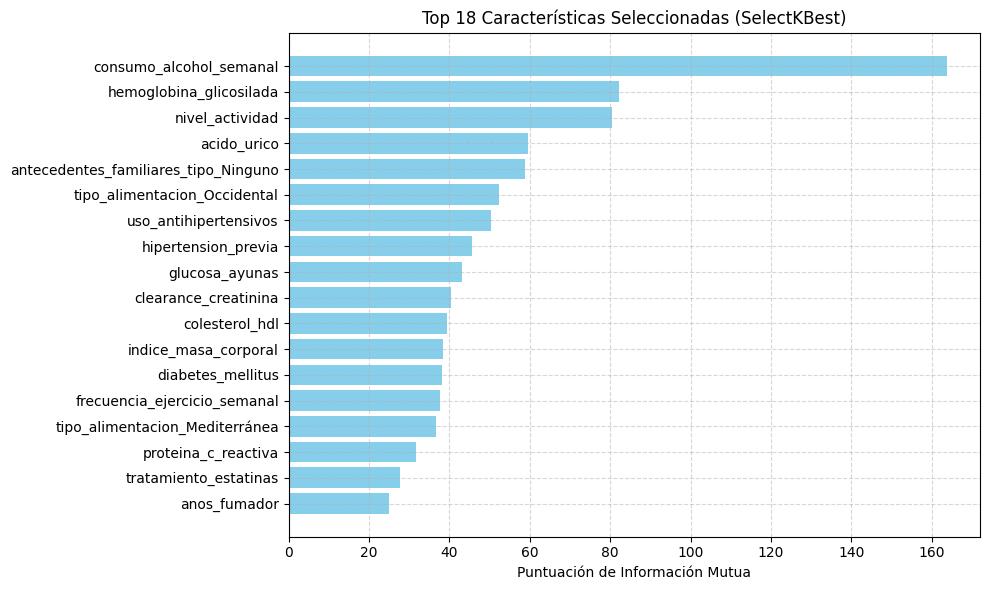

In [137]:
# 1. Obtener las puntuaciones y los nombres de las variables seleccionadas
scores_seleccionados = selector.scores_[selector.get_support()]
nombres_seleccionados = all_feature_names[selector.get_support()]

# 2. Ordenar de mayor a menor para la gráfica
indices_ordenados = np.argsort(scores_seleccionados)

# 3. Graficar
plt.figure(figsize=(10, 6))
plt.barh(
    range(len(indices_ordenados)),
    scores_seleccionados[indices_ordenados],
    color="skyblue",
)
plt.yticks(
    range(len(indices_ordenados)), nombres_seleccionados[indices_ordenados]
)
plt.xlabel("Puntuación de Información Mutua")
plt.title("Top 18 Características Seleccionadas (SelectKBest)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### 6.6 Desbalanceo

En nuestro problema existen clases con muchos más ejemplos que otras.

Si algunos niveles de riesgo cardiovascular están mucho más representados que otros, el modelo podría aprender a favorecer las clases mayoritarias y obtener resultados engañosamente buenos. Por ello, se analizará la distribución de la variable objetivo y, si es necesario, se aplicarán técnicas para compensar dicho desequilibrio.

Como podemos ver, el 50% de las instancias se corresponden a la clase 0. Esto es un problema grave, ya que si creamos un modelo que simplemente responda que la clase esperada es la 0 siempre, acertaría 1 de cada 2 veces.

In [138]:
display(reparto.round(1))

,dataset limpio,entrenamiento,test
0 - bajo,50.0,49.9,50.0
1 - moderado,30.0,30.0,30.0
2 - alto,20.0,20.1,20.0


Vamos a empezar, aplicando SMOTE, para equilibrar el número de instancias. 

In [139]:
import pandas as pd
from imblearn.over_sampling import SMOTE

# 1. Aplicar SMOTE primero para equilibrar las clases minoritarias en Train
# Revisar el conteo exacto actual en y_train
conteo_actual = pd.Series(y_train).value_counts().sort_index()
# Definir una estrategia intermedia (ej. llevar las minoritarias al 65% de la mayoritaria)
clase_mayoritaria_n = conteo_actual.max()
objetivo_minoritarias = int(clase_mayoritaria_n * 0.65)
smote = SMOTE(random_state=SEMILLA, sampling_strategy={1:objetivo_minoritarias , 2: objetivo_minoritarias})
X_train_smote, y_train_smote = smote.fit_resample(X_train_selected, y_train)

print("Distribución original en Train:\n", pd.Series(y_train).value_counts())
print("\nDistribución tras SMOTE:\n", pd.Series(y_train_smote).value_counts())

Distribución original en Train:
 riesgo_cardiovascular
0    899
1    540
2    361
Name: count, dtype: int64

Distribución tras SMOTE:
 riesgo_cardiovascular
0    899
1    584
2    584
Name: count, dtype: int64


Llegados a este punto, podemos plantearnos si es necesario aplicar alguna técnica más de desbalanceo. Para poder tomar una decisión, vamos a aprovechar para entrenar el primer modelo, usando una regresión logística. Luego aplicaremos NeighbourhoodCleaningRule, y volveremos a entrenar el modelo, para ver si nos interesa aplicar ambas técnicas o solo una de ellas.

--- Reporte de Clasificación ---
              precision    recall  f1-score   support

           0     0.8106    0.8178    0.8142       225
           1     0.4954    0.4000    0.4426       135
           2     0.6053    0.7667    0.6765        90

    accuracy                         0.6822       450
   macro avg     0.6371    0.6615    0.6444       450
weighted avg     0.6750    0.6822    0.6752       450



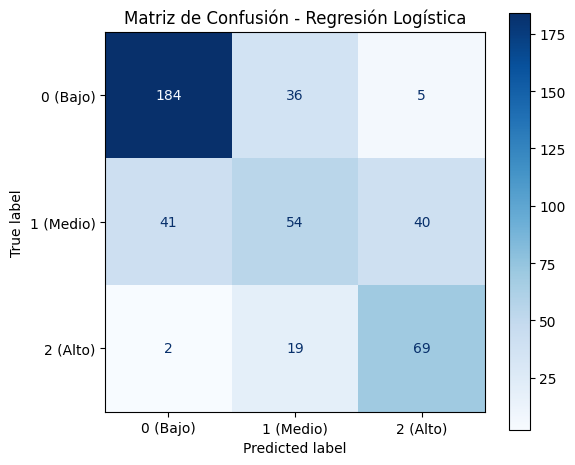

In [140]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

# 1. Instanciar el modelo de Regresión Logística Multinomial (Softmax)
# Nota: En versiones recientes de scikit-learn (>= 1.5), multinomial (Softmax) es el comportamiento por defecto
# cuando hay más de 2 clases, por lo que no es necesario pasar multi_class='multinomial' (parámetro deprecado).
log_reg = LogisticRegression(
    solver="lbfgs",  # Optimizador estándar que soporta Softmax multiclase
    max_iter=1000,  # Iteraciones suficientes para asegurar convergencia
    random_state=SEMILLA,
)

# 2. Entrenar el modelo con los datos de entrenamiento 
log_reg.fit(X_train_smote, y_train_smote)

# 3. Predecir clases 
y_test_pred = log_reg.predict(X_test_selected)

# 4. Evaluar métricas en Validación
print("--- Reporte de Clasificación ---")
print(classification_report(y_test, y_test_pred, digits=4))

# 5. Visualizar la Matriz de Confusión
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["0 (Bajo)", "1 (Medio)", "2 (Alto)"],
    cmap="Blues",
    ax=ax,
)
plt.title("Matriz de Confusión - Regresión Logística")
plt.tight_layout()
plt.show()

In [141]:
from imblearn.under_sampling import NeighbourhoodCleaningRule

# Aplicar NCL después para limpiar el ruido
# Se eliminan los vecinos de las clases mayoritarias que puedan introducir ruido
ncl = NeighbourhoodCleaningRule(n_neighbors=3) # n=3. Valor por defecto (más recomendado)
X_train_final, y_train_final = ncl.fit_resample(X_train_smote, y_train_smote)

# Verificar la distribución resultante
print(
    "\nDistribución final tras SMOTE + NCL:\n",
    pd.Series(y_train_final).value_counts(),
)


Distribución final tras SMOTE + NCL:
 riesgo_cardiovascular
1    584
0    495
2    308
Name: count, dtype: int64


Se han eliminado muchas instancias de C0 y C2, pero pocas de C1. 

--- Reporte de Clasificación ---
              precision    recall  f1-score   support

           0     0.8650    0.6267    0.7268       225
           1     0.4404    0.7111    0.5439       135
           2     0.6957    0.5333    0.6038        90

    accuracy                         0.6333       450
   macro avg     0.6670    0.6237    0.6248       450
weighted avg     0.7038    0.6333    0.6473       450



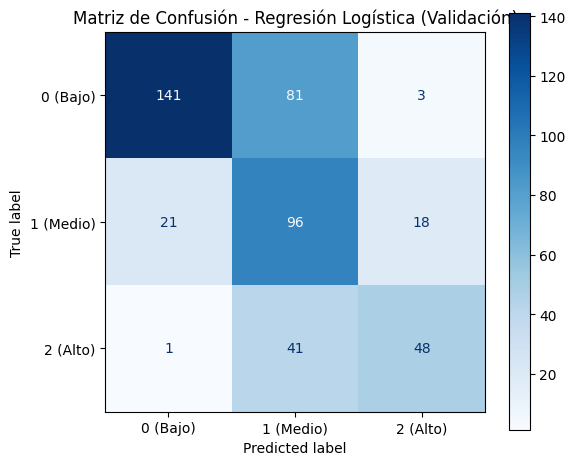

In [ ]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

# 1. Instanciar el modelo de Regresión Logística Multinomial (Softmax)
# Nota: En versiones recientes de scikit-learn (>= 1.5), multinomial (Softmax) es el comportamiento por defecto
# cuando hay más de 2 clases, por lo que no es necesario pasar multi_class='multinomial' (parámetro deprecado).
log_reg = LogisticRegression(
    solver="lbfgs",  # Optimizador estándar que soporta Softmax multiclase
    max_iter=1000,  # Iteraciones suficientes para asegurar convergencia
    random_state=SEMILLA,
)

# 2. Entrenar el modelo con los datos de entrenamiento finales. Aplicado SMOTE y NCL.
log_reg.fit(X_train_final, y_train_final)

# 3. Predecir clases
y_test_pred = log_reg.predict(X_test_selected) # Primero aplica softmax y luego elige el de mayor probabilidad

# 4. Evaluar métricas 
print("--- Reporte de Clasificación ---")
print(classification_report(y_test, y_test_pred, digits=4))

# 5. Visualizar la Matriz de Confusión
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["0 (Bajo)", "1 (Medio)", "2 (Alto)"],
    cmap="Blues",
    ax=ax,
)
plt.title("Matriz de Confusión - Regresión Logística (Validación)")
plt.tight_layout()
plt.show()

Analizando los resultados observamos que: 

- Los recalls de c0 y c2 se han desplomado. Esto es porque NCL elimina muchos pacientes en la frontera y se vuelve muy conservador con esas clases, por eso aumenta la precisión. El recall de C1 casi se dobla.

- Hay una mejora de la precisión en C0 y C2, y una pérdida en C1.

A partir de estos resultados, vamos a optar por no usar NCL. La subida en la precisión no compensa la gran pérdida en el recall.

Por tanto, nos quedamos con el conjunto de entrenamiento (X_train_smote, y_train_smote).

Vamos ahora a ajustar los hiperparámetros para el clasificador por regresión logística.

Vamos a probar todas las opciones y nos quedamos con la combinación que nos de el mejor Macro F1 y Recall C2 (entendiendo las clases como C0=bajo riesgo, C1=nivel medio y C2=alto riesgo).

# 7. DISEÑO Y ENTRENAMIENTO DE MODELOS

1. Modelo 1. Regresión logística.
2. Modelo 2. K-Nearest Neighbors

Parámetros: (0.01, 'lbfgs') --> Macro F1: 0.5997 | Recall Clase 2: 0.7889
Parámetros: (0.01, 'newton-cg') --> Macro F1: 0.5997 | Recall Clase 2: 0.7889
Parámetros: (0.1, 'lbfgs') --> Macro F1: 0.6315 | Recall Clase 2: 0.7667
Parámetros: (0.1, 'newton-cg') --> Macro F1: 0.6315 | Recall Clase 2: 0.7667
Parámetros: (1.0, 'lbfgs') --> Macro F1: 0.6444 | Recall Clase 2: 0.7667
Parámetros: (1.0, 'newton-cg') --> Macro F1: 0.6444 | Recall Clase 2: 0.7667
Parámetros: (10.0, 'lbfgs') --> Macro F1: 0.6471 | Recall Clase 2: 0.7667
Parámetros: (10.0, 'newton-cg') --> Macro F1: 0.6471 | Recall Clase 2: 0.7667
Mejor Macro F1: 0.5997 | Recall Clase 2: 0.7889 -> Mejores hiperparámetros: (0.01, 'lbfgs')

--- Reporte de Clasificación (Validación) ---
              precision    recall  f1-score   support

           0     0.7638    0.8622    0.8100       225
           1     0.4857    0.2519    0.3317       135
           2     0.5635    0.7889    0.6574        90

    accuracy                         0.

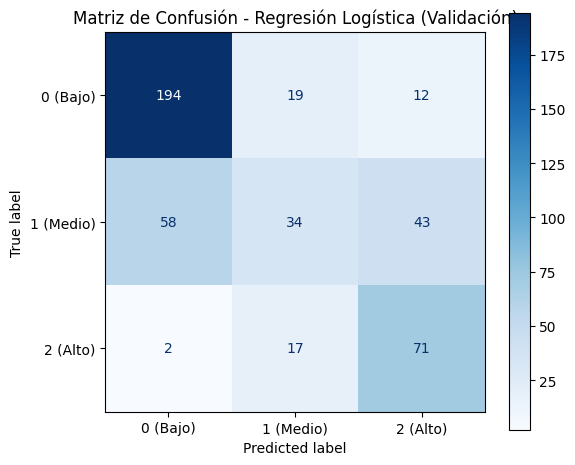

In [155]:
# Vamos a buscar los mejores hiperparámetros para log_reg

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, recall_score

grid_lr = {
    "C": [0.01, 0.1, 1.0, 10.0],
    "solver": ["lbfgs", "newton-cg"],
    "max_iter": [1000],
    "random_state": SEMILLA,
}

mejor_f1 = -1
mejor_recall = -1
for c in grid_lr["C"][:]:
    for s in grid_lr["solver"][:]:

        log_reg = LogisticRegression(
            C=c,    
            solver=s,  
            max_iter=1000,  
            random_state=SEMILLA)

        # Entrenar el modelo con los datos de entrenamiento 
        log_reg.fit(X_train_smote, y_train_smote)

        # Predecir clases y probabilidades en el conjunto de Validación
        y_test_pred = log_reg.predict(X_test_selected)

        macro_f1 = f1_score(y_test, y_test_pred, average="macro")
        # labels=[2] - Clase C2 - Creará vector con un solo valor (C2)
        # average=None - No se hace media, se genera un vector y de dicho vector cogemos el valor [0] = Recall C2
        recall_c2 = recall_score(y_test, y_test_pred, labels=[2], average=None)[0]

        print(f"Parámetros: {c,s} --> Macro F1: {macro_f1:.4f} | Recall Clase 2: {recall_c2:.4f}")

        # Condición 1 --> Mejora estrictamente el Macro F1 sin empeorar el Recall C2
        mejora_f1 = (macro_f1 > mejor_f1) and (recall_c2 >= mejor_recall)

        # Condición 2 -> Mejora el Recall C2 sin que el Macro F1 caiga más de 0.05 puntos respecto al mejor
        mejora_recall_c2 = (recall_c2 > mejor_recall) and (macro_f1 >= mejor_f1 - 0.05)

        if mejora_f1 or mejora_recall_c2:
            mejor_f1 = macro_f1
            mejor_recall = recall_c2
            mejor_c = c
            mejor_solver = s

print(f"Mejor Macro F1: {mejor_f1:.4f} | Recall Clase 2: {mejor_recall:.4f} -> Mejores hiperparámetros: {mejor_c, mejor_solver}\n")

# Entrenamos con los mejores hiperparámetros

log_reg = LogisticRegression(
            C=mejor_c,    
            solver=mejor_solver,  
            max_iter=1000,  
            random_state=SEMILLA)

# Entrenar el modelo con los datos de entrenamiento 
log_reg.fit(X_train_smote, y_train_smote)

# Predecir clases
y_test_pred_lr = log_reg.predict(X_test_selected)

# Evaluar métricas en Validación
print("--- Reporte de Clasificación (Validación) ---")
print(classification_report(y_test, y_test_pred_lr, digits=4))

# Visualizar la Matriz de Confusión
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_lr,
    display_labels=["0 (Bajo)", "1 (Medio)", "2 (Alto)"],
    cmap="Blues",
    ax=ax,
)
plt.title("Matriz de Confusión - Regresión Logística (Validación)")
plt.tight_layout()
plt.show()

Parámetros: (5, 'uniform', 'euclidean') --> Macro F1: 0.5518 | Recall Clase 2: 0.5778
Parámetros: (5, 'uniform', 'manhattan') --> Macro F1: 0.5731 | Recall Clase 2: 0.5333
Parámetros: (5, 'distance', 'euclidean') --> Macro F1: 0.5503 | Recall Clase 2: 0.6111
Parámetros: (5, 'distance', 'manhattan') --> Macro F1: 0.5979 | Recall Clase 2: 0.6111
Parámetros: (11, 'uniform', 'euclidean') --> Macro F1: 0.5983 | Recall Clase 2: 0.7333
Parámetros: (11, 'uniform', 'manhattan') --> Macro F1: 0.6002 | Recall Clase 2: 0.6111
Parámetros: (11, 'distance', 'euclidean') --> Macro F1: 0.5941 | Recall Clase 2: 0.7333
Parámetros: (11, 'distance', 'manhattan') --> Macro F1: 0.6095 | Recall Clase 2: 0.6333
Parámetros: (15, 'uniform', 'euclidean') --> Macro F1: 0.5764 | Recall Clase 2: 0.7444
Parámetros: (15, 'uniform', 'manhattan') --> Macro F1: 0.5609 | Recall Clase 2: 0.6111
Parámetros: (15, 'distance', 'euclidean') --> Macro F1: 0.5784 | Recall Clase 2: 0.7444
Parámetros: (15, 'distance', 'manhattan') 

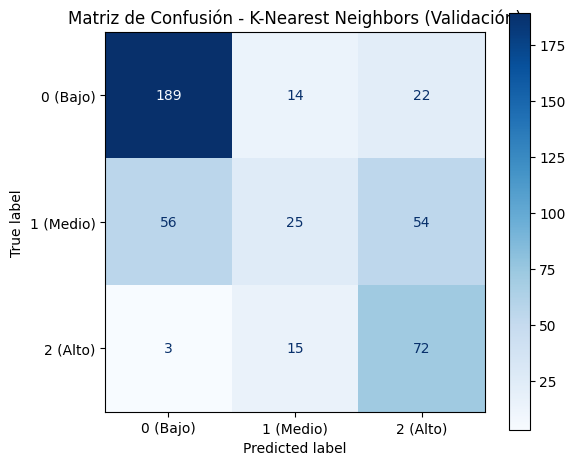

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.neighbors import KNeighborsClassifier

# KNeighborsClassifier exige normalización, para que el cálculo de distancias tenga sentido

grid_knn = {
    "n_neighbors": [5, 11, 15, 21, 31], # Define cuántos pacientes más cercanos consulta el modelo para decidir la clase de un nuevo paciente.
    "weights": ["uniform", "distance"], # uniform: democracia pura, distance: inverso de la distancia (vecinos más cercanos, tienen más peso)
    "metric": ["euclidean", "manhattan"], # fórmula para medir la distancia. No se elige minkowski porque generaría inconsistencias con el parámetro p!=3
}

# Triple for para detectar cuáles son los mejores hiperparámetros.

mejor_f1 = -1
mejor_recall = -1
for n in grid_knn["n_neighbors"][:]:
    for w in grid_knn["weights"][:]:
        for m in grid_knn["metric"][:]:

            # 1. Instanciar el modelo K-Nearest Neighbors (KNN)
            knn = KNeighborsClassifier(n_neighbors=n, weights=w, metric=m)

            # 2. Entrenar el modelo con los datos balanceados y limpios
            knn.fit(X_train_smote, y_train_smote)

            # 3. Predecir clases y probabilidades en el conjunto de Validación
            y_test_pred_knn = knn.predict(X_test_selected)

            macro_f1 = f1_score(y_test, y_test_pred_knn, average="macro") # macro: media aritmética (33% cada clase)
            recall_c2 = recall_score(y_test, y_test_pred_knn, labels=[2], average=None)[0]
    
            print(f"Parámetros: {n,w,m} --> Macro F1: {macro_f1:.4f} | Recall Clase 2: {recall_c2:.4f}")
    
            # Condición 1 --> Mejora estrictamente el Macro F1 sin empeorar el Recall C2
            mejora_f1 = (macro_f1 > mejor_f1) and (recall_c2 >= mejor_recall)
    
            # Condición 2 -> Mejora el Recall C2 sin que el Macro F1 caiga más de 0.05 puntos respecto al mejor
            mejora_recall_c2 = (recall_c2 > mejor_recall) and (macro_f1 >= mejor_f1 - 0.05)
    
            if mejora_f1 or mejora_recall_c2:
                mejor_f1 = macro_f1
                mejor_recall = recall_c2
                mejor_n = n
                mejor_w = w
                mejor_m = m
            
print(f"Mejor Macro F1: {mejor_f1:.4f} | Recall Clase 2: {mejor_recall:.4f} -> Mejores hiperparámetros: {mejor_n,mejor_w,mejor_m}\n")

# 1. Instanciar el modelo K-Nearest Neighbors (KNN)
knn = KNeighborsClassifier(n_neighbors=mejor_n, weights=mejor_w, metric=mejor_m)

# 2. Entrenar el modelo con los datos balanceados y limpios
knn.fit(X_train_smote, y_train_smote)

# 3. Predecir clases
y_test_pred_knn = knn.predict(X_test_selected)

# 4. Evaluar métricas en Validación
print("--- Reporte de Clasificación - KNN ---")
print(classification_report(y_test, y_test_pred_knn, digits=4))

# 5. Visualizar la Matriz de Confusión
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_knn,
    display_labels=["0 (Bajo)", "1 (Medio)", "2 (Alto)"],
    cmap="Blues",
    ax=ax,
)
plt.title("Matriz de Confusión - K-Nearest Neighbors (Validación)")
plt.tight_layout()
plt.show()

Una vez trabajado con los modelos básicos, vamos a empezar a trabajar con los modelos de Ensamble.

# Primer modelo de Ensamble -> RandomForest

- Árboles en paralelo

Parámetros: (100, None, 2, None) --> Macro F1: 0.6188 | Recall Clase 2: 0.7000
Parámetros: (100, None, 2, 'balanced_subsample') --> Macro F1: 0.6086 | Recall Clase 2: 0.6556
Parámetros: (100, None, 5, None) --> Macro F1: 0.6007 | Recall Clase 2: 0.7000
Parámetros: (100, None, 5, 'balanced_subsample') --> Macro F1: 0.6278 | Recall Clase 2: 0.7000
Parámetros: (100, 5, 2, None) --> Macro F1: 0.5359 | Recall Clase 2: 0.7556
Parámetros: (100, 5, 2, 'balanced_subsample') --> Macro F1: 0.6300 | Recall Clase 2: 0.7778
Parámetros: (100, 5, 5, None) --> Macro F1: 0.5520 | Recall Clase 2: 0.7778
Parámetros: (100, 5, 5, 'balanced_subsample') --> Macro F1: 0.6117 | Recall Clase 2: 0.7556
Parámetros: (100, 10, 2, None) --> Macro F1: 0.5932 | Recall Clase 2: 0.7000
Parámetros: (100, 10, 2, 'balanced_subsample') --> Macro F1: 0.6175 | Recall Clase 2: 0.6778
Parámetros: (100, 10, 5, None) --> Macro F1: 0.6155 | Recall Clase 2: 0.7111
Parámetros: (100, 10, 5, 'balanced_subsample') --> Macro F1: 0.6270 |

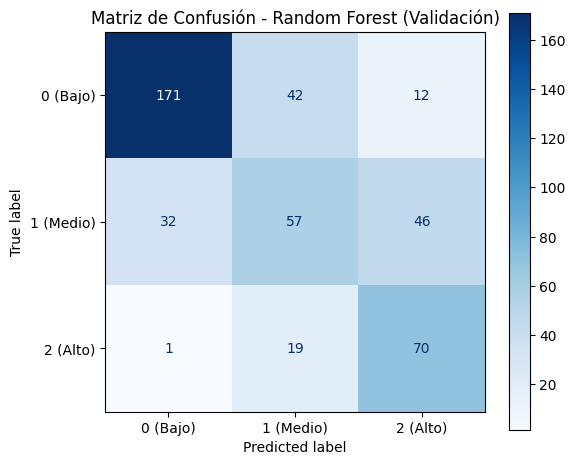

In [ ]:
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

grid_rf = {
    "n_estimators": [100, 150, 200],
    "max_depth": [None, 5, 10, 15],
    "min_samples_leaf": [2, 5],
    "class_weight": [None, "balanced_subsample"]
}

mejor_f1 = -1
mejor_recall = -1
for n in grid_rf["n_estimators"][:]:
    for max in grid_rf["max_depth"][:]:
        for min in grid_rf["min_samples_leaf"][:]:
            for c in grid_rf["class_weight"][:]:

                # 1. Instanciar el modelo de Bagging (Random Forest)
                rf = RandomForestClassifier(
                    n_estimators=n,  # Número de árboles en el ensamble
                    max_depth=max,  # Limita la profundidad para evitar sobreajustar a los puntos sintéticos de SMOTE
                    min_samples_leaf=min,  # Exige al menos min_pacientes por hoja para suavizar fronteras
                    class_weight=c,
                    random_state=SEMILLA,
                    n_jobs=-1,  # Usa todos los núcleos disponibles del procesador
                )

                # 2. Entrenar el modelo con los datos balanceados y limpios 
                rf.fit(X_train_smote, y_train_smote)

                # 3. Predecir clases 
                y_test_pred_rf = rf.predict(X_test_selected)

                macro_f1 = f1_score(y_test, y_test_pred_rf, average="macro") # macro: media aritmética (33% cada clase)
                recall_c2 = recall_score(y_test, y_test_pred_rf, labels=[2], average=None)[0]
        
                print(f"Parámetros: {n,max,min,c} --> Macro F1: {macro_f1:.4f} | Recall Clase 2: {recall_c2:.4f}")
        
                # Condición 1 --> Mejora estrictamente el Macro F1 sin empeorar el Recall C2
                mejora_f1 = (macro_f1 > mejor_f1) and (recall_c2 >= mejor_recall)
        
                # Condición 2 -> Mejora el Recall C2 sin que el Macro F1 caiga más de 0.05 puntos respecto al mejor
                mejora_recall_c2 = (recall_c2 > mejor_recall) and (macro_f1 >= mejor_f1 - 0.05)
        
                if mejora_f1 or mejora_recall_c2:
                    mejor_f1 = macro_f1
                    mejor_recall = recall_c2
                    mejor_n = n
                    mejor_max = max
                    mejor_min = min
                    mejor_c = c
                            
print(f"Mejor Macro F1: {mejor_f1:.4f} | Recall Clase 2: {mejor_recall:.4f} -> Mejores hiperparámetros: {mejor_n,mejor_max,mejor_min,mejor_c}\n")

# 1. Instanciar el modelo de Bagging (Random Forest)
rf = RandomForestClassifier(
    n_estimators=mejor_n,  # Número de árboles en el ensamble
    max_depth=mejor_max,  # Limita la profundidad para evitar sobreajustar a los puntos sintéticos de SMOTE
    min_samples_leaf=mejor_min,  # Exige al menos min_pacientes por hoja para suavizar fronteras
    class_weight=mejor_c,
    random_state=SEMILLA,
    n_jobs=-1,  # Usa todos los núcleos disponibles del procesador
)

# 2. Entrenar el modelo con los datos balanceados y limpios 
rf.fit(X_train_smote, y_train_smote)

# 3. Predecir clases y probabilidades en el conjunto de Validación
y_test_pred_rf = rf.predict(X_test_selected)

# 4. Evaluar métricas en Validación
print("--- Reporte de Clasificación - Random Forest / Bagging ---")
print(classification_report(y_test, y_test_pred_rf, digits=4))

# 5. Visualizar la Matriz de Confusión
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_rf,
    display_labels=["0 (Bajo)", "1 (Medio)", "2 (Alto)"],
    cmap="Blues",
    ax=ax,
)
plt.title("Matriz de Confusión - Random Forest (Validación)")
plt.tight_layout()
plt.show()

# Segundo Modelo de Ensamble -> Boosting

- Árboles secuenciales

Parámetros: (150, 0.03, 4, 5, 2.0) --> Macro F1: 0.6247 | Recall Clase 2: 0.7000
Parámetros: (150, 0.03, 4, 10, 2.0) --> Macro F1: 0.6285 | Recall Clase 2: 0.7111
Parámetros: (150, 0.03, 4, 15, 2.0) --> Macro F1: 0.6149 | Recall Clase 2: 0.6778
Parámetros: (150, 0.03, 6, 5, 2.0) --> Macro F1: 0.6209 | Recall Clase 2: 0.7000
Parámetros: (150, 0.03, 6, 10, 2.0) --> Macro F1: 0.6189 | Recall Clase 2: 0.7111
Parámetros: (150, 0.03, 6, 15, 2.0) --> Macro F1: 0.6231 | Recall Clase 2: 0.6556
Parámetros: (150, 0.03, 8, 5, 2.0) --> Macro F1: 0.6383 | Recall Clase 2: 0.6778
Parámetros: (150, 0.03, 8, 10, 2.0) --> Macro F1: 0.6412 | Recall Clase 2: 0.7111
Parámetros: (150, 0.03, 8, 15, 2.0) --> Macro F1: 0.6270 | Recall Clase 2: 0.7000
Parámetros: (150, 0.05, 4, 5, 2.0) --> Macro F1: 0.6125 | Recall Clase 2: 0.6667
Parámetros: (150, 0.05, 4, 10, 2.0) --> Macro F1: 0.6132 | Recall Clase 2: 0.6778
Parámetros: (150, 0.05, 4, 15, 2.0) --> Macro F1: 0.6226 | Recall Clase 2: 0.7000
Parámetros: (150, 0.

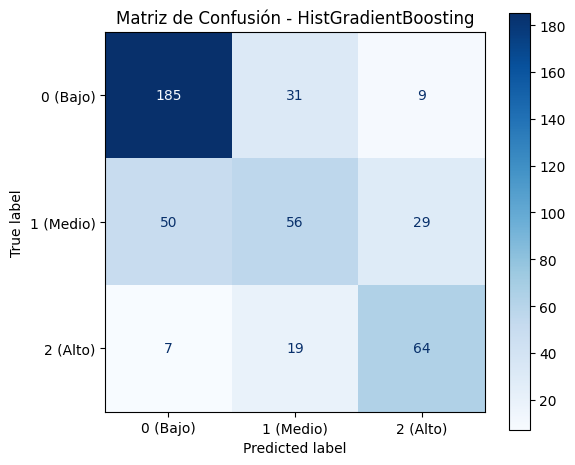

In [152]:
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

# Probar todos los hiperparámetros para conocer cuáles son los mejores, en este entrenamiento es muy costoso,
# por lo que una vez analizados durante una ejecución, vamos a reducir las opciones, en base a los resultados
# obtenidos. 
grid_hgb = {
    "max_iter": [150], # Nos quedamos con la opción de 250 árboles
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [4, 6, 8],
    "min_samples_leaf": [5, 10, 15], # 1 en RandomForest
    "l2_regularization": [2.0], # Nos quedamos con la regularización más fuerte, para suavizar los pesos de las hojas y reducir el riesgo de sobreajuste (overfitting)
    "random_state": [SEMILLA],
}

mejor_f1 = -1
mejor_recall = -1
for max_i in grid_hgb["max_iter"][:]:
    for lea in grid_hgb["learning_rate"][:]:
        for max_d in grid_hgb["max_depth"][:]:
            for min in grid_hgb["min_samples_leaf"][:]:
                for l2 in grid_hgb["l2_regularization"][:]:

                    # 1. Instanciar el modelo de Boosting (HistGradientBoosting)
                    hgb = HistGradientBoostingClassifier(
                        max_iter=max_i,  # Número de iteraciones de boosting (árboles secuenciales)
                        learning_rate=lea,  # Tasa de aprendizaje 
                        max_depth=max_d,  # Controla la complejidad de las interacciones entre variables
                        min_samples_leaf=min,  
                        l2_regularization=l2,  # Penalización L2 para mejorar la generalización en validación
                        random_state=SEMILLA,
                    )

                    # 2. Entrenar el modelo con los datos balanceados y limpios (SMOTE + NCL)
                    hgb.fit(X_train_smote, y_train_smote)

                    # 3. Predecir clases
                    y_test_pred_hgb = hgb.predict(X_test_selected)

                    macro_f1 = f1_score(y_test, y_test_pred_hgb, average="macro") # macro: media aritmética (33% cada clase)
                    recall_c2 = recall_score(y_test, y_test_pred_hgb, labels=[2], average=None)[0]
            
                    print(f"Parámetros: {max_i, lea,max_d,min,l2} --> Macro F1: {macro_f1:.4f} | Recall Clase 2: {recall_c2:.4f}")
            
                    # Condición 1 --> Mejora estrictamente el Macro F1 sin empeorar el Recall C2
                    mejora_f1 = (macro_f1 > mejor_f1) and (recall_c2 >= mejor_recall)
            
                    # Condición 2 -> Mejora el Recall C2 sin que el Macro F1 caiga más de 0.05 puntos respecto al mejor
                    mejora_recall_c2 = (recall_c2 > mejor_recall) and (macro_f1 >= mejor_f1 - 0.05)
            
                    if mejora_f1 or mejora_recall_c2:
                        mejor_f1 = macro_f1
                        mejor_recall = recall_c2
                        mejor_max_i = max_i
                        mejor_lea = lea
                        mejor_max_d = max_d
                        mejor_min = min
                        mejor_l2 = l2
                                                
print(f"Mejor Macro F1: {mejor_f1:.4f} | Recall Clase 2: {mejor_recall:.4f} -> Mejores hiperparámetros: {mejor_max_i, mejor_lea,mejor_max_d,mejor_min,mejor_l2}\n")

# 1. Instanciar el modelo de Boosting (HistGradientBoosting)
hgb = HistGradientBoostingClassifier(
    max_iter=max_i,  # Número de iteraciones de boosting (árboles secuenciales)
    learning_rate=mejor_lea,  # Tasa de aprendizaje moderada para evitar memorizar puntos de SMOTE
    max_depth=mejor_max_d,  # Controla la complejidad de las interacciones entre variables
    min_samples_leaf=mejor_min,  # Evita crear hojas demasiado pequeñas sobre ruido sintético
    l2_regularization=2.0,  # Penalización L2 para mejorar la generalización en validación
    random_state=SEMILLA,
)

# 2. Entrenar el modelo con los datos balanceados y limpios
hgb.fit(X_train_smote, y_train_smote)

# 3. Predecir clases 
y_test_pred_hgb = hgb.predict(X_test_selected)

# 4. Evaluar métricas
print("--- Reporte de Clasificación - HistGradientBoosting ---")
print(classification_report(y_test, y_test_pred_hgb, digits=4))

# 5. Visualizar la Matriz de Confusión
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_hgb,
    display_labels=["0 (Bajo)", "1 (Medio)", "2 (Alto)"],
    cmap="Blues",
    ax=ax,
)
plt.title("Matriz de Confusión - HistGradientBoosting")
plt.tight_layout()
plt.show()

# Tercer modelo de Emsamble -> Stacking

Macro F1: 0.6214 | Recall Clase 2: 0.6778
--- Reporte de Clasificación - StackingClassifier (Validación) ---
              precision    recall  f1-score   support

           0     0.7611    0.8356    0.7966       225
           1     0.5050    0.3778    0.4322       135
           2     0.5980    0.6778    0.6354        90

    accuracy                         0.6667       450
   macro avg     0.6214    0.6304    0.6214       450
weighted avg     0.6517    0.6667    0.6550       450



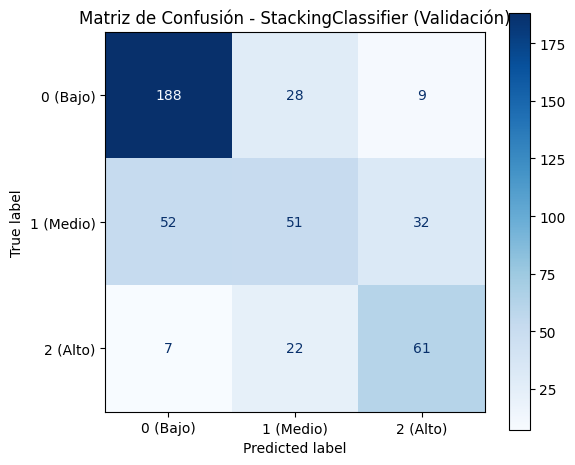

In [153]:
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier, StackingClassifier
# from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.neural_network import MLPClassifier

# 1. Definir los estimadores base que formarán el ensamble
estimators = [
    # Asignamos los mejores hiperparámetros obtenidos cuando se usó para entrenamiento
    (
        "hgb",
        HistGradientBoostingClassifier(
            max_iter=250,
            learning_rate=0.1,
            max_depth=6,
            min_samples_leaf=10,
            l2_regularization=2.0,
            random_state=SEMILLA,
        ),
    ),
    (
        "rf",
        RandomForestClassifier(
            n_estimators=150,
            max_depth=8,
            min_samples_leaf=10,
            class_weight="balanced_subsample",
            random_state=SEMILLA,
            n_jobs=-1,
        ),
    )#,
    # ("lr", LogisticRegression(C=0.1, solver='newton-cg', max_iter=1000, random_state=SEMILLA)),
    # Eliminado por ser el que peor recall_c2 obtiene
]

# 2. Instanciar el StackingClassifier con una Regresión Logística como meta-modelo
# Inicialmente opté por un final_estimator de LogisticRegression pero el recall de C2 era muy bajo.
# En segundo lugar, voy a probar con una MLP, para ver si aprende mejor las fronteras
stacking = StackingClassifier(
    estimators=estimators,
    # C bajo, permite que se clasifiquen como C2, predicciones con baja probabilidad de los estimadores
    # LogisticRegression(C=0.01, max_iter=1000, random_state=SEMILLA)
    final_estimator=MLPClassifier(
        hidden_layer_sizes=(8,),
        alpha=1.0,  # Regularización L2 fuerte
        max_iter=1000,
        random_state=SEMILLA,
    ),
    stack_method="predict_proba",  # Usa las probabilidades de cada modelo como entrada al meta-modelo
    cv=5,  # Valor estándar - Validación cruzada interna en train para evitar sobreajuste (k-pliegues)
    n_jobs=-1,
)

# 3. Entrenar el ensamble de Stacking sobre X_train_smote
stacking.fit(X_train_smote, y_train_smote)

# 4. Predecir en el conjunto de Validación
y_test_pred_stack = stacking.predict(X_test_selected)

macro_f1 = f1_score(y_test, y_test_pred_stack, average="macro") # macro: media aritmética (33% cada clase)
recall_c2 = recall_score(y_test, y_test_pred_stack, labels=[2], average=None)[0]

print(f"Macro F1: {macro_f1:.4f} | Recall Clase 2: {recall_c2:.4f}")

# 5. Evaluar métricas en Validación
print("--- Reporte de Clasificación - StackingClassifier (Validación) ---")
print(classification_report(y_test, y_test_pred_stack, digits=4))

# 6. Visualizar la Matriz de Confusión
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_stack,
    display_labels=["0 (Bajo)", "1 (Medio)", "2 (Alto)"],
    cmap="Blues",
    ax=ax,
)
plt.title("Matriz de Confusión - StackingClassifier (Validación)")
plt.tight_layout()
plt.show()

# 8. Comparativa de modelos

Vamos a usar las predicciones obtenidas por cada modelos, para compararlos entre sí.

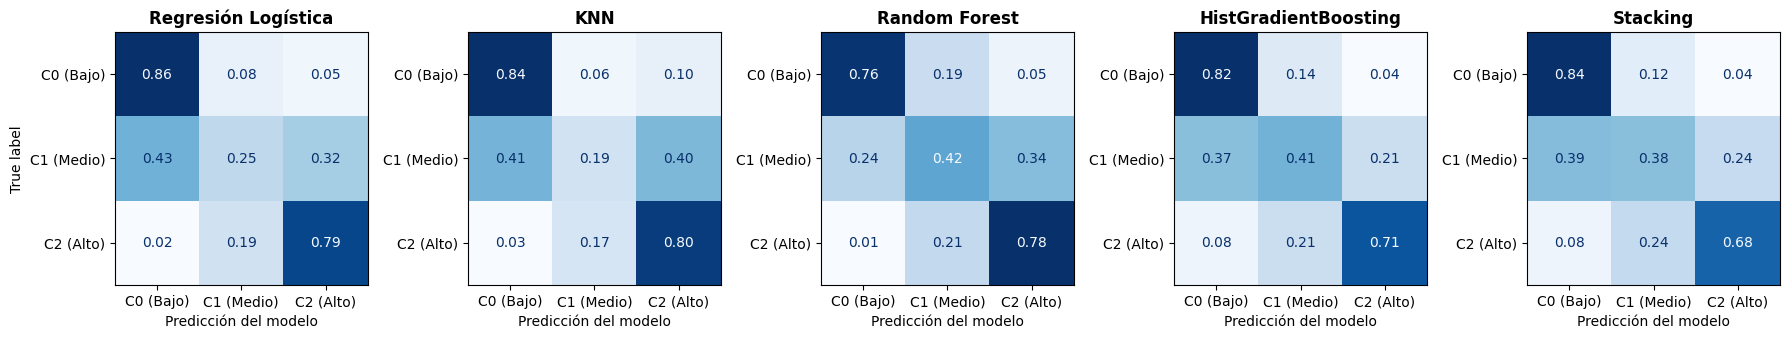

In [156]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

modelos = {
    "Regresión Logística": y_test_pred_lr,
    "KNN": y_test_pred_knn,
    "Random Forest": y_test_pred_rf,
    "HistGradientBoosting": y_test_pred_hgb,
    "Stacking": y_test_pred_stack
}

fig, axes = plt.subplots(1, len(modelos), figsize=(18, 4.5))

for ax, (nombre, y_pred) in zip(axes, modelos.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["C0 (Bajo)", "C1 (Medio)", "C2 (Alto)"],
        normalize="true",  # Muestra porcentajes por clase real (Recall en la diagonal)
        values_format=".2f",
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(nombre, fontweight="bold")
    ax.set_xlabel("Predicción del modelo")
    if ax != axes[0]:
        ax.set_ylabel("")

plt.tight_layout()
plt.show()

# 8.1 Comparativa de los modelos simples -> LR y KNN

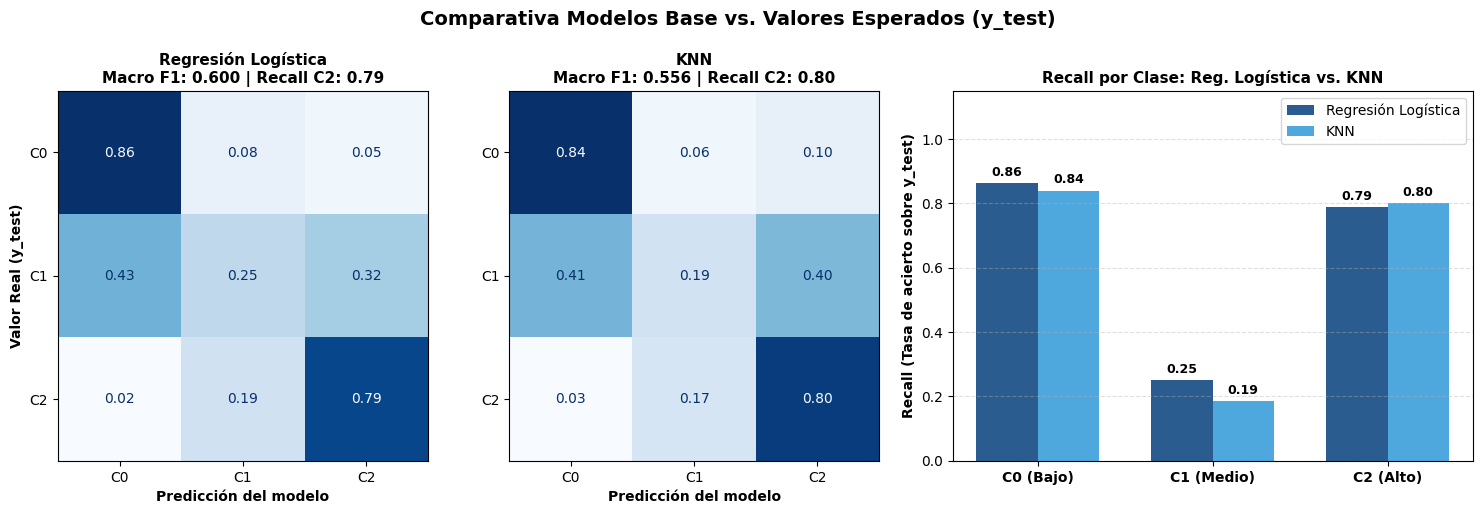

In [157]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay, f1_score, recall_score

# 1. Preparamos los datos del primer par de modelos
modelos_simples = {
    "Regresión Logística": y_test_pred_lr,  # Asegúrate de usar el nombre de tu variable
    "KNN": y_test_pred_knn,  # Asegúrate de usar el nombre de tu variable
}

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4.8),
    gridspec_kw={"width_ratios": [1, 1, 1.35]},
)

clases_labels = ["C0 (Bajo)", "C1 (Medio)", "C2 (Alto)"]
recalls_dict = {}

# 2. Dibujamos las Matrices de Confusión (Predicho vs. y_test)
for ax, (nombre, y_pred) in zip(axes[:2], modelos_simples.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["C0", "C1", "C2"],
        normalize="true",  # Normalizado por fila: la diagonal es el Recall real
        values_format=".2f",
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    macro_f1 = f1_score(y_test, y_pred, average="macro")
    rec_c2 = recall_score(y_test, y_pred, labels=[2], average=None)[0]

    ax.set_title(
        f"{nombre}\nMacro F1: {macro_f1:.3f} | Recall C2: {rec_c2:.2f}",
        fontweight="bold",
        fontsize=11,
    )
    ax.set_xlabel("Predicción del modelo", fontweight="bold")

    if ax == axes[0]:
        ax.set_ylabel("Valor Real (y_test)", fontweight="bold")
    else:
        ax.set_ylabel("")

    # Guardamos el Recall de las 3 clases
    recalls_dict[nombre] = recall_score(
        y_test, y_pred, labels=[0, 1, 2], average=None
    )

# 3. Dibujamos la comparativa directa de Recall por clase
ax_bar = axes[2]
x = np.arange(len(clases_labels))
ancho = 0.35

colores = ["#2b5c8f", "#4ea8de"]
for i, (nombre, recalls) in enumerate(recalls_dict.items()):
    offset = (i - 0.5) * ancho
    barras = ax_bar.bar(
        x + offset, recalls, width=ancho, label=nombre, color=colores[i]
    )
    ax_bar.bar_label(barras, fmt="%.2f", fontsize=9, padding=3, fontweight="bold")

ax_bar.set_xticks(x)
ax_bar.set_xticklabels(clases_labels, fontweight="bold")
ax_bar.set_ylim(0, 1.15)
ax_bar.set_ylabel("Recall (Tasa de acierto sobre y_test)", fontweight="bold")
ax_bar.set_title(
    "Recall por Clase: Reg. Logística vs. KNN", fontweight="bold", fontsize=11
)
ax_bar.grid(axis="y", linestyle="--", alpha=0.4)
ax_bar.legend(loc="upper right", frameon=True)

fig.suptitle(
    "Comparativa Modelos Base vs. Valores Esperados (y_test)",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

Como se observa, ambos modelos sufren mucho con la clase intermedia.

# 8.2 Comparativa de los modelos complejos -> RF, HGB y Stacking

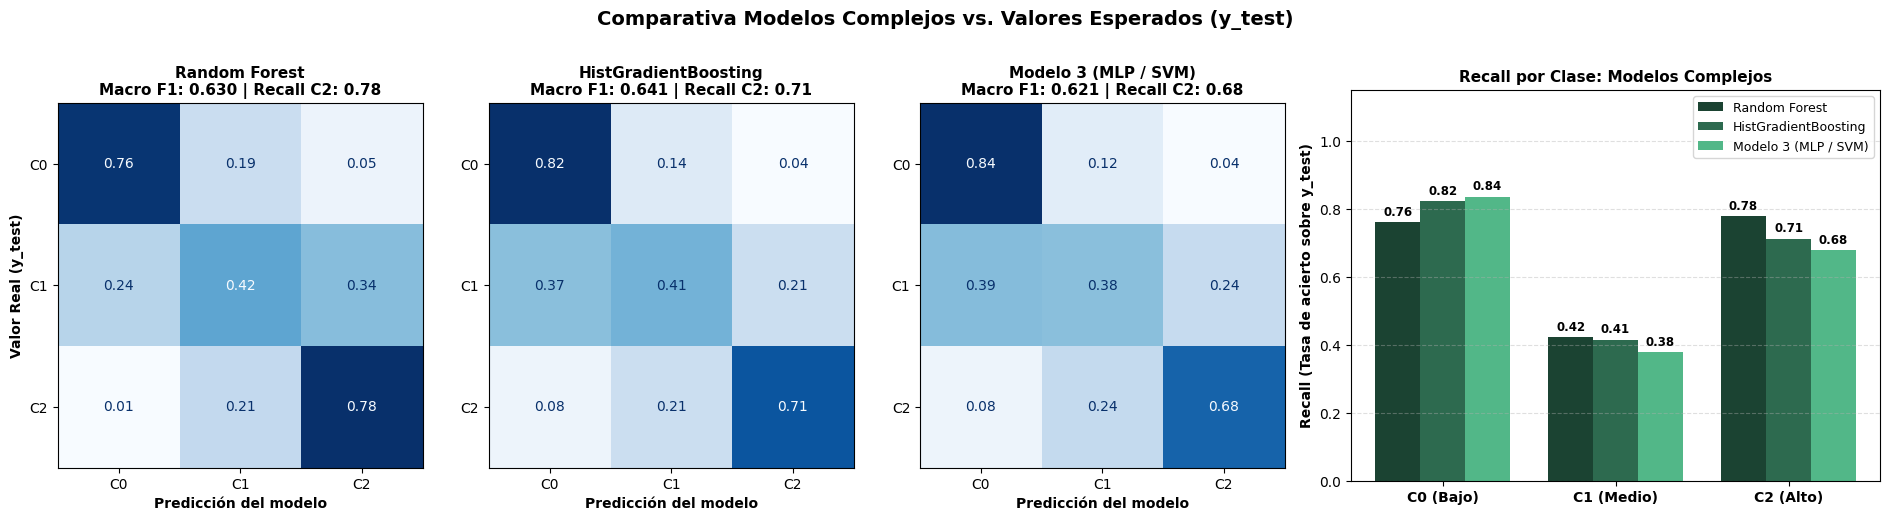

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay, f1_score, recall_score

# 1. Preparamos los datos de los 3 modelos complejos
# (Sustituye 'Modelo 3 (ej. MLP / XGB)' y 'y_pred_m3' por el nombre y variable de tu 3er modelo)
modelos_complejos = {
    "Random Forest": y_test_pred_rf,
    "HistGradientBoosting": y_test_pred_hgb,
    "Stacking": y_test_pred_stack,
}

fig, axes = plt.subplots(
    1,
    4,
    figsize=(19, 5),
    gridspec_kw={"width_ratios": [1, 1, 1, 1.45]},
)

clases_labels = ["C0 (Bajo)", "C1 (Medio)", "C2 (Alto)"]
recalls_dict = {}

# 2. Dibujamos las 3 Matrices de Confusión (Predicho vs. y_test)
for ax, (nombre, y_pred) in zip(axes[:3], modelos_complejos.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["C0", "C1", "C2"],
        normalize="true",  # Normalizado por fila: la diagonal es el Recall real
        values_format=".2f",
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    macro_f1 = f1_score(y_test, y_pred, average="macro")
    rec_c2 = recall_score(y_test, y_pred, labels=[2], average=None)[0]

    ax.set_title(
        f"{nombre}\nMacro F1: {macro_f1:.3f} | Recall C2: {rec_c2:.2f}",
        fontweight="bold",
        fontsize=11,
    )
    ax.set_xlabel("Predicción del modelo", fontweight="bold")

    if ax == axes[0]:
        ax.set_ylabel("Valor Real (y_test)", fontweight="bold")
    else:
        ax.set_ylabel("")

    # Guardamos el Recall de las 3 clases
    recalls_dict[nombre] = recall_score(
        y_test, y_pred, labels=[0, 1, 2], average=None
    )

# 3. Dibujamos la comparativa directa de Recall por clase (3 barras por clase)
ax_bar = axes[3]
x = np.arange(len(clases_labels))
ancho = 0.26

colores = ["#1b4332", "#2d6a4f", "#52b788"]  # Gama verde para diferenciar el bloque complejo
for i, (nombre, recalls) in enumerate(recalls_dict.items()):
    offset = (i - 1) * ancho
    barras = ax_bar.bar(
        x + offset, recalls, width=ancho, label=nombre, color=colores[i]
    )
    ax_bar.bar_label(barras, fmt="%.2f", fontsize=8.5, padding=3, fontweight="bold")

ax_bar.set_xticks(x)
ax_bar.set_xticklabels(clases_labels, fontweight="bold")
ax_bar.set_ylim(0, 1.15)
ax_bar.set_ylabel("Recall (Tasa de acierto sobre y_test)", fontweight="bold")
ax_bar.set_title(
    "Recall por Clase: Modelos Complejos", fontweight="bold", fontsize=11
)
ax_bar.grid(axis="y", linestyle="--", alpha=0.4)
ax_bar.legend(loc="upper right", frameon=True, fontsize=9)

fig.suptitle(
    "Comparativa Modelos Complejos vs. Valores Esperados (y_test)",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()